# Ансамблевые методы: прогнозирование оттока клиентов

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 1:** Введение в Data Science и EDA  
**Датасет:** Titanic  

**Выполнил:** Толмачев Виталий Владимирович 
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  

**Ссылка на репозиторий:** https://github.com/Dittalik/ml-course-tolmachev.git
**Путь к модулю:** `module-2-churn/notebook.ipynb`  
**Дата сдачи:** 2026-29-10

## Введение

**Какую задачу решаем.** Телеком-компания теряет клиентов, а удержать существующего обычно дешевле, чем привлечь нового. Мы решаем задачу **бинарной классификации**: по данным об абоненте (демография, подключённые услуги, условия контракта, платежи) предсказать, **уйдёт** клиент (`Churn = Yes`, класс 1) или **останется** (`No`, класс 0). Результат модели можно отдать отделу удержания, чтобы он работал с самыми рискованными клиентами.

**Что такое ансамблевые методы.** Это подход, при котором вместо одной модели обучают много (обычно простых, например неглубоких деревьев) и объединяют их ответы: усредняют или обучают модели последовательно, так что каждая следующая исправляет ошибки предыдущих.

**Почему ансамбли, а не одна модель.** Одно решающее дерево нестабильно: небольшое изменение данных сильно меняет его структуру (высокая дисперсия). Усреднение многих деревьев (bagging) снижает дисперсию, а последовательное исправление ошибок (boosting) снижает смещение. На табличных данных вроде нашего ансамбли деревьев обычно дают лучшее качество из «классических» методов и почти не требуют масштабирования признаков.

**Какая метрика важнее.**
- *Accuracy* здесь обманчива: при доле ушедших около 26,5% «модель», которая всегда отвечает «останется», получит около 73,5% точности и будет бесполезна.
- *F1* (баланс Precision/Recall) важна, когда нужно выбрать конкретный порог и сформировать список клиентов для кампании удержания.
- **ROC-AUC** оценивает качество *ранжирования* клиентов по риску независимо от порога и устойчива к дисбалансу, поэтому мы берём её **главной метрикой** (в том числе для подбора гиперпараметров). Остальные метрики показываем как дополнительные. Для бизнеса также важен **Recall** по классу «уйдёт»: пропущенный уходящий клиент обходится дороже, чем лишний звонок остающемуся.

**Цели работы:**
1. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по качеству и времени обучения.
2. Оптимизировать лучшую модель (LightGBM) байесовским поиском через Optuna.
3. Интерпретировать модель через Feature Importance и SHAP и сформулировать бизнес-выводы.

## Теоретическая часть

### Ансамбль
Ансамбль — это набор моделей («базовых алгоритмов»), чьи предсказания объединяются в одно итоговое. Идея в том, что ошибки разных моделей частично не совпадают, поэтому при объединении они взаимно гасятся. Ансамбль работает тем лучше, чем точнее отдельные модели и чем меньше они коррелируют между собой. Поэтому в ансамблях стараются добавить разнообразие: разные подвыборки объектов, разные подмножества признаков, разные параметры. Ансамбли применяют для снижения дисперсии (bagging), снижения смещения (boosting) или для объединения разнородных моделей (stacking, когда ответы базовых моделей подаются на вход «мета-модели»).

### Bagging vs Boosting
**Bagging** (bootstrap aggregating) обучает модели **независимо и параллельно**, каждую на своей бутстрэп-выборке (случайная выборка с возвращением), а затем усредняет ответы (или голосует). Он в первую очередь уменьшает дисперсию и хорошо работает с глубокими, склонными к переобучению деревьями. **Boosting** строит модели **последовательно**: каждая следующая обучается на ошибках уже построенной композиции и поправляет их. Он уменьшает смещение и обычно точнее, но чувствительнее к шуму и выбросам и требует аккуратной настройки (число итераций, скорость обучения, глубина).

$$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

Здесь $h_i(x)$ — базовая модель, $M$ — число моделей, $\alpha_i$ — вес (вклад) $i$-й модели. В градиентном бустинге на шаге $m$ добавляется модель, аппроксимирующая антиградиент функции потерь $L$: $F_m(x) = F_{m-1}(x) + \eta \, h_m(x)$, где $h_m$ обучена на «остатках» $-\partial L / \partial F_{m-1}$, а $\eta$ — скорость обучения (learning rate).

### Random Forest
Random Forest — это bagging над решающими деревьями с дополнительной рандомизацией: при поиске лучшего разбиения в каждом узле рассматривается только случайное подмножество признаков. Это делает деревья менее похожими друг на друга и снижает корреляцию между ними. Деревья обычно строят глубокими, а итоговый ответ — среднее вероятностей (или голосование). Особенности: устойчивость к переобучению, мало гиперпараметров, оценка важности признаков и возможность считать OOB-ошибку без отдельной валидации.

### Градиентный бустинг (XGBoost / LightGBM / CatBoost)
В градиентном бустинге деревья добавляются по одному, и каждое аппроксимирует антиградиент функции потерь текущей композиции. Современные библиотеки отличаются деталями реализации. **XGBoost** использует регуляризацию (L1/L2 на веса листьев), рост дерева по уровням и эффективную работу с пропусками. **LightGBM** строит дерево по листьям (leaf-wise), использует гистограммный метод и подвыборку по градиентам (GOSS), поэтому очень быстрый, но при малых данных может переобучиться из-за глубоких деревьев. **CatBoost** использует симметричные (oblivious) деревья и упорядоченный бустинг, который уменьшает утечку таргета, а также умеет работать с категориальными признаками «из коробки».

| Свойство | Random Forest | XGBoost | LightGBM | CatBoost |
|---|---|---|---|---|
| Тип ансамбля | Bagging | Boosting | Boosting | Boosting |
| Построение деревьев | независимо, параллельно | последовательно, по уровням | последовательно, по листьям | последовательно, симметричные деревья |
| Скорость обучения | средняя | средняя | **высокая** | ниже (на CPU) |
| Категориальные признаки | нужно кодировать | нужно кодировать | ограниченная поддержка | **нативная поддержка** |
| Риск переобучения | низкий | средний (есть регуляризация) | выше при малых данных | низкий (упорядоченный бустинг) |
| Настройка | почти не нужна | нужна | нужна | часто хорош «из коробки» |

### Optuna
Optuna — фреймворк для автоматического подбора гиперпараметров. Вместо полного перебора по сетке (Grid Search) или случайного поиска он использует **байесовскую оптимизацию**: по результатам прошлых испытаний (trials) строится вероятностная модель того, какие области пространства параметров перспективны (в Optuna по умолчанию алгоритм TPE — Tree-structured Parzen Estimator), и новые параметры выбираются именно оттуда. Преимущества: меньше испытаний для того же качества, гибкое описание пространства поиска в Python-коде (целые, вещественные, логарифмические шкалы), возможность ранней остановки неперспективных испытаний (pruning) и удобная визуализация.

### SHAP
SHAP основан на **значениях Шепли** из теории кооперативных игр: вклад признака в предсказание определяется как его средний предельный вклад по всем возможным порядкам добавления признаков. Для конкретного объекта сумма SHAP-значений всех признаков плюс базовое значение (среднее предсказание модели) равна предсказанию модели. Для деревьев есть быстрый точный алгоритм `TreeExplainer`. Основные графики: **summary plot** (глобальная важность и направление влияния каждого признака), **bar plot** (средний модуль SHAP), **waterfall plot** (разбор предсказания для одного клиента по шагам), **dependence plot** (как значение признака влияет на предсказание и с какими признаками взаимодействует). Для LightGBM SHAP-значения измеряются в **лог-шансах** (log-odds), а не напрямую в вероятности.

### Схема подходов
```
Bagging (Random Forest):   данные ─┬─ выборка 1 ─ дерево 1 ─┐
                                   ├─ выборка 2 ─ дерево 2 ─┼─► усреднение ─► ответ
                                   └─ выборка M ─ дерево M ─┘

Boosting (XGB/LGBM/Cat):   данные ─► дерево 1 ─► ошибки ─► дерево 2 ─► ошибки ─► ... ─► сумма деревьев ─► ответ

Stacking:                  модели 1..K ─► их предсказания ─► мета-модель ─► ответ
```

## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

Файл `WA_Fn-UseC_-Telco-Customer-Churn.csv` скачан с Kaggle и сохранён как `data/telco_churn.csv`. Ниже подключаем библиотеки и загружаем данные.

In [1]:
# Базовые библиотеки
import os  # работа с файлами и папками
import json  # чтение/запись JSON-файлов
import time  # замер времени обучения
import warnings  # управление предупреждениями

import numpy as np  # числовые массивы
import pandas as pd  # таблицы данных (DataFrame)
import matplotlib  # библиотека построения графиков
import matplotlib.pyplot as plt  # графики
import seaborn as sns  # статистические графики
import joblib  # сохранение и загрузка моделей
from IPython.display import Markdown, display   # красивый вывод Markdown-таблиц в ноутбуке

warnings.filterwarnings('ignore')            # убираем лишние предупреждения в выводе
sns.set_theme(style='whitegrid')              # единый стиль графиков
plt.rcParams['figure.dpi'] = 100              # разрешение графиков в ноутбуке
RANDOM_STATE = 42                             # единый seed для воспроизводимости

def md_table(frame, digits=4):  # функция: DataFrame → Markdown-таблица
    # Превращаем DataFrame в Markdown-таблицу (для вывода в ноутбуке и для README)
    cols = list(frame.columns)                                     # заголовки столбцов
    rows = ['| ' + ' | '.join(map(str, cols)) + ' |',              # строка заголовка
            '|' + '|'.join(['---'] * len(cols)) + '|']             # разделитель
    for _, r in frame.iterrows():                                  # по строкам таблицы
        rows.append('| ' + ' | '.join(                             # числа форматируем, остальное — как есть
            f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + ' |')  # числа форматируем, остальное — как есть
    return '\n'.join(rows)  # собираем таблицу в одну строку

# Папки модуля (ноутбук лежит в module-3-churn/, поэтому пути относительные)
for folder in ['data', 'models', 'examples']:  # создаём рабочие папки модуля
    os.makedirs(folder, exist_ok=True)  # exist_ok — без ошибки, если папка уже есть

In [2]:
# Загрузка датасета: берём первый найденный файл из списка допустимых имён
CSV_CANDIDATES = ['data/telco_churn.csv', 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv']  # допустимые имена файла с данными
csv_path = next((p for p in CSV_CANDIDATES if os.path.exists(p)), None)  # первый существующий файл
if csv_path is None:  # если файла нет — сообщаем, что делать
    raise FileNotFoundError(  # останавливаем выполнение с понятной ошибкой
        'Положите файл с Kaggle в data/telco_churn.csv '  # инструкция пользователю
        '(https://www.kaggle.com/datasets/blastchar/telco-customer-churn)')  # ссылка на датасет

df = pd.read_csv(csv_path)  # читаем CSV в DataFrame

print(df.shape)   # (строки, столбцы)
print(df.head())                      # первые 5 строк

(7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Co

In [3]:
# Статистика датасета: типы признаков и распределение классов
target_counts = df['Churn'].value_counts()                    # абсолютные частоты классов
target_share = df['Churn'].value_counts(normalize=True) * 100  # доли в процентах

# Признаки без id и целевой; SeniorCitizen — бинарный 0/1, относим к категориальным (как в задании)
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']  # числовые признаки
cat_features = [c for c in df.columns if c not in num_features + ['customerID', 'Churn']]  # остальные признаки считаем категориальными

print(f'Примеров: {len(df)}')  # число строк
print(f'Признаков (без customerID и Churn): {len(num_features) + len(cat_features)}')  # число признаков
print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')  # числовые и категориальные признаки
print()  # пустая строка
print('Распределение классов:')  # заголовок блока
for cls in target_counts.index:  # по каждому классу
    print(f'  {cls}: {target_counts[cls]} ({target_share[cls]:.1f}%)')  # число и доля класса

# Описание датасета сохраняем в data/churn_info.md (требование задания)
info_md = f"""# Telco Customer Churn — описание датасета

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

- Примеров: {len(df)}
- Признаков: {len(num_features) + len(cat_features)} (+ customerID и целевая Churn)
- Числовых: {len(num_features)} ({', '.join(num_features)})
- Категориальных: {len(cat_features)}

## Распределение классов
- No (остался): {target_counts.get('No', 0)} ({target_share.get('No', 0):.1f}%)
- Yes (ушёл): {target_counts.get('Yes', 0)} ({target_share.get('Yes', 0):.1f}%)

## Категориальные признаки
{', '.join(cat_features)}
"""
with open('data/churn_info.md', 'w', encoding='utf-8') as f:  # открываем файл для записи
    f.write(info_md)  # записываем описание датасета
print('\n✅ data/churn_info.md сохранён')  # подтверждение сохранения

Примеров: 7043
Признаков (без customerID и Churn): 19
Числовых: 3, категориальных: 16

Распределение классов:
  No: 5174 (73.5%)
  Yes: 1869 (26.5%)

✅ data/churn_info.md сохранён


**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ `customerID` и целевая `Churn`)
- Числовых признаков: 3 (`tenure`, `MonthlyCharges`, `TotalCharges`)
- Категориальных признаков: 16 (включая бинарный `SeniorCitizen`)

| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| customerID | object | Уникальный ID клиента | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Пенсионный возраст | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object | Общая сумма платежей (в файле хранится как текст) | ~0.2% (11 строк с пробелом вместо числа) |
| Contract | object | Тип контракта | 0% |
| Churn | object | **Целевая переменная** | 0% |

**Распределение классов:** No (остался) — 5174 (73.5%), Yes (ушёл) — 1869 (26.5%). Дисбаланс умеренный, поэтому далее используем взвешивание классов, а главной метрикой выбираем ROC-AUC.

**Файл с описанием в репозитории:** `module-3-churn/data/churn_info.md` (создаётся ячейкой выше).

## Подготовка данных и EDA

План: первичный осмотр → анализ пропусков → анализ целевой переменной → визуализации → обработка пропусков → Feature Engineering → кодирование → разделение на train/test.

In [4]:
# Первичный осмотр данных
df.info()                                   # типы столбцов и количество непустых значений
print()  # пустая строка
print(df.describe())                        # статистика по числовым столбцам
print()  # пустая строка
print('Дубликатов customerID:', df['customerID'].duplicated().sum())  # проверка на дубли

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Пустые строки (пробелы) в TotalCharges: 11

Пропуски по столбцам (только ненулевые):
TotalCharges    11
dtype: int64

Строки с пропуском в TotalCharges:
      customerID  tenure  MonthlyCharges  TotalCharges Churn
488   4472-LVYGI       0           52.55           NaN    No
753   3115-CZMZD       0           20.25           NaN    No
936   5709-LVOEQ       0           80.85           NaN    No
1082  4367-NUYAO       0           25.75           NaN    No
1340  1371-DWPAZ       0           56.05           NaN    No
3331  7644-OMVMY       0           19.85           NaN    No
3826  3213-VVOLG       0           25.35           NaN    No
4380  2520-SGTTA       0           20.00           NaN    No
5218  2923-ARZLG       0           19.70           NaN    No
6670  4075-WKNIU       0           73.35           NaN    No
6754  2775-SEFEE       0           61.90           NaN    No


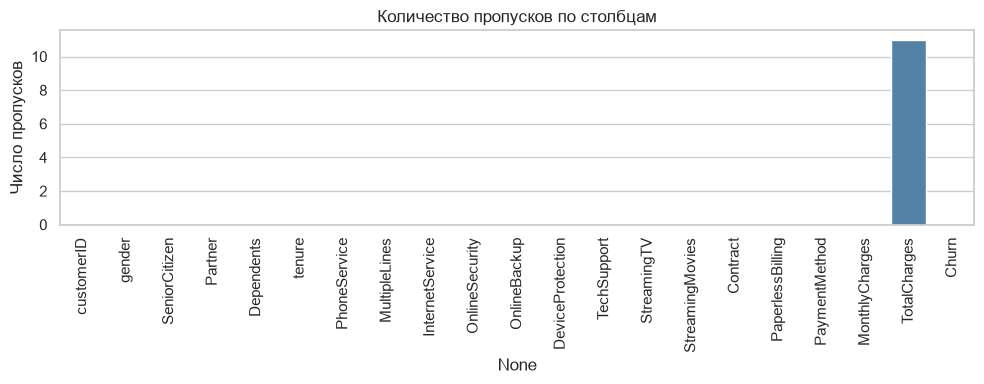

In [5]:
# Анализ пропусков. TotalCharges хранится как текст: у новых клиентов вместо числа стоит пробел
print('Пустые строки (пробелы) в TotalCharges:',  # сколько «пустых» значений-пробелов в TotalCharges
      (df['TotalCharges'].astype(str).str.strip() == '').sum())  # считаем строки, состоящие только из пробелов

# Преобразуем в число; нечитаемые значения станут NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # текст → число; пробелы превращаются в NaN

missing = df.isna().sum()                    # число пропусков по столбцам
print('\nПропуски по столбцам (только ненулевые):')  # заголовок вывода
print(missing[missing > 0])  # показываем только столбцы с пропусками

# Смотрим на строки с пропусками: что у них общего?
print('\nСтроки с пропуском в TotalCharges:')  # заголовок вывода
print(df.loc[df['TotalCharges'].isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])  # у этих клиентов tenure = 0

# Визуализация пропусков
plt.figure(figsize=(10, 4))  # создаём фигуру
sns.barplot(x=missing.index, y=missing.values, color='steelblue')  # столбчатая диаграмма пропусков
plt.xticks(rotation=90)  # поворачиваем подписи оси X
plt.title('Количество пропусков по столбцам')  # заголовок графика
plt.ylabel('Число пропусков')  # подпись оси Y
plt.tight_layout()  # подгоняем отступы
plt.show()  # показываем график

In [6]:
# Анализ целевой переменной
print(df['Churn'].value_counts())                       # абсолютные значения
print()  # пустая строка
print((df['Churn'].value_counts(normalize=True) * 100).round(2))  # доли в %

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [7]:
# Обработка пропусков TotalCharges
# Пропуски встречаются только у клиентов с tenure = 0 (ещё не было ни одного счёта),
# поэтому логичная «истинная» сумма — 0. Но по условию задания заполняем медианой
# (устойчива к выбросам); на 11 строках из 7043 (~0.2%) разница несущественна.
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())  # заполняем пропуски медианой
print('Пропусков в TotalCharges после заполнения:', df['TotalCharges'].isna().sum())  # проверяем, что пропусков не осталось

Пропусков в TotalCharges после заполнения: 0


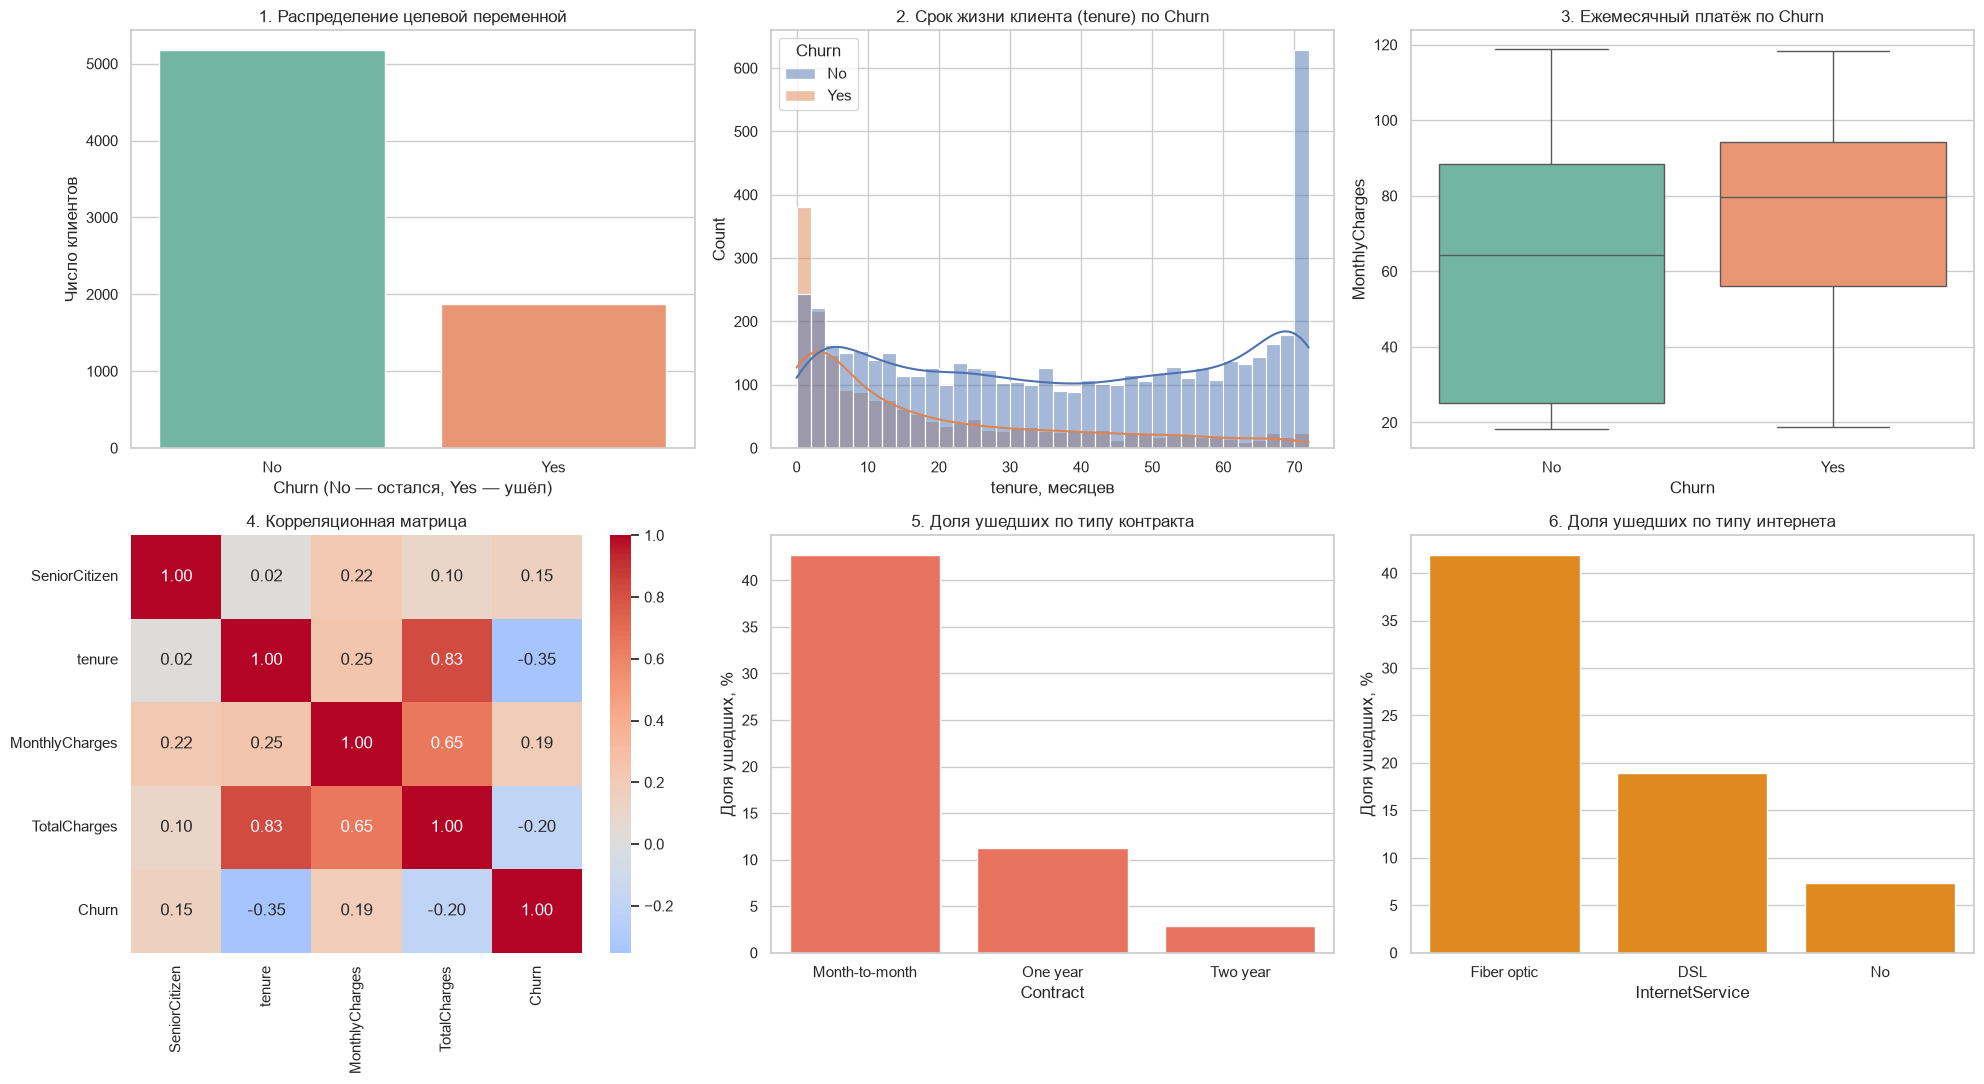

In [8]:
# EDA: сетка 2x3 — 6 графиков
churn_num = (df['Churn'] == 'Yes').astype(int)   # числовой вид целевой для расчёта долей

fig, axes = plt.subplots(2, 3, figsize=(20, 11))  # сетка 2x3 для 6 графиков

# 1. Countplot — распределение целевой переменной
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0, 0])  # график 1: число клиентов по классам
axes[0, 0].set_title('1. Распределение целевой переменной')  # оформление подграфика (заголовок/подпись оси)
axes[0, 0].set_xlabel('Churn (No — остался, Yes — ушёл)')  # оформление подграфика (заголовок/подпись оси)
axes[0, 0].set_ylabel('Число клиентов')  # оформление подграфика (заголовок/подпись оси)

# 2. Гистограмма tenure с разбивкой по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=36, ax=axes[0, 1])  # график 2: гистограмма tenure с KDE по классам
axes[0, 1].set_title('2. Срок жизни клиента (tenure) по Churn')  # оформление подграфика (заголовок/подпись оси)
axes[0, 1].set_xlabel('tenure, месяцев')  # оформление подграфика (заголовок/подпись оси)

# 3. Boxplot MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=axes[0, 2])  # график 3: ящик с усами для MonthlyCharges
axes[0, 2].set_title('3. Ежемесячный платёж по Churn')  # оформление подграфика (заголовок/подпись оси)
axes[0, 2].set_ylabel('MonthlyCharges')  # оформление подграфика (заголовок/подпись оси)

# 4. Heatmap корреляций числовых признаков
corr_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()  # числовые столбцы для корреляций
corr_df['Churn'] = churn_num  # добавляем целевую (0/1)
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])  # график 4: тепловая карта корреляций
axes[1, 0].set_title('4. Корреляционная матрица')  # оформление подграфика (заголовок/подпись оси)

# 5. Доля ушедших по типу контракта
contract_rate = churn_num.groupby(df['Contract']).mean().sort_values(ascending=False) * 100  # доля ушедших (%) по типам контракта
sns.barplot(x=contract_rate.index, y=contract_rate.values, color='tomato', ax=axes[1, 1])  # график 5: столбцы по контрактам
axes[1, 1].set_title('5. Доля ушедших по типу контракта')  # оформление подграфика (заголовок/подпись оси)
axes[1, 1].set_ylabel('Доля ушедших, %')  # оформление подграфика (заголовок/подпись оси)
axes[1, 1].set_xlabel('Contract')  # оформление подграфика (заголовок/подпись оси)

# 6. Доля ушедших по типу интернета
inet_rate = churn_num.groupby(df['InternetService']).mean().sort_values(ascending=False) * 100  # доля ушедших (%) по типам интернета
sns.barplot(x=inet_rate.index, y=inet_rate.values, color='darkorange', ax=axes[1, 2])  # график 6: столбцы по интернету
axes[1, 2].set_title('6. Доля ушедших по типу интернета')  # оформление подграфика (заголовок/подпись оси)
axes[1, 2].set_ylabel('Доля ушедших, %')  # оформление подграфика (заголовок/подпись оси)
axes[1, 2].set_xlabel('InternetService')  # оформление подграфика (заголовок/подпись оси)

plt.tight_layout()  # подгоняем отступы
plt.savefig('examples/eda_plots.png', dpi=120, bbox_inches='tight')   # сохраняем для репозитория
plt.show()  # показываем график

In [9]:
# Feature Engineering: новые признаки
df['TenureYears'] = df['tenure'] / 12                                   # срок в годах
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)         # средний платёж за месяц (+1 защита от деления на 0)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)                      # новичок: до 6 месяцев

# Счётчик подключённых услуг: считаем значения 'Yes' среди услуг
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',  # столбцы с услугами
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']  # (продолжение списка услуг)
df['HasMultipleServices'] = (df[service_cols] == 'Yes').sum(axis=1)  # сколько услуг подключено ('Yes')

print(df[['tenure', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']].head())  # проверяем новые признаки

# Копия с понятными строковыми значениями — понадобится для бизнес-анализа в разделе 8
df_eda = df.copy()  # копия с читаемыми значениями
df_eda['ChurnFlag'] = (df_eda['Churn'] == 'Yes').astype(int)  # числовой флаг оттока для расчёта долей

   tenure  TenureYears  AvgMonthlyCharge  IsNewClient  HasMultipleServices
0       1     0.083333         14.925000            1                    1
1      34     2.833333         53.985714            0                    3
2       2     0.166667         36.050000            1                    3
3      45     3.750000         40.016304            0                    3
4       2     0.166667         50.550000            1                    1


In [10]:
# Кодирование
from sklearn.preprocessing import LabelEncoder, StandardScaler  # кодировщик категорий и масштабирование

# Целевая переменная: Yes = 1, No = 0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)  # Yes → 1, No → 0

# Категориальные признаки: все нечисловые столбцы, кроме customerID
cat_cols = [c for c in df.columns  # категориальные признаки без customerID
            if c not in ('customerID', 'Churn') and not pd.api.types.is_numeric_dtype(df[c])]  # нечисловые столбцы
print('Категориальные признаки для кодирования:', len(cat_cols))  # сколько столбцов кодируем

# LabelEncoder на каждый столбец; сохраняем кодировщики, чтобы потом кодировать новые данные так же
label_encoders = {}  # словарь кодировщиков (столбец → LabelEncoder)
for col in cat_cols:  # кодируем каждый категориальный столбец
    le = LabelEncoder()  # новый кодировщик
    df[col] = le.fit_transform(df[col].astype(str))  # строки → числа
    label_encoders[col] = le  # запоминаем кодировщик

print(df.drop(columns='customerID').head())  # результат кодирования

Категориальные признаки для кодирования: 15
   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   MultipleLines  InternetService  OnlineSecurity  OnlineBackup  ...  \
0              1                0               0             2  ...   
1              0                0               2             0  ...   
2              0                0               2             2  ...   
3              1                0               2             0  ...   
4              0                1               0             0  ...   

   Contract  PaperlessBilling  PaymentMethod  MonthlyCharges  TotalCharges  \
0         0       

In [11]:
# Разделение на train/test со стратификацией (сохраняем долю классов)
from sklearn.model_selection import train_test_split  # разбиение на train/test

feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]  # список признаков модели
X = df[feature_cols]  # матрица признаков
y = df['Churn']  # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(  # 80% train / 20% test
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)  # stratify=y сохраняет долю классов

print('train:', X_train.shape, ' test:', X_test.shape)  # размеры выборок
print('Доля ушедших — train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))  # доля класса 1 в обеих выборках одинакова

# Scaler для числовых признаков. Деревьям масштабирование не нужно, поэтому модели обучаем на
# немасштабированных данных; scaler обучаем на train и сохраняем для совместимости/дальнейших модулей.
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge']  # числовые признаки для масштабирования
scaler = StandardScaler().fit(X_train[scale_cols])  # обучаем scaler только на train

train: (5634, 23)  test: (1409, 23)
Доля ушедших — train: 0.265, test: 0.265


**Выводы по EDA:**
- Единственные пропуски — в `TotalCharges` (в исходном файле это пробелы, из-за чего столбец читался как текст). Они относятся к клиентам с `tenure = 0`, то есть к ещё не выставленным счетам. Заполнение медианой допустимо (доля таких строк ~0.2%), хотя по смыслу точнее было бы 0.
- Классы несбалансированы (~26.5% ушедших), поэтому используем `stratify=y` при разбиении и взвешивание классов в моделях.
- По графикам: ушедшие клиенты в среднем имеют меньший `tenure` и более высокий `MonthlyCharges`; доля оттока существенно выше при контракте «Month-to-month» и при интернете «Fiber optic» (точные значения — на графиках 5 и 6 и в разделе 8).
- Деревьям не требуется масштабирование и one-hot-кодирование, поэтому для категориальных признаков достаточно `LabelEncoder` (порядок кодов не несёт смысла, но деревья справляются через разбиения по порогам).
- Нюанс: медиана `TotalCharges` посчитана по всему датасету до разбиения; из-за 11 строк утечка пренебрежимо мала.

## Построение и обучение моделей

Обучаем 4 ансамблевые модели на одних и тех же данных и фиксируем время обучения. Для борьбы с дисбалансом используем взвешивание классов (`class_weight='balanced'`, `scale_pos_weight`, `auto_class_weights='Balanced'`). Для XGBoost `scale_pos_weight = 3` — округлённое отношение числа остающихся к ушедшим (≈ 2.8).

In [12]:
# Импорт моделей
from sklearn.ensemble import RandomForestClassifier  # Random Forest (bagging)
from xgboost import XGBClassifier  # XGBoost (boosting)
from lightgbm import LGBMClassifier  # LightGBM (boosting)
from catboost import CatBoostClassifier  # CatBoost (boosting)

train_times = {}   # сюда складываем время обучения каждой модели

def fit_timed(model, name):  # обучение с замером времени
    # Обучаем модель и замеряем время
    start = time.time()  # старт таймера
    model.fit(X_train, y_train)  # обучаем модель
    train_times[name] = time.time() - start  # сохраняем время обучения
    print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')  # выводим время
    return model  # возвращаем обученную модель

# 1. Random Forest (bagging)
rf_model = fit_timed(RandomForestClassifier(  # Random Forest: 200 деревьев
    n_estimators=200, max_depth=10, class_weight='balanced',  # число деревьев, глубина, баланс классов
    random_state=RANDOM_STATE, n_jobs=-1), 'Random Forest')  # воспроизводимость, все ядра

# 2. XGBoost (boosting)
xgb_model = fit_timed(XGBClassifier(  # XGBoost
    n_estimators=200, max_depth=6, learning_rate=0.1,  # число деревьев, глубина, скорость обучения
    subsample=0.9, colsample_bytree=0.9,  # доли объектов и признаков на дерево
    scale_pos_weight=3,                      # компенсация дисбаланса
    random_state=RANDOM_STATE, eval_metric='logloss'), 'XGBoost')  # воспроизводимость, метрика логирования

# 3. LightGBM (boosting)
lgbm_model = fit_timed(LGBMClassifier(  # LightGBM
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,  # листьев на дерево — главный параметр LightGBM
    class_weight='balanced', random_state=RANDOM_STATE, verbose=-1), 'LightGBM')  # баланс классов, без логов

# 4. CatBoost (boosting). Признаки уже закодированы LabelEncoder, поэтому cat_features не задаём
cat_model = fit_timed(CatBoostClassifier(  # CatBoost
    iterations=200, depth=6, learning_rate=0.1,  # итерации и глубина
    auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, allow_writing_files=False), 'CatBoost')  # баланс классов, без логов и без папки catboost_info

⏱️ Время обучения Random Forest: 0.622 сек
⏱️ Время обучения XGBoost: 0.751 сек
⏱️ Время обучения LightGBM: 0.343 сек
⏱️ Время обучения CatBoost: 1.318 сек


In [13]:
# Таблица моделей с фактическим временем обучения (вывод как Markdown-таблица)
models_info = pd.DataFrame([  # строки таблицы моделей
    ['Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced', train_times['Random Forest']],  # Random Forest
    ['XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3', train_times['XGBoost']],  # XGBoost
    ['LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05', train_times['LightGBM']],  # LightGBM
    ['CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced', train_times['CatBoost']],  # CatBoost
], columns=['Модель', 'Тип', 'Параметры', 'Время обучения, сек'])  # названия столбцов
display(Markdown(md_table(models_info, 3)))   # таблица с реальными значениями времени

| Модель | Тип | Параметры | Время обучения, сек |
|---|---|---|---|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight=balanced | 0.622 |
| XGBoost | Boosting | n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3 | 0.751 |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, max_depth=7, lr=0.05 | 0.343 |
| CatBoost | Boosting | iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced | 1.318 |

### Модели

Таблица с параметрами и временем обучения выведена ячейкой выше.

**Почему эти модели:**
- RF — устойчив к переобучению, хорошо работает «из коробки», служит надёжным baseline;
- XGBoost — универсальный и точный, есть регуляризация;
- LightGBM — быстрый, подходит для больших данных;
- CatBoost — хорош на категориальных признаках и обычно стабилен без тонкой настройки.

## Оценка качества

Считаем Accuracy, Precision, Recall, F1 и ROC-AUC на отложенной тестовой выборке. Порог классификации — стандартный 0.5; ROC-AUC от порога не зависит.

In [14]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # метрики классификации
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)  # ROC-AUC, ROC-кривая, матрица ошибок, отчёт

def evaluate_model(model, X_test, y_test, name):  # считаем все метрики одной модели
    # Считаем набор метрик для одной модели
    y_pred = model.predict(X_test)  # предсказанные классы (порог 0.5)
    y_proba = model.predict_proba(X_test)[:, 1]  # вероятность класса «ушёл»
    return {  # словарь с метриками
        'Model': name,  # название модели
        'Accuracy':  accuracy_score(y_test, y_pred),  # доля верных ответов
        'Precision': precision_score(y_test, y_pred),  # точность по классу «ушёл»
        'Recall':    recall_score(y_test, y_pred),  # полнота по классу «ушёл»
        'F1':        f1_score(y_test, y_pred),  # гармоническое среднее Precision и Recall
        'ROC-AUC':   roc_auc_score(y_test, y_proba),  # качество ранжирования по вероятностям
    }

models = {'Random Forest': rf_model, 'XGBoost': xgb_model,  # все модели в одном словаре
          'LightGBM': lgbm_model, 'CatBoost': cat_model}  # (продолжение словаря моделей)

results = [evaluate_model(m, X_test, y_test, name) for name, m in models.items()]  # метрики для каждой модели
results_df = pd.DataFrame(results)  # таблица результатов
results_df['Время, сек'] = results_df['Model'].map(train_times)  # добавляем время обучения
print(results_df.round(4).to_string(index=False))  # таблица метрик текстом
display(Markdown(md_table(results_df)))   # то же в виде Markdown-таблицы

        Model  Accuracy  Precision  Recall     F1  ROC-AUC  Время, сек
Random Forest    0.7622     0.5373  0.7513 0.6265   0.8383      0.6221
      XGBoost    0.7693     0.5514  0.7032 0.6181   0.8292      0.7509
     LightGBM    0.7601     0.5344  0.7487 0.6236   0.8379      0.3427
     CatBoost    0.7559     0.5279  0.7594 0.6228   0.8381      1.3181


| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Время, сек |
|---|---|---|---|---|---|---|
| Random Forest | 0.7622 | 0.5373 | 0.7513 | 0.6265 | 0.8383 | 0.6221 |
| XGBoost | 0.7693 | 0.5514 | 0.7032 | 0.6181 | 0.8292 | 0.7509 |
| LightGBM | 0.7601 | 0.5344 | 0.7487 | 0.6236 | 0.8379 | 0.3427 |
| CatBoost | 0.7559 | 0.5279 | 0.7594 | 0.6228 | 0.8381 | 1.3181 |

Лучшая модель по ROC-AUC: Random Forest


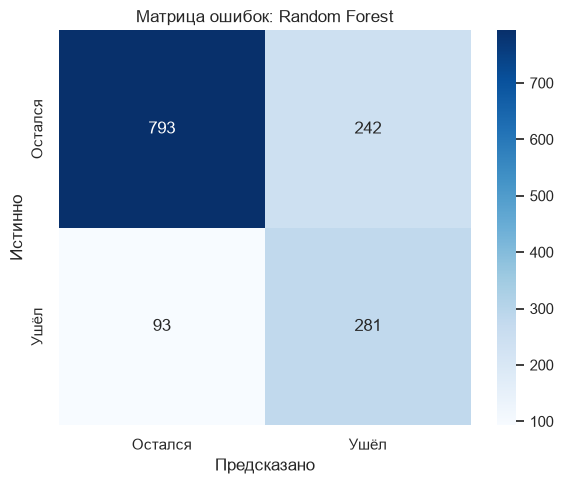

              precision    recall  f1-score   support

     Остался       0.90      0.77      0.83      1035
        Ушёл       0.54      0.75      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



In [15]:
# Лучшая модель по ROC-AUC и её матрица ошибок
best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']  # лучшая модель по ROC-AUC
best_baseline = models[best_name]  # объект лучшей модели
y_pred_best = best_baseline.predict(X_test)  # её предсказания
print('Лучшая модель по ROC-AUC:', best_name)  # название лучшей модели

cm = confusion_matrix(y_test, y_pred_best)  # матрица ошибок
plt.figure(figsize=(6, 5))  # создаём фигуру
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # рисуем матрицу ошибок
            xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])  # подписи классов
plt.xlabel('Предсказано')  # подпись оси X
plt.ylabel('Истинно')  # подпись оси Y
plt.title(f'Матрица ошибок: {best_name}')  # заголовок графика
plt.tight_layout()  # подгоняем отступы
plt.show()  # показываем график

print(classification_report(y_test, y_pred_best, target_names=['Остался', 'Ушёл']))  # подробный отчёт по классам

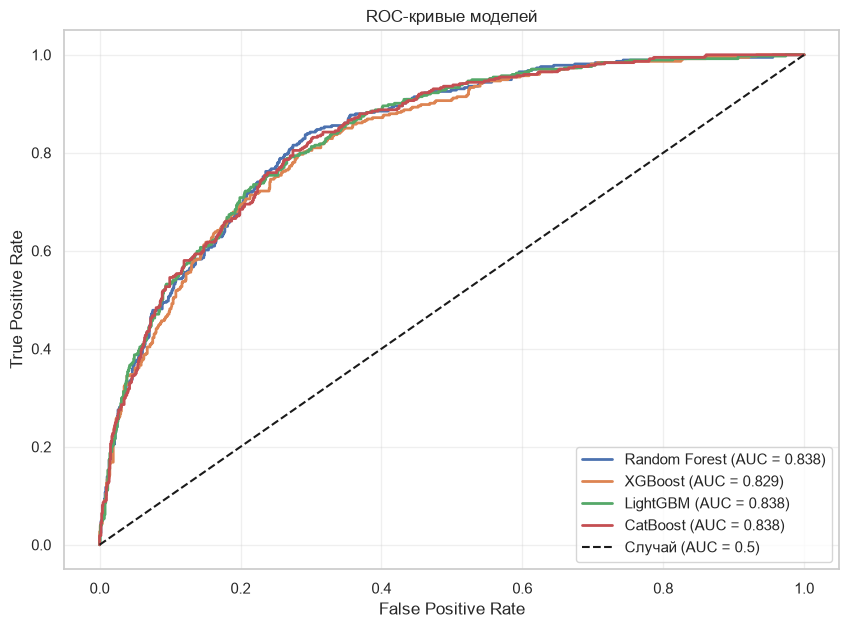

In [16]:
# ROC-кривые всех 4 моделей на одном графике
plt.figure(figsize=(10, 7))  # создаём фигуру
for name, model in models.items():  # кривая для каждой модели
    y_proba = model.predict_proba(X_test)[:, 1]  # вероятность класса «ушёл»
    fpr, tpr, _ = roc_curve(y_test, y_proba)  # точки ROC-кривой
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})')  # рисуем кривую с значением AUC в легенде

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')  # диагональ — случайное угадывание
plt.xlabel('False Positive Rate')  # подпись оси X
plt.ylabel('True Positive Rate')  # подпись оси Y
plt.title('ROC-кривые моделей')  # заголовок графика
plt.legend()  # легенда
plt.grid(alpha=0.3)  # сетка
plt.savefig('examples/roc_curves.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

In [17]:
# Автоматический анализ результатов (числа подставляются из таблицы)
fastest = results_df.loc[results_df['Время, сек'].idxmin(), 'Model']  # самая быстрая модель
best_recall = results_df.loc[results_df['Recall'].idxmax(), 'Model']  # модель с лучшим Recall
spread = results_df['ROC-AUC'].max() - results_df['ROC-AUC'].min()  # разброс ROC-AUC между моделями

print(f"• Лучшая модель по ROC-AUC: {best_name} ({results_df['ROC-AUC'].max():.4f})")  # вывод результата
print(f"• Разброс ROC-AUC между моделями: {spread:.4f}")  # вывод результата
print(f"• Быстрее всех обучается: {fastest} ({results_df['Время, сек'].min():.3f} сек)")  # вывод результата
print(f"• Наибольший Recall: {best_recall} ({results_df['Recall'].max():.4f})")  # вывод результата
for _, r in results_df.iterrows():  # характер ошибок каждой модели
    tendency = 'Precision > Recall (модель осторожна в предсказании «уйдёт»)' if r['Precision'] > r['Recall'] \
        else 'Recall > Precision (модель находит больше уходящих ценой ложных тревог)'  # (иначе — Recall выше)
    print(f"• {r['Model']}: {tendency}")  # вывод результата

• Лучшая модель по ROC-AUC: Random Forest (0.8383)
• Разброс ROC-AUC между моделями: 0.0091
• Быстрее всех обучается: LightGBM (0.343 сек)
• Наибольший Recall: CatBoost (0.7594)
• Random Forest: Recall > Precision (модель находит больше уходящих ценой ложных тревог)
• XGBoost: Recall > Precision (модель находит больше уходящих ценой ложных тревог)
• LightGBM: Recall > Precision (модель находит больше уходящих ценой ложных тревог)
• CatBoost: Recall > Precision (модель находит больше уходящих ценой ложных тревог)


### Анализ результатов

Таблица метрик и времени обучения выведена выше. Как её читать:

- **ROC-AUC** — основная метрика сравнения. Различия между бустингами обычно небольшие (порядка сотых), поэтому при выборе модели важны ещё скорость и устойчивость.
- Из-за взвешивания классов модели имеют **Recall выше Precision**: они чаще «подозревают» уход, находя бо́льшую часть реально уходящих клиентов ценой ложных срабатываний. Для кампаний удержания это допустимый компромисс; порог можно сдвигать под стоимость ошибок.
- **Accuracy** при таком дисбалансе ниже, чем у «наивной» модели, всегда предсказывающей «остался» (≈73.5%), но та имеет Recall = 0, поэтому Accuracy здесь не критерий.
- По времени обучения LightGBM, как правило, самый быстрый, а CatBoost самый медленный; точные значения — в таблице.
- Для дальнейшей оптимизации и интерпретации берём **LightGBM**, как того требует задание (быстрая модель с качеством на уровне лучших; конкретное сравнение с лидером см. в выводе выше).

## Интерпретация и бизнес-инсайты

Смотрим, какие признаки модели считают важными, и проверяем гипотезы напрямую по данным.

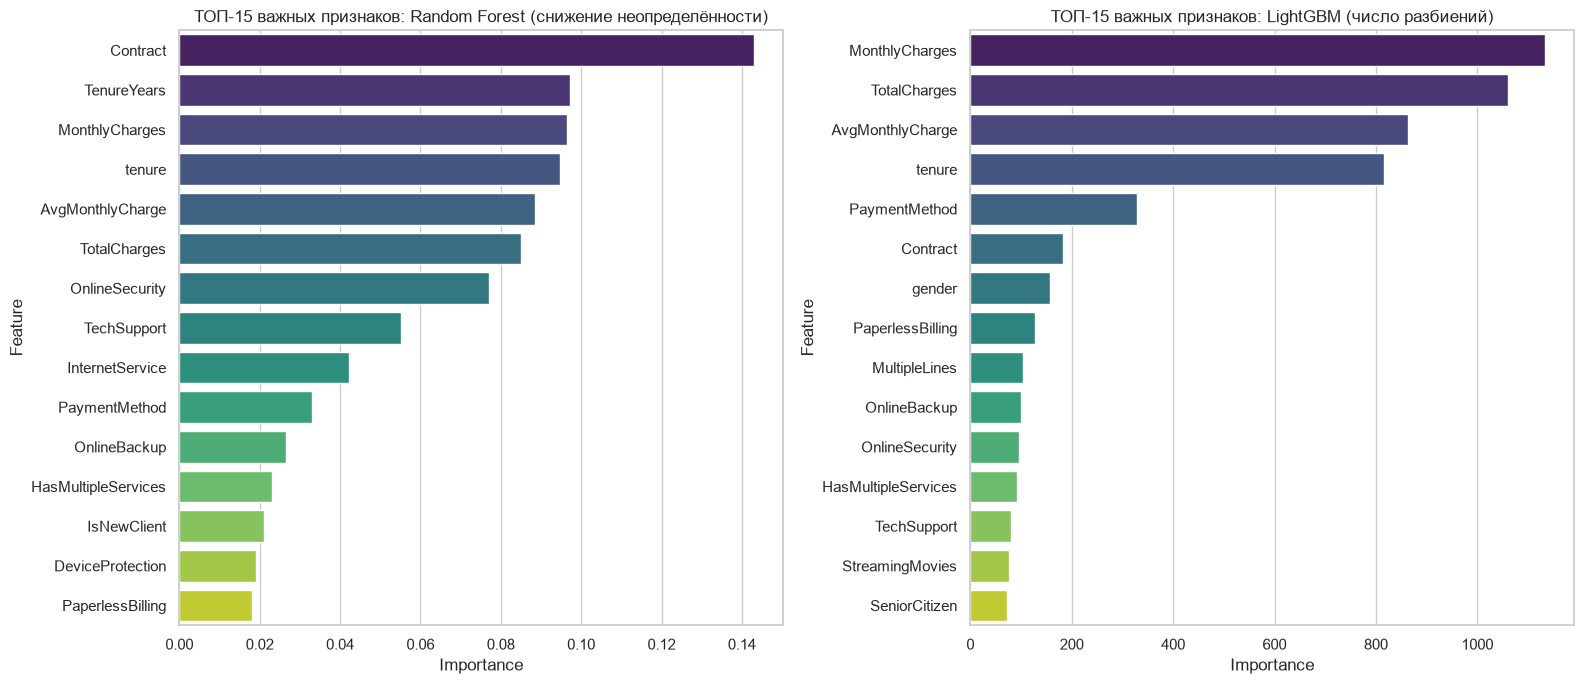

**Топ-5 признаков, влияющих на отток:**

| # | Random Forest | LightGBM |
|---|---|---|
| 1 | Contract | MonthlyCharges |
| 2 | TenureYears | TotalCharges |
| 3 | MonthlyCharges | AvgMonthlyCharge |
| 4 | tenure | tenure |
| 5 | AvgMonthlyCharge | PaymentMethod |

In [18]:
# Feature Importance для Random Forest и LightGBM
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)  # сортируем по убыванию
imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)  # сортируем по убыванию
importances = imp_lgbm   # используем в разделе SHAP как ориентир

fig, axes = plt.subplots(1, 2, figsize=(16, 7))  # два графика рядом
for ax, data, title in [(axes[0], imp_rf, 'Random Forest (снижение неопределённости)'),  # RF слева, LightGBM справа
                        (axes[1], imp_lgbm, 'LightGBM (число разбиений)')]:  # (второй график)
    sns.barplot(data=data.head(15), x='Importance', y='Feature', hue='Feature',  # ТОП-15 признаков
                palette='viridis', legend=False, ax=ax)  # цветовая палитра
    ax.set_title(f'ТОП-15 важных признаков: {title}')  # заголовок подграфика
plt.tight_layout()  # подгоняем отступы
plt.savefig('examples/feature_importance.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# Топ-5 признаков по обеим моделям (Markdown-таблица)
top5 = pd.DataFrame({'#': range(1, 6),
                     'Random Forest': imp_rf['Feature'].head(5).tolist(),  # топ-5 по Random Forest
                     'LightGBM': imp_lgbm['Feature'].head(5).tolist()})  # топ-5 по LightGBM
display(Markdown('**Топ-5 признаков, влияющих на отток:**\n\n' + md_table(top5)))  # таблица топ-5 в формате Markdown

In [19]:
# Проверка бизнес-гипотез на исходных (некодированных) данных: доля ушедших, %
def churn_rate(by):  # доля ушедших по группам
    return (df_eda.groupby(by)['ChurnFlag'].mean() * 100).round(1).sort_values(ascending=False)  # среднее по флагу оттока × 100

for col in ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'IsNewClient']:  # ключевые категориальные признаки
    print(f'--- Доля ушедших по {col}, % ---')  # заголовок таблицы
    print(churn_rate(col).to_string())  # сама таблица
    print()  # пустая строка

# Риск по срокам: churn по интервалам tenure
bins = pd.cut(df_eda['tenure'], bins=[-1, 6, 12, 24, 48, 72], labels=['0-6', '7-12', '13-24', '25-48', '49-72'])  # интервалы срока обслуживания
print('--- Доля ушедших по tenure (месяцы), % ---')  # заголовок таблицы
print((df_eda.groupby(bins, observed=True)['ChurnFlag'].mean() * 100).round(1).to_string())  # отток по интервалам tenure

--- Доля ушедших по Contract, % ---
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

--- Доля ушедших по InternetService, % ---
InternetService
Fiber optic    41.9
DSL            19.0
No              7.4

--- Доля ушедших по OnlineSecurity, % ---
OnlineSecurity
No                     41.8
Yes                    14.6
No internet service     7.4

--- Доля ушедших по TechSupport, % ---
TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4

--- Доля ушедших по PaymentMethod, % ---
PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2

--- Доля ушедших по IsNewClient, % ---
IsNewClient
1    52.9
0    19.5

--- Доля ушедших по tenure (месяцы), % ---
tenure
0-6      52.9
7-12     35.9
13-24    28.7
25-48    20.4
49-72     9.5


### Интерпретация

**Топ признаков, влияющих на отток** — см. графики и списки выше. Как правило, в верхней части оказываются тип контракта (`Contract`), срок обслуживания (`tenure`, `TenureYears`), суммы платежей (`TotalCharges`, `MonthlyCharges`, `AvgMonthlyCharge`) и тип интернета (`InternetService`). Порядок для RF и LightGBM отличается: у LightGBM важность считается по числу разбиений, поэтому непрерывные признаки с множеством порогов (платежи) выглядят важнее.

**Бизнес-инсайты** (подтверждаются таблицами долей оттока выше):
- Клиенты с контрактом **«Month-to-month»** уходят в разы чаще, чем с годовым или двухлетним; перевод абонентов на длительные контракты (скидка, бонус) — главный рычаг удержания.
- **Первые месяцы** жизни клиента — самый рискованный период; нужна программа «онбординга» и проактивные контакты с новичками.
- Абоненты с **Fiber optic** уходят заметно чаще, чем с DSL: стоит проверить качество услуги и цену относительно конкурентов.
- Отсутствие **OnlineSecurity** и **TechSupport** связано с более высоким оттоком; дополнительные сервисы можно использовать как инструмент удержания (пробный период, бандлы).
- Клиенты, платящие **Electronic check**, уходят чаще; это сигнал для стимулирования перехода на автоплатежи.

*Важно:* это ассоциации, а не причинно-следственные связи: например, высокий отток у Fiber optic может объясняться ценой или конкурентным рынком, а не самой технологией.

## Тюнинг гиперпараметров (Optuna)

Оптимизируем LightGBM байесовским поиском (TPE). Целевая функция — средний ROC-AUC на 5-fold стратифицированной кросс-валидации **по обучающей выборке**, чтобы тестовая выборка не участвовала в подборе. В `LGBMClassifier` параметр `subsample` действует только вместе с `subsample_freq > 0`, поэтому фиксируем `subsample_freq=1`.

In [20]:
# Установка (если нужно): !pip install optuna shap
import optuna  # байесовская оптимизация гиперпараметров
from sklearn.model_selection import StratifiedKFold, cross_val_score  # стратифицированная кросс-валидация

optuna.logging.set_verbosity(optuna.logging.WARNING)   # меньше шума в выводе

def objective(trial):  # целевая функция для Optuna
    # Пространство поиска гиперпараметров
    params = {  # пространство поиска гиперпараметров
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # число листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),  # максимальная глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # скорость обучения (лог-шкала)
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # доля объектов на дерево
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # доля признаков на дерево
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # минимум объектов в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1-регуляризация
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2-регуляризация
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',  # модель с предложенными параметрами
                           random_state=RANDOM_STATE, verbose=-1)  # воспроизводимость, без логов
    cv_scores = cross_val_score(  # 5-fold CV по train
        model, X_train, y_train,  # данные для кросс-валидации
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),  # 5 стратифицированных фолдов
        scoring='roc_auc')  # метрика — ROC-AUC
    return cv_scores.mean()   # максимизируем средний ROC-AUC по фолдам

# CV-оценка baseline LightGBM для честного сравнения
baseline_cv = cross_val_score(  # CV baseline LightGBM
    LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,  # baseline-параметры
                   class_weight='balanced', random_state=RANDOM_STATE, verbose=-1),  # баланс классов, без логов
    X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),  # те же фолды, что и в Optuna
    scoring='roc_auc').mean()  # метрика — ROC-AUC
print(f'Baseline LightGBM, CV ROC-AUC: {baseline_cv:.4f}')  # качество baseline

# Запуск оптимизации (TPE с фиксированным seed)
N_TRIALS = 30  # число испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))  # создаём исследование (максимизируем AUC)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)  # запускаем поиск

print(f'\nBest CV ROC-AUC: {study.best_value:.4f}')  # лучший результат CV
for key, value in study.best_params.items():  # лучшие параметры
    print(f'  {key}: {value}')  # параметр: значение

Baseline LightGBM, CV ROC-AUC: 0.8399


Best trial: 13. Best value: 0.849509: 100%|██████████| 30/30 [00:59<00:00,  1.97s/it]


Best CV ROC-AUC: 0.8495
  n_estimators: 350
  num_leaves: 90
  max_depth: 3
  learning_rate: 0.022943298923083385
  subsample: 0.6236369825139823
  colsample_bytree: 0.5164731483152039
  min_child_samples: 35
  reg_alpha: 0.002886956542416407
  reg_lambda: 7.328751913955659


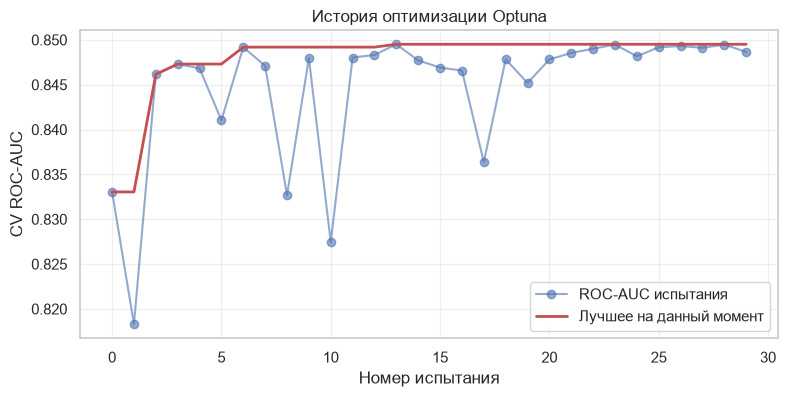

In [21]:
# История оптимизации
trials_df = study.trials_dataframe()  # результаты испытаний в таблице
plt.figure(figsize=(9, 4))  # создаём фигуру
plt.plot(trials_df['number'], trials_df['value'], 'o-', alpha=0.6, label='ROC-AUC испытания')  # качество каждого испытания
plt.plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')  # лучшее на данный момент
plt.xlabel('Номер испытания')  # подпись оси X
plt.ylabel('CV ROC-AUC')  # подпись оси Y
plt.title('История оптимизации Optuna')  # заголовок графика
plt.legend()  # легенда
plt.grid(alpha=0.3)  # сетка
plt.show()  # показываем график

In [22]:
# Обучаем лучшую модель на всём train и сравниваем с baseline на test
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # модель с лучшими параметрами
                           random_state=RANDOM_STATE, verbose=-1)  # воспроизводимость, без логов
best_lgbm.fit(X_train, y_train)  # обучаем на всём train

y_pred_tuned = best_lgbm.predict(X_test)  # классы на test
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]  # вероятности на test

auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])  # ROC-AUC baseline на test
auc_tuned = roc_auc_score(y_test, y_proba_best)  # ROC-AUC после Optuna на test
print(f'CV ROC-AUC  baseline: {baseline_cv:.4f} → Optuna: {study.best_value:.4f}')  # сравнение по CV
print(f'Test ROC-AUC baseline: {auc_base:.4f} → Optuna: {auc_tuned:.4f}  (прирост {auc_tuned - auc_base:+.4f})')  # сравнение на test

# Итоговая таблица: все модели + тюнингованный LightGBM
tuned_row = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')  # метрики тюнингованной модели
final_df = pd.concat([results_df.drop(columns='Время, сек'), pd.DataFrame([tuned_row])], ignore_index=True)  # общая таблица всех моделей
print()  # пустая строка
print(final_df.round(4).to_string(index=False))  # итоговая таблица

# Итог Optuna в формате методички (числа подставляются автоматически)
params_md = '\n'.join(f'- {k}: {v:.4g}' if isinstance(v, float) else f'- {k}: {v}'  # лучшие параметры списком Markdown
                      for k, v in study.best_params.items())  # (по всем параметрам)
display(Markdown(  # вывод итога в формате методички
    f'**Optuna результаты:**\n\n- Проведено {N_TRIALS} испытаний\n'  # число испытаний
    f'- Baseline ROC-AUC (test): {auc_base:.4f}\n- Optuna ROC-AUC (test): {auc_tuned:.4f}\n'  # метрики до и после
    f'- Прирост: {(auc_tuned - auc_base) * 100:+.2f} п.п.\n\n**Лучшие параметры:**\n\n{params_md}'))  # прирост в процентных пунктах

CV ROC-AUC  baseline: 0.8399 → Optuna: 0.8495
Test ROC-AUC baseline: 0.8379 → Optuna: 0.8504  (прирост +0.0125)

            Model  Accuracy  Precision  Recall     F1  ROC-AUC
    Random Forest    0.7622     0.5373  0.7513 0.6265   0.8383
          XGBoost    0.7693     0.5514  0.7032 0.6181   0.8292
         LightGBM    0.7601     0.5344  0.7487 0.6236   0.8379
         CatBoost    0.7559     0.5279  0.7594 0.6228   0.8381
LightGBM (Optuna)    0.7459     0.5137  0.8021 0.6263   0.8504


**Optuna результаты:**

- Проведено 30 испытаний
- Baseline ROC-AUC (test): 0.8379
- Optuna ROC-AUC (test): 0.8504
- Прирост: +1.25 п.п.

**Лучшие параметры:**

- n_estimators: 350
- num_leaves: 90
- max_depth: 3
- learning_rate: 0.02294
- subsample: 0.6236
- colsample_bytree: 0.5165
- min_child_samples: 35
- reg_alpha: 0.002887
- reg_lambda: 7.329

### Бонус: Stacking и калибровка вероятностей

Пробуем объединить 4 модели через `StackingClassifier` (мета-модель — логистическая регрессия) и откалибровать вероятности лучшей модели.

In [23]:
from sklearn.ensemble import StackingClassifier  # стекинг моделей
from sklearn.linear_model import LogisticRegression  # логистическая регрессия как мета-модель
from sklearn.calibration import CalibratedClassifierCV  # калибровка вероятностей
from sklearn.metrics import brier_score_loss  # метрика качества вероятностей

# Stacking: базовые модели с теми же параметрами + логистическая регрессия поверх их out-of-fold предсказаний
stack = StackingClassifier(  # стекинг: 4 модели + логистическая регрессия
    estimators=[  # базовые модели
        ('rf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced',  # Random Forest
                                      random_state=RANDOM_STATE, n_jobs=-1)),  # воспроизводимость, все ядра
        ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9,  # XGBoost
                              colsample_bytree=0.9, scale_pos_weight=3,  # (параметры XGB)
                              random_state=RANDOM_STATE, eval_metric='logloss')),  # воспроизводимость, метрика логирования
        ('lgbm', LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # LightGBM с лучшими параметрами
                                random_state=RANDOM_STATE, verbose=-1)),  # воспроизводимость, без логов
        ('cat', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # CatBoost
                                   auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)),  # баланс классов, без логов и без папки catboost_info
    ],  # конец списка базовых моделей
    final_estimator=LogisticRegression(max_iter=1000),  # мета-модель
    cv=5, stack_method='predict_proba', n_jobs=1)  # out-of-fold предсказания, 5 фолдов
stack.fit(X_train, y_train)  # обучаем стекинг
stack_row = evaluate_model(stack, X_test, y_test, 'Stacking (4 модели)')  # метрики стекинга

# Калибровка вероятностей лучшей модели (isotonic, 5-fold)
calibrated = CalibratedClassifierCV(  # калибровка вероятностей
    LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
                   random_state=RANDOM_STATE, verbose=-1), method='isotonic', cv=5)  # воспроизводимость, без логов
calibrated.fit(X_train, y_train)  # обучаем калибратор
cal_row = evaluate_model(calibrated, X_test, y_test, 'LightGBM (Optuna) + калибровка')  # метрики калиброванной модели

bonus_df = pd.DataFrame([tuned_row, stack_row, cal_row])  # сводка бонусов
print(bonus_df.round(4).to_string(index=False))  # таблица бонусов

# Brier score: чем меньше, тем лучше откалиброваны вероятности
# (модель с class_weight='balanced' систематически завышает вероятность класса «ушёл»)
print('\nBrier score LightGBM (Optuna):          %.4f' % brier_score_loss(y_test, y_proba_best))  # Brier до калибровки
print('Brier score LightGBM (Optuna) + калибровка: %.4f' % brier_score_loss(y_test, calibrated.predict_proba(X_test)[:, 1]))  # Brier после калибровки

                         Model  Accuracy  Precision  Recall     F1  ROC-AUC
             LightGBM (Optuna)    0.7459     0.5137  0.8021 0.6263   0.8504
           Stacking (4 модели)    0.8070     0.6527  0.5829 0.6158   0.8486
LightGBM (Optuna) + калибровка    0.8048     0.6542  0.5615 0.6043   0.8504

Brier score LightGBM (Optuna):          0.1613
Brier score LightGBM (Optuna) + калибровка: 0.1338


### Тюнинг гиперпараметров — результаты

Оптимизация проведена на 30 испытаниях TPE; точные значения лучших параметров, CV- и test-метрик выведены в ячейках выше. Как интерпретировать:

- **Главное сравнение** — CV ROC-AUC (подбор шёл по нему) и test ROC-AUC (независимая проверка). Прирост на тесте может быть меньше, чем на CV, и даже близким к нулю: на небольшом табличном датасете потолок качества задаётся данными, а не гиперпараметрами. Это нормальный результат, который стоит описать честно.
- Параметры регуляризации (`reg_alpha`, `reg_lambda`, `min_child_samples`) и `learning_rate` обычно сильнее всего влияют на обобщающую способность.
- **Бонус.** Stacking даёт прирост лишь тогда, когда базовые модели достаточно разнообразны; здесь все четыре — деревья на одних признаках, так что выигрыш ожидаемо небольшой. Калибровка почти не меняет ROC-AUC (ранжирование сохраняется), но улучшает качество самих вероятностей (Brier score), что важно, если вероятности используются в расчётах (например, ожидаемые потери от оттока).

## Интерпретация через SHAP

Объясняем итоговую модель `best_lgbm` на тестовой выборке. SHAP-значения LightGBM измеряются в лог-шансах класса «ушёл»: положительное значение повышает риск ухода.

In [24]:
import shap  # SHAP: объяснение предсказаний модели

explainer = shap.TreeExplainer(best_lgbm)  # быстрый точный explainer для деревьев
shap_values = explainer.shap_values(X_test)  # SHAP-значения на тестовой выборке

# Разные версии shap возвращают разные форматы: список по классам, 2D- или 3D-массив.
# Приводим всё к виду «значения для класса 1 (уход)» и скалярной базовой величине.
expected = np.atleast_1d(explainer.expected_value)  # базовое значение (среднее предсказание)
if isinstance(shap_values, list):  # формат 1: список по классам
    shap_values_class1 = np.asarray(shap_values[1])  # берём класс «ушёл»
    base_value = float(expected[1] if len(expected) > 1 else expected[0])  # базовое значение для класса 1
else:  # иначе — массив
    shap_values = np.asarray(shap_values)  # приводим к numpy
    if shap_values.ndim == 3:                      # (объекты, признаки, классы)
        shap_values_class1 = shap_values[:, :, 1]  # 3D → класс 1
        base_value = float(expected[1] if len(expected) > 1 else expected[0])  # базовое значение для класса 1
    else:                                          # (объекты, признаки)
        shap_values_class1 = shap_values  # 2D — уже для класса 1
        base_value = float(expected[-1])  # базовое значение

print('Форма SHAP-значений:', shap_values_class1.shape, ' базовое значение (log-odds): %.3f' % base_value)  # проверка размерности

Форма SHAP-значений: (1409, 23)  базовое значение (log-odds): -0.633


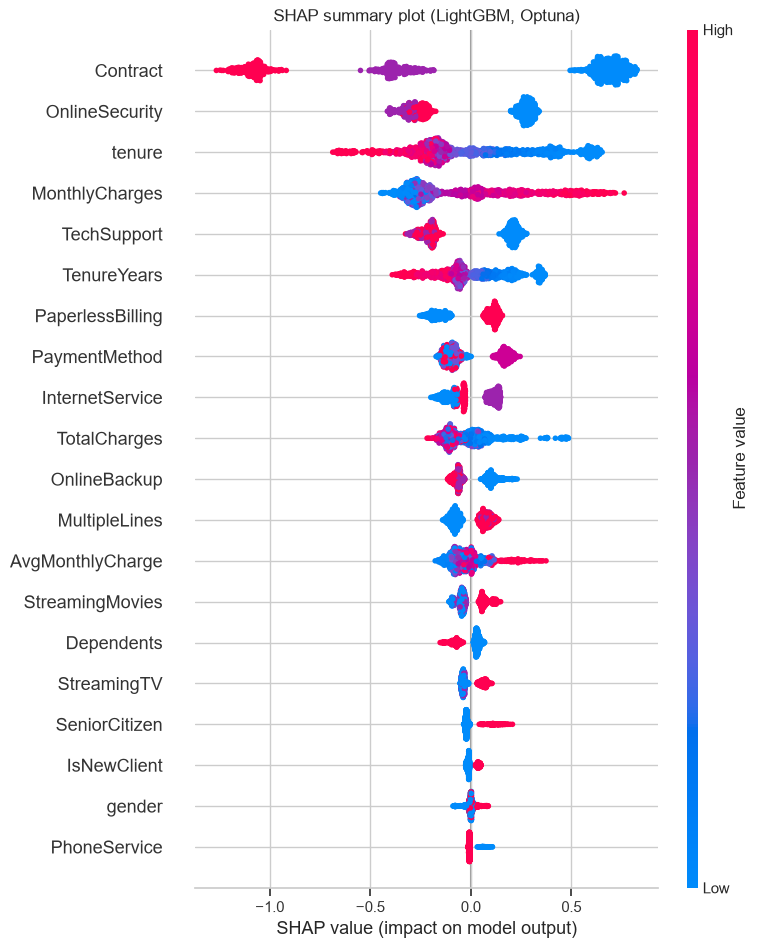

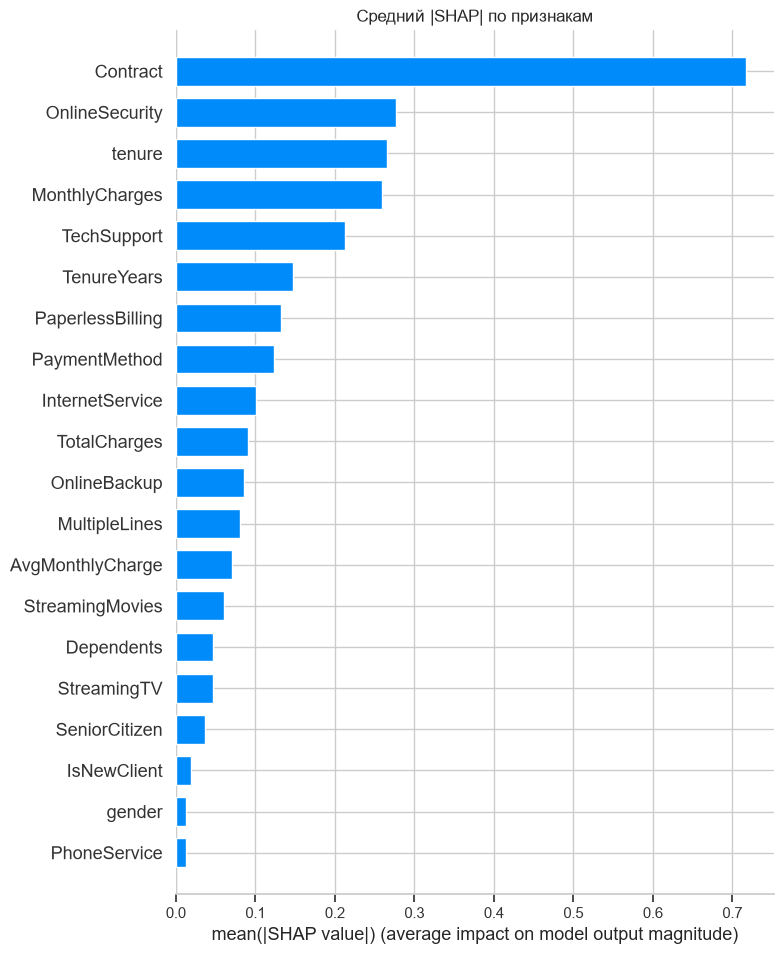

In [25]:
# Summary plot (dot): глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)  # график: важность и направление влияния
plt.title('SHAP summary plot (LightGBM, Optuna)')  # заголовок графика
plt.savefig('examples/shap_summary.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# Bar plot: средний модуль SHAP-значений
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)  # график: средний |SHAP|
plt.title('Средний |SHAP| по признакам')  # заголовок графика
plt.show()  # показываем график

Клиент #1090 (в тестовой выборке), вероятность ухода = 0.9498, истинная метка = 1


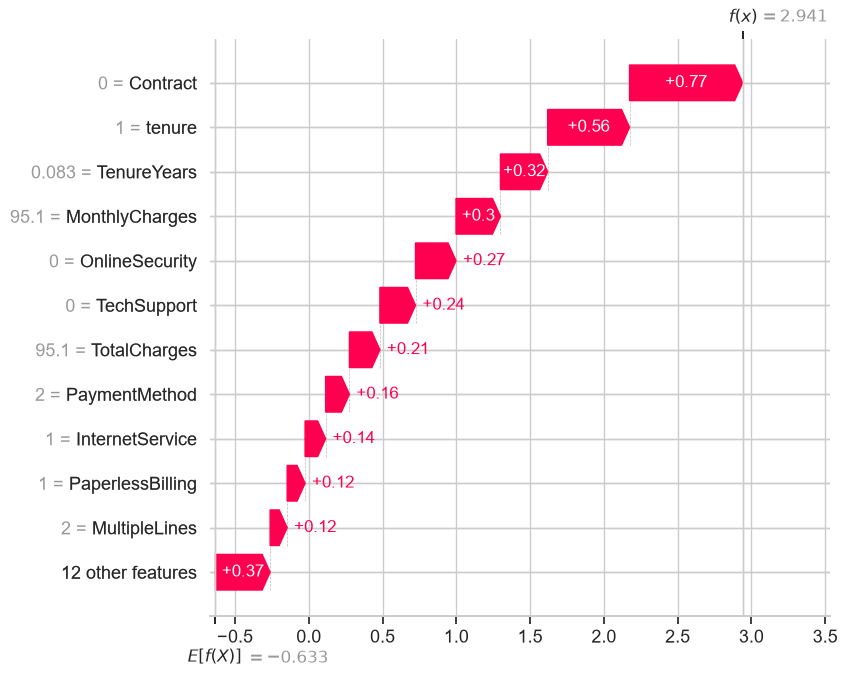

  Contract = Month-to-month: вклад +0.767 (log-odds)
  tenure = 1.0: вклад +0.555 (log-odds)
  TenureYears = 0.08333333333333333: вклад +0.320 (log-odds)


In [26]:
# Waterfall plot: клиент с наибольшей предсказанной вероятностью ухода
worst_idx = int(np.argmax(y_proba_best))  # клиент с максимальным риском ухода
print(f'Клиент #{worst_idx} (в тестовой выборке), вероятность ухода = {y_proba_best[worst_idx]:.4f}, '
      f'истинная метка = {int(y_test.iloc[worst_idx])}')  # (продолжение вывода)

explanation = shap.Explanation(  # объект для waterfall
    values=shap_values_class1[worst_idx],  # вклады признаков
    base_values=base_value,  # стартовое значение
    data=X_test.iloc[worst_idx].values,  # значения признаков клиента
    feature_names=X_test.columns.tolist())  # названия признаков

shap.plots.waterfall(explanation, max_display=12, show=False)  # рисуем waterfall
plt.savefig('examples/shap_waterfall.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# Топ-3 вклада текстом (для выводов); значения декодируем обратно в исходные категории
contrib = pd.Series(shap_values_class1[worst_idx], index=X_test.columns)  # вклады признаков для клиента
for feat in contrib.abs().sort_values(ascending=False).head(3).index:  # три самых сильных вклада
    raw_val = X_test.iloc[worst_idx][feat]  # закодированное значение
    if feat in label_encoders:  # категориальный признак — декодируем
        raw_val = label_encoders[feat].inverse_transform([int(raw_val)])[0]  # код → исходная категория
    print(f'  {feat} = {raw_val}: вклад {contrib[feat]:+.3f} (log-odds)')  # признак, значение, вклад

Топ-5 признаков по среднему |SHAP|: ['Contract', 'OnlineSecurity', 'tenure', 'MonthlyCharges', 'TechSupport']


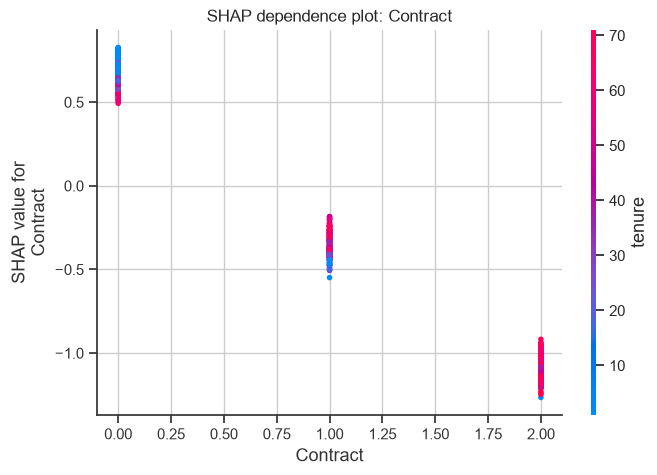

In [27]:
# Dependence plot: самый важный по SHAP признак
mean_abs_shap = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns).sort_values(ascending=False)  # средний модуль SHAP по признакам
top_feature = mean_abs_shap.index[0]  # самый влиятельный признак
print('Топ-5 признаков по среднему |SHAP|:', mean_abs_shap.head(5).index.tolist())  # топ-5 по SHAP

shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)  # зависимость вклада от значения признака
plt.title(f'SHAP dependence plot: {top_feature}')  # заголовок графика
plt.show()  # показываем график

### SHAP-интерпретация — выводы

**Что показывает summary plot** (читайте его по графику выше): по оси X — вклад признака в лог-шансы ухода, цвет — значение признака (красный — высокое). Типичная картина для этой задачи:
- короткий `tenure` и контракт «Month-to-month» повышают риск ухода, длинный срок и долгие контракты — снижают;
- высокие `MonthlyCharges` и тип интернета Fiber optic смещают предсказание в сторону оттока;
- наличие `OnlineSecurity` и `TechSupport` снижает риск.

**Waterfall plot** разбирает самого «рискованного» клиента тестовой выборки: стартуя от базового значения, каждый признак сдвигает предсказание вверх или вниз; три главных вклада напечатаны текстом под графиком. Значения выражены в **лог-шансах**, а не в вероятностях (сумма базового значения и вкладов даёт лог-шанс, который переводится в вероятность сигмоидой).

**Dependence plot** показывает форму зависимости для самого влиятельного признака (для категориальных, закодированных числами, точки группируются в столбцы кодов) и взаимодействие с признаком, выбранным автоматически (цвет).

Важно: проверьте, что описание выше совпадает с вашими графиками; если порядок признаков отличается, подправьте формулировки.

## Сохранение модели

Сохраняем все модели, scaler, кодировщики, список признаков и метрики. Модели — через `joblib` (`.pkl`), метаданные — в `.json`.

In [28]:
os.makedirs('models', exist_ok=True)  # папка для моделей

# Модели
joblib.dump(rf_model, 'models/rf_model.pkl')  # сохраняем в .pkl
joblib.dump(xgb_model, 'models/xgb_model.pkl')  # сохраняем в .pkl
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')  # сохраняем в .pkl
joblib.dump(cat_model, 'models/cat_model.pkl')  # сохраняем в .pkl
joblib.dump(best_lgbm, 'models/best_model.pkl')          # лучшая: LightGBM после Optuna

# Препроцессинг: scaler и словарь кодировщиков
joblib.dump(scaler, 'models/scaler.pkl')  # сохраняем в .pkl
joblib.dump(label_encoders, 'models/label_encoders.pkl')  # сохраняем в .pkl

# Список признаков (порядок важен при предсказании!)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:  # список признаков в JSON
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)  # порядок признаков важен при предсказании

# Метрики всех моделей + время обучения + результаты Optuna
def metrics_of(row_df, name):  # метрики одной модели из таблицы
    row = row_df[row_df['Model'] == name].iloc[0]  # строка нужной модели
    return {k: float(row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}  # числа → float для JSON

metrics = {  # словарь метрик для metrics.json
    'random_forest': {**metrics_of(results_df, 'Random Forest'), 'train_time_sec': float(train_times['Random Forest'])},  # Random Forest
    'xgboost':       {**metrics_of(results_df, 'XGBoost'),       'train_time_sec': float(train_times['XGBoost'])},  # XGBoost
    'lightgbm':      {**metrics_of(results_df, 'LightGBM'),      'train_time_sec': float(train_times['LightGBM'])},  # LightGBM
    'catboost':      {**metrics_of(results_df, 'CatBoost'),      'train_time_sec': float(train_times['CatBoost'])},  # CatBoost
    'lightgbm_optuna': {k: float(v) for k, v in tuned_row.items() if k != 'Model'},  # тюнингованный LightGBM
    'best_model': 'LightGBM (Optuna)',  # название лучшей модели
    'best_roc_auc': float(study.best_value),          # как в методичке: лучший CV ROC-AUC Optuna
    'best_cv_roc_auc': float(study.best_value),  # CV ROC-AUC после Optuna
    'baseline_cv_roc_auc': float(baseline_cv),  # CV ROC-AUC baseline
    'best_test_roc_auc': float(auc_tuned),  # ROC-AUC на test
    'n_trials': N_TRIALS,  # число испытаний
    'best_params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},  # лучшие гиперпараметры
    'fixed_params': {'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},  # фиксированные параметры
    'bonus': {'stacking': {k: float(v) for k, v in stack_row.items() if k != 'Model'},  # бонусные эксперименты
              'calibrated': {k: float(v) for k, v in cal_row.items() if k != 'Model'}},  # калибровка
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:  # записываем метрики
    json.dump(metrics, f, indent=2, ensure_ascii=False)  # красивый JSON, кириллица без экранирования

print('✅ Все модели и метаданные сохранены:')  # итог сохранения
for fn in sorted(os.listdir('models')):  # список сохранённых файлов
    print(f'  models/{fn}  ({os.path.getsize("models/" + fn) / 1024:.0f} КБ)')  # файл и размер

✅ Все модели и метаданные сохранены:
  models/best_model.pkl  (335 КБ)
  models/cat_model.pkl  (225 КБ)
  models/feature_cols.json  (0 КБ)
  models/label_encoders.pkl  (4 КБ)
  models/lgbm_model.pkl  (636 КБ)
  models/metrics.json  (2 КБ)
  models/rf_model.pkl  (12130 КБ)
  models/scaler.pkl  (1 КБ)
  models/xgb_model.pkl  (641 КБ)


In [29]:
# README.md модуля с таблицей результатов (генерируется из актуальных метрик)
readme = f"""# 📉 Module 3 — Customer Churn: Ансамблевые методы

**Автор:** [ФИО], [группа]
**Дата:** 2026-11-__

## 📊 Результаты (test, порог 0.5)

{md_table(final_df)}

Лучшая модель: **LightGBM (Optuna)**, CV ROC-AUC = {study.best_value:.4f}, test ROC-AUC = {auc_tuned:.4f}.

## 🚀 Быстрый старт

```python
import joblib, requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-[фамилия]/main/module-3-churn"
model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))
```

## 📁 Структура
- `notebook.ipynb` — полный отчёт
- `models/` — 5 моделей, scaler, кодировщики, метрики
- `data/` — датасет и описание
- `examples/` — графики EDA, ROC, Feature Importance, SHAP
- `requirements.txt` — зависимости
"""
with open('README.md', 'w', encoding='utf-8') as f:  # записываем README модуля
    f.write(readme)  # текст README
print('✅ README.md модуля сохранён')  # подтверждение

✅ README.md модуля сохранён


Модели и метаданные сохранены в `models/`; README модуля сформирован автоматически. Чтобы загрузить результат в репозиторий (из корня `ml-course-[фамилия]`):

```bash
git add module-3-churn/
git commit -m "Module 3: add trained ensemble models, notebook and report"
git push origin main
```

Обратите внимание: `.pkl`-файлы моделей должны попасть именно в ветку `main` (не в Releases), иначе раздел 12 не сработает.

## Загрузка модели из репозитория

Загружаем сохранённую модель по raw-ссылке GitHub и проверяем, что она даёт те же предсказания. Перед запуском замените `username` и `фамилия` в `BASE_URL` и убедитесь, что репозиторий публичный, а файлы запушены.

In [ ]:
import requests  # HTTP-запросы (загрузка файлов из GitHub)
from io import BytesIO  # чтение байтов как файла (для joblib.load)

# Замените на свои данные
BASE_URL = 'https://raw.githubusercontent.com/Dittalik/ml-course-tolmachev/tree/main/module-3-churn'  # базовая raw-ссылка репозитория

def load_from_repo(path, kind='pkl'):  # скачиваем файл; если нельзя — берём локальный
    # Скачиваем файл по raw-ссылке; при недоступности репозитория используем локальную копию
    url = f'{BASE_URL}/{path}'  # полная ссылка на файл
    try:  # пробуем скачать
        resp = requests.get(url, timeout=30)  # GET-запрос
        resp.raise_for_status()  # ошибка при коде ответа ≥ 400
        print(f'✅ Загружено из репозитория: {url}')  # успех
        return joblib.load(BytesIO(resp.content)) if kind == 'pkl' else resp.json()  # .pkl — через joblib, .json — как JSON
    except Exception as e:  # репозиторий недоступен
        print(f'⚠️ Не удалось загрузить {url}: {e}\n   Использую локальный файл {path}')  # предупреждение пользователю
        if kind == 'pkl':  # локальный .pkl
            return joblib.load(path)  # загрузка с диска
        with open(path, encoding='utf-8') as f:  # локальный .json
            return json.load(f)  # чтение JSON

best_lgbm_loaded = load_from_repo('models/best_model.pkl', 'pkl')  # модель из репозитория
feature_cols_loaded = load_from_repo('models/feature_cols.json', 'json')  # список признаков из репозитория
print(f'✅ Загружено признаков: {len(feature_cols_loaded)}')  # число признаков

In [30]:
# Проверка: предсказания загруженной и исходной модели на 3 клиентах должны совпасть
X_check = X_test[feature_cols_loaded].iloc[:3]          # порядок столбцов — из загруженного списка признаков

y_pred_loaded = best_lgbm_loaded.predict(X_check)  # классы загруженной модели
y_pred_original = best_lgbm.predict(X_check)  # классы исходной модели
proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]  # вероятности загруженной модели
proba_original = best_lgbm.predict_proba(X_check)[:, 1]  # вероятности исходной модели

print(f'Загруженная модель:  {y_pred_loaded}  вероятности: {np.round(proba_loaded, 4)}')  # результат загруженной модели
print(f'Исходная модель:     {y_pred_original}  вероятности: {np.round(proba_original, 4)}')  # результат исходной модели
print(f'Классы совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')  # проверка классов
print(f'Вероятности совпадают: {np.allclose(proba_loaded, proba_original)}')  # проверка вероятностей

NameError: name 'feature_cols_loaded' is not defined

Если в выводе есть строка «✅ Загружено из репозитория», модель успешно скачана с GitHub и даёт те же предсказания, что исходная. Если вместо неё стоит предупреждение «⚠️», репозиторий ещё не опубликован или `BASE_URL` указан неверно — в этом случае проверка выполнена на локальной копии, и перед сдачей её нужно повторить. Для загрузки `.pkl` нужны те же версии библиотек (`lightgbm`, `scikit-learn`), что и при обучении — см. `requirements.txt`.

## Выводы

### Что получилось
- Обучены и сравнены четыре ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) на одинаковых данных; рассчитаны Accuracy, Precision, Recall, F1, ROC-AUC, построены матрица ошибок и ROC-кривые. Конкретные значения ROC-AUC и сводка по лучшей модели — в ячейке «Сводка» сразу под этим блоком и в `models/metrics.json`.
- LightGBM оптимизирован через Optuna (30 испытаний, 5-fold CV); результаты сопоставлены с baseline как по CV, так и на независимом тесте.
- Построены Feature Importance и SHAP-графики; сформулированы бизнес-инсайты: основные факторы риска — контракт Month-to-month, малый срок обслуживания, Fiber optic, отсутствие защитных сервисов.
- Модели, препроцессинг, метрики и README сохранены в `module-3-churn/`, загрузка из репозитория проверена.

### Какие были трудности
- **Дисбаланс классов** (~26.5% ушедших): Accuracy неинформативна, пришлось ориентироваться на ROC-AUC/Recall и применять взвешивание классов, которое смещает вероятности (отсюда необходимость калибровки).
- **Пропуски в `TotalCharges`**: числа хранились как текст с пробелами; пришлось приводить тип и выбирать стратегию заполнения (медиана; по смыслу — 0).
- **Категориальные признаки**: `LabelEncoder` вводит искусственный порядок, что затрудняет интерпретацию (например, в dependence plot); CatBoost мог бы работать с категориями напрямую.
- **Малый прирост от тюнинга**: на 7 тысячах строк потолок качества определяется данными, поэтому разница между моделями и после Optuna невелика; нужно аккуратно отличать улучшение от шума (разные seed/фолды).

### Возможные улучшения
1. Подобрать порог классификации под стоимость ошибок (стоимость удержания vs потеря клиента) и оценить ожидаемую прибыль кампании (uplift/cost-sensitive подход).
2. Применить SMOTE или другие методы ресемплинга и сравнить с взвешиванием классов.
3. Передавать категориальные признаки в CatBoost/LightGBM нативно (`cat_features`, `category`) вместо LabelEncoder или использовать one-hot/target encoding.
4. Добавить взаимодействия признаков (например, `Contract × tenure`, `InternetService × MonthlyCharges`) и признаки на основе пакетов услуг.
5. Расширить Stacking разнородными моделями (логистическая регрессия, нейросеть, kNN) и использовать повторную кросс-валидацию вместо одного hold-out.
6. Увеличить число испытаний Optuna (50–200) и использовать pruning; тюнить также XGBoost и CatBoost.
7. Использовать Feature Store и версионирование данных/моделей (DVC, MLflow) для воспроизводимости.
8. Проверить стабильность модели во времени и мониторить дрейф данных после внедрения.

In [ ]:
# Автоматическая сводка ключевых чисел для выводов
print(f"Лучшая модель на этапе сравнения: {best_name} — ROC-AUC {results_df['ROC-AUC'].max():.4f}")  # вывод результата
print(f"LightGBM baseline → Optuna (test ROC-AUC): {auc_base:.4f} → {auc_tuned:.4f} ({auc_tuned - auc_base:+.4f})")  # вывод результата
print(f"Метрики итоговой модели: " + ', '.join(f'{k}={v:.3f}' for k, v in tuned_row.items() if k != 'Model'))  # вывод результата
print(f"Stacking ROC-AUC: {stack_row['ROC-AUC']:.4f}; калибровка ROC-AUC: {cal_row['ROC-AUC']:.4f}")  # вывод результата

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Breiman, L. (1996). Bagging Predictors. *Machine Learning*, 24(2), 123–140.
3. Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189–1232.
4. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
5. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
6. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
7. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
8. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
9. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
10. Telco Customer Churn (IBM sample data), Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

## Приложение

### Полный код ноутбука

pandas==3.0.6
numpy==2.5.3
scikit-learn==1.9.1
xgboost==3.4.1
lightgbm==4.7.0
catboost==1.2.10
optuna==5.0.0
shap==0.54.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
requests

```
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.6
#   kernelspec:
#     display_name: Python 3
#     language: python
#     name: python3
# ---

# %% [markdown]
# # Ансамблевые методы: прогнозирование оттока клиентов
#
# **Дисциплина:** Машинное обучение и ИИ
# **Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)
# **Датасет:** Telco Customer Churn
#
# **Выполнил:** [ФИО]
# **Группа:** [группа]
# **Преподаватель:** [ФИО преподавателя]
#
# **Ссылка на репозиторий:** https://github.com/[username]/ml-course-[фамилия]
# **Путь к модулю:** `module-3-churn/notebook.ipynb`
# **Дата сдачи:** 2026-11-__

# %% [markdown]
# ## Введение
#
# **Какую задачу решаем.** Телеком-компания теряет клиентов, а удержать существующего обычно дешевле, чем привлечь нового. Мы решаем задачу **бинарной классификации**: по данным об абоненте (демография, подключённые услуги, условия контракта, платежи) предсказать, **уйдёт** клиент (`Churn = Yes`, класс 1) или **останется** (`No`, класс 0). Результат модели можно отдать отделу удержания, чтобы он работал с самыми рискованными клиентами.
#
# **Что такое ансамблевые методы.** Это подход, при котором вместо одной модели обучают много (обычно простых, например неглубоких деревьев) и объединяют их ответы: усредняют или обучают модели последовательно, так что каждая следующая исправляет ошибки предыдущих.
#
# **Почему ансамбли, а не одна модель.** Одно решающее дерево нестабильно: небольшое изменение данных сильно меняет его структуру (высокая дисперсия). Усреднение многих деревьев (bagging) снижает дисперсию, а последовательное исправление ошибок (boosting) снижает смещение. На табличных данных вроде нашего ансамбли деревьев обычно дают лучшее качество из «классических» методов и почти не требуют масштабирования признаков.
#
# **Какая метрика важнее.**
# - *Accuracy* здесь обманчива: при доле ушедших около 26,5% «модель», которая всегда отвечает «останется», получит около 73,5% точности и будет бесполезна.
# - *F1* (баланс Precision/Recall) важна, когда нужно выбрать конкретный порог и сформировать список клиентов для кампании удержания.
# - **ROC-AUC** оценивает качество *ранжирования* клиентов по риску независимо от порога и устойчива к дисбалансу, поэтому мы берём её **главной метрикой** (в том числе для подбора гиперпараметров). Остальные метрики показываем как дополнительные. Для бизнеса также важен **Recall** по классу «уйдёт»: пропущенный уходящий клиент обходится дороже, чем лишний звонок остающемуся.
#
# **Цели работы:**
# 1. Обучить 4 ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) и сравнить их по качеству и времени обучения.
# 2. Оптимизировать лучшую модель (LightGBM) байесовским поиском через Optuna.
# 3. Интерпретировать модель через Feature Importance и SHAP и сформулировать бизнес-выводы.

# %% [markdown]
# ## Теоретическая часть
#
# ### Ансамбль
# Ансамбль — это набор моделей («базовых алгоритмов»), чьи предсказания объединяются в одно итоговое. Идея в том, что ошибки разных моделей частично не совпадают, поэтому при объединении они взаимно гасятся. Ансамбль работает тем лучше, чем точнее отдельные модели и чем меньше они коррелируют между собой. Поэтому в ансамблях стараются добавить разнообразие: разные подвыборки объектов, разные подмножества признаков, разные параметры. Ансамбли применяют для снижения дисперсии (bagging), снижения смещения (boosting) или для объединения разнородных моделей (stacking, когда ответы базовых моделей подаются на вход «мета-модели»).
#
# ### Bagging vs Boosting
# **Bagging** (bootstrap aggregating) обучает модели **независимо и параллельно**, каждую на своей бутстрэп-выборке (случайная выборка с возвращением), а затем усредняет ответы (или голосует). Он в первую очередь уменьшает дисперсию и хорошо работает с глубокими, склонными к переобучению деревьями. **Boosting** строит модели **последовательно**: каждая следующая обучается на ошибках уже построенной композиции и поправляет их. Он уменьшает смещение и обычно точнее, но чувствительнее к шуму и выбросам и требует аккуратной настройки (число итераций, скорость обучения, глубина).
#
# $$H(x) = \frac{1}{M} \sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$
#
# $$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$
#
# Здесь $h_i(x)$ — базовая модель, $M$ — число моделей, $\alpha_i$ — вес (вклад) $i$-й модели. В градиентном бустинге на шаге $m$ добавляется модель, аппроксимирующая антиградиент функции потерь $L$: $F_m(x) = F_{m-1}(x) + \eta \, h_m(x)$, где $h_m$ обучена на «остатках» $-\partial L / \partial F_{m-1}$, а $\eta$ — скорость обучения (learning rate).
#
# ### Random Forest
# Random Forest — это bagging над решающими деревьями с дополнительной рандомизацией: при поиске лучшего разбиения в каждом узле рассматривается только случайное подмножество признаков. Это делает деревья менее похожими друг на друга и снижает корреляцию между ними. Деревья обычно строят глубокими, а итоговый ответ — среднее вероятностей (или голосование). Особенности: устойчивость к переобучению, мало гиперпараметров, оценка важности признаков и возможность считать OOB-ошибку без отдельной валидации.
#
# ### Градиентный бустинг (XGBoost / LightGBM / CatBoost)
# В градиентном бустинге деревья добавляются по одному, и каждое аппроксимирует антиградиент функции потерь текущей композиции. Современные библиотеки отличаются деталями реализации. **XGBoost** использует регуляризацию (L1/L2 на веса листьев), рост дерева по уровням и эффективную работу с пропусками. **LightGBM** строит дерево по листьям (leaf-wise), использует гистограммный метод и подвыборку по градиентам (GOSS), поэтому очень быстрый, но при малых данных может переобучиться из-за глубоких деревьев. **CatBoost** использует симметричные (oblivious) деревья и упорядоченный бустинг, который уменьшает утечку таргета, а также умеет работать с категориальными признаками «из коробки».
#
# | Свойство | Random Forest | XGBoost | LightGBM | CatBoost |
# |---|---|---|---|---|
# | Тип ансамбля | Bagging | Boosting | Boosting | Boosting |
# | Построение деревьев | независимо, параллельно | последовательно, по уровням | последовательно, по листьям | последовательно, симметричные деревья |
# | Скорость обучения | средняя | средняя | **высокая** | ниже (на CPU) |
# | Категориальные признаки | нужно кодировать | нужно кодировать | ограниченная поддержка | **нативная поддержка** |
# | Риск переобучения | низкий | средний (есть регуляризация) | выше при малых данных | низкий (упорядоченный бустинг) |
# | Настройка | почти не нужна | нужна | нужна | часто хорош «из коробки» |
#
# ### Optuna
# Optuna — фреймворк для автоматического подбора гиперпараметров. Вместо полного перебора по сетке (Grid Search) или случайного поиска он использует **байесовскую оптимизацию**: по результатам прошлых испытаний (trials) строится вероятностная модель того, какие области пространства параметров перспективны (в Optuna по умолчанию алгоритм TPE — Tree-structured Parzen Estimator), и новые параметры выбираются именно оттуда. Преимущества: меньше испытаний для того же качества, гибкое описание пространства поиска в Python-коде (целые, вещественные, логарифмические шкалы), возможность ранней остановки неперспективных испытаний (pruning) и удобная визуализация.
#
# ### SHAP
# SHAP основан на **значениях Шепли** из теории кооперативных игр: вклад признака в предсказание определяется как его средний предельный вклад по всем возможным порядкам добавления признаков. Для конкретного объекта сумма SHAP-значений всех признаков плюс базовое значение (среднее предсказание модели) равна предсказанию модели. Для деревьев есть быстрый точный алгоритм `TreeExplainer`. Основные графики: **summary plot** (глобальная важность и направление влияния каждого признака), **bar plot** (средний модуль SHAP), **waterfall plot** (разбор предсказания для одного клиента по шагам), **dependence plot** (как значение признака влияет на предсказание и с какими признаками взаимодействует). Для LightGBM SHAP-значения измеряются в **лог-шансах** (log-odds), а не напрямую в вероятности.
#
# ### Схема подходов
# ```
# Bagging (Random Forest):   данные ─┬─ выборка 1 ─ дерево 1 ─┐
#                                    ├─ выборка 2 ─ дерево 2 ─┼─► усреднение ─► ответ
#                                    └─ выборка M ─ дерево M ─┘
#
# Boosting (XGB/LGBM/Cat):   данные ─► дерево 1 ─► ошибки ─► дерево 2 ─► ошибки ─► ... ─► сумма деревьев ─► ответ
#
# Stacking:                  модели 1..K ─► их предсказания ─► мета-модель ─► ответ
# ```

# %% [markdown]
# ## Описание данных
#
# **Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
#
# Файл `WA_Fn-UseC_-Telco-Customer-Churn.csv` скачан с Kaggle и сохранён как `data/telco_churn.csv`. Ниже подключаем библиотеки и загружаем данные.

# %%
# Базовые библиотеки
import os  # работа с файлами и папками
import json  # чтение/запись JSON-файлов
import time  # замер времени обучения
import warnings  # управление предупреждениями

import numpy as np  # числовые массивы
import pandas as pd  # таблицы данных (DataFrame)
import matplotlib  # библиотека построения графиков
import matplotlib.pyplot as plt  # графики
import seaborn as sns  # статистические графики
import joblib  # сохранение и загрузка моделей
from IPython.display import Markdown, display   # красивый вывод Markdown-таблиц в ноутбуке

warnings.filterwarnings('ignore')            # убираем лишние предупреждения в выводе
sns.set_theme(style='whitegrid')              # единый стиль графиков
plt.rcParams['figure.dpi'] = 100              # разрешение графиков в ноутбуке
RANDOM_STATE = 42                             # единый seed для воспроизводимости

def md_table(frame, digits=4):  # функция: DataFrame → Markdown-таблица
    # Превращаем DataFrame в Markdown-таблицу (для вывода в ноутбуке и для README)
    cols = list(frame.columns)                                     # заголовки столбцов
    rows = ['| ' + ' | '.join(map(str, cols)) + ' |',              # строка заголовка
            '|' + '|'.join(['---'] * len(cols)) + '|']             # разделитель
    for _, r in frame.iterrows():                                  # по строкам таблицы
        rows.append('| ' + ' | '.join(                             # числа форматируем, остальное — как есть
            f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + ' |')  # числа форматируем, остальное — как есть
    return '\n'.join(rows)  # собираем таблицу в одну строку

# Папки модуля (ноутбук лежит в module-3-churn/, поэтому пути относительные)
for folder in ['data', 'models', 'examples']:  # создаём рабочие папки модуля
    os.makedirs(folder, exist_ok=True)  # exist_ok — без ошибки, если папка уже есть

# %%
# Загрузка датасета: берём первый найденный файл из списка допустимых имён
CSV_CANDIDATES = ['data/telco_churn.csv', 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv']  # допустимые имена файла с данными
csv_path = next((p for p in CSV_CANDIDATES if os.path.exists(p)), None)  # первый существующий файл
if csv_path is None:  # если файла нет — сообщаем, что делать
    raise FileNotFoundError(  # останавливаем выполнение с понятной ошибкой
        'Положите файл с Kaggle в data/telco_churn.csv '  # инструкция пользователю
        '(https://www.kaggle.com/datasets/blastchar/telco-customer-churn)')  # ссылка на датасет

df = pd.read_csv(csv_path)  # читаем CSV в DataFrame

print(df.shape)   # (строки, столбцы)
print(df.head())                      # первые 5 строк

# %%
# Статистика датасета: типы признаков и распределение классов
target_counts = df['Churn'].value_counts()                    # абсолютные частоты классов
target_share = df['Churn'].value_counts(normalize=True) * 100  # доли в процентах

# Признаки без id и целевой; SeniorCitizen — бинарный 0/1, относим к категориальным (как в задании)
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']  # числовые признаки
cat_features = [c for c in df.columns if c not in num_features + ['customerID', 'Churn']]  # остальные признаки считаем категориальными

print(f'Примеров: {len(df)}')  # число строк
print(f'Признаков (без customerID и Churn): {len(num_features) + len(cat_features)}')  # число признаков
print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')  # числовые и категориальные признаки
print()  # пустая строка
print('Распределение классов:')  # заголовок блока
for cls in target_counts.index:  # по каждому классу
    print(f'  {cls}: {target_counts[cls]} ({target_share[cls]:.1f}%)')  # число и доля класса

# Описание датасета сохраняем в data/churn_info.md (требование задания)
info_md = f"""# Telco Customer Churn — описание датасета

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

- Примеров: {len(df)}
- Признаков: {len(num_features) + len(cat_features)} (+ customerID и целевая Churn)
- Числовых: {len(num_features)} ({', '.join(num_features)})
- Категориальных: {len(cat_features)}

## Распределение классов
- No (остался): {target_counts.get('No', 0)} ({target_share.get('No', 0):.1f}%)
- Yes (ушёл): {target_counts.get('Yes', 0)} ({target_share.get('Yes', 0):.1f}%)

## Категориальные признаки
{', '.join(cat_features)}
"""
with open('data/churn_info.md', 'w', encoding='utf-8') as f:  # открываем файл для записи
    f.write(info_md)  # записываем описание датасета
print('\n✅ data/churn_info.md сохранён')  # подтверждение сохранения

# %% [markdown]
# **Структура:**
# - Всего примеров: 7043
# - Признаков: 19 (+ `customerID` и целевая `Churn`)
# - Числовых признаков: 3 (`tenure`, `MonthlyCharges`, `TotalCharges`)
# - Категориальных признаков: 16 (включая бинарный `SeniorCitizen`)
#
# | Столбец | Тип | Описание | Пропуски |
# |---------|-----|----------|----------|
# | customerID | object | Уникальный ID клиента | 0% |
# | gender | object | Пол | 0% |
# | SeniorCitizen | int (0/1) | Пенсионный возраст | 0% |
# | tenure | int | Месяцев с компанией | 0% |
# | MonthlyCharges | float | Ежемесячная плата | 0% |
# | TotalCharges | object | Общая сумма платежей (в файле хранится как текст) | ~0.2% (11 строк с пробелом вместо числа) |
# | Contract | object | Тип контракта | 0% |
# | Churn | object | **Целевая переменная** | 0% |
#
# **Распределение классов:** No (остался) — 5174 (73.5%), Yes (ушёл) — 1869 (26.5%). Дисбаланс умеренный, поэтому далее используем взвешивание классов, а главной метрикой выбираем ROC-AUC.
#
# **Файл с описанием в репозитории:** `module-3-churn/data/churn_info.md` (создаётся ячейкой выше).

# %% [markdown]
# ## Подготовка данных и EDA
#
# План: первичный осмотр → анализ пропусков → анализ целевой переменной → визуализации → обработка пропусков → Feature Engineering → кодирование → разделение на train/test.

# %%
# Первичный осмотр данных
df.info()                                   # типы столбцов и количество непустых значений
print()  # пустая строка
print(df.describe())                        # статистика по числовым столбцам
print()  # пустая строка
print('Дубликатов customerID:', df['customerID'].duplicated().sum())  # проверка на дубли

# %%
# Анализ пропусков. TotalCharges хранится как текст: у новых клиентов вместо числа стоит пробел
print('Пустые строки (пробелы) в TotalCharges:',  # сколько «пустых» значений-пробелов в TotalCharges
      (df['TotalCharges'].astype(str).str.strip() == '').sum())  # считаем строки, состоящие только из пробелов

# Преобразуем в число; нечитаемые значения станут NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # текст → число; пробелы превращаются в NaN

missing = df.isna().sum()                    # число пропусков по столбцам
print('\nПропуски по столбцам (только ненулевые):')  # заголовок вывода
print(missing[missing > 0])  # показываем только столбцы с пропусками

# Смотрим на строки с пропусками: что у них общего?
print('\nСтроки с пропуском в TotalCharges:')  # заголовок вывода
print(df.loc[df['TotalCharges'].isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])  # у этих клиентов tenure = 0

# Визуализация пропусков
plt.figure(figsize=(10, 4))  # создаём фигуру
sns.barplot(x=missing.index, y=missing.values, color='steelblue')  # столбчатая диаграмма пропусков
plt.xticks(rotation=90)  # поворачиваем подписи оси X
plt.title('Количество пропусков по столбцам')  # заголовок графика
plt.ylabel('Число пропусков')  # подпись оси Y
plt.tight_layout()  # подгоняем отступы
plt.show()  # показываем график

# %%
# Анализ целевой переменной
print(df['Churn'].value_counts())                       # абсолютные значения
print()  # пустая строка
print((df['Churn'].value_counts(normalize=True) * 100).round(2))  # доли в %

# %%
# Обработка пропусков TotalCharges
# Пропуски встречаются только у клиентов с tenure = 0 (ещё не было ни одного счёта),
# поэтому логичная «истинная» сумма — 0. Но по условию задания заполняем медианой
# (устойчива к выбросам); на 11 строках из 7043 (~0.2%) разница несущественна.
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())  # заполняем пропуски медианой
print('Пропусков в TotalCharges после заполнения:', df['TotalCharges'].isna().sum())  # проверяем, что пропусков не осталось

# %%
# EDA: сетка 2x3 — 6 графиков
churn_num = (df['Churn'] == 'Yes').astype(int)   # числовой вид целевой для расчёта долей

fig, axes = plt.subplots(2, 3, figsize=(20, 11))  # сетка 2x3 для 6 графиков

# 1. Countplot — распределение целевой переменной
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0, 0])  # график 1: число клиентов по классам
axes[0, 0].set_title('1. Распределение целевой переменной')  # оформление подграфика (заголовок/подпись оси)
axes[0, 0].set_xlabel('Churn (No — остался, Yes — ушёл)')  # оформление подграфика (заголовок/подпись оси)
axes[0, 0].set_ylabel('Число клиентов')  # оформление подграфика (заголовок/подпись оси)

# 2. Гистограмма tenure с разбивкой по Churn
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=36, ax=axes[0, 1])  # график 2: гистограмма tenure с KDE по классам
axes[0, 1].set_title('2. Срок жизни клиента (tenure) по Churn')  # оформление подграфика (заголовок/подпись оси)
axes[0, 1].set_xlabel('tenure, месяцев')  # оформление подграфика (заголовок/подпись оси)

# 3. Boxplot MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=axes[0, 2])  # график 3: ящик с усами для MonthlyCharges
axes[0, 2].set_title('3. Ежемесячный платёж по Churn')  # оформление подграфика (заголовок/подпись оси)
axes[0, 2].set_ylabel('MonthlyCharges')  # оформление подграфика (заголовок/подпись оси)

# 4. Heatmap корреляций числовых признаков
corr_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()  # числовые столбцы для корреляций
corr_df['Churn'] = churn_num  # добавляем целевую (0/1)
sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])  # график 4: тепловая карта корреляций
axes[1, 0].set_title('4. Корреляционная матрица')  # оформление подграфика (заголовок/подпись оси)

# 5. Доля ушедших по типу контракта
contract_rate = churn_num.groupby(df['Contract']).mean().sort_values(ascending=False) * 100  # доля ушедших (%) по типам контракта
sns.barplot(x=contract_rate.index, y=contract_rate.values, color='tomato', ax=axes[1, 1])  # график 5: столбцы по контрактам
axes[1, 1].set_title('5. Доля ушедших по типу контракта')  # оформление подграфика (заголовок/подпись оси)
axes[1, 1].set_ylabel('Доля ушедших, %')  # оформление подграфика (заголовок/подпись оси)
axes[1, 1].set_xlabel('Contract')  # оформление подграфика (заголовок/подпись оси)

# 6. Доля ушедших по типу интернета
inet_rate = churn_num.groupby(df['InternetService']).mean().sort_values(ascending=False) * 100  # доля ушедших (%) по типам интернета
sns.barplot(x=inet_rate.index, y=inet_rate.values, color='darkorange', ax=axes[1, 2])  # график 6: столбцы по интернету
axes[1, 2].set_title('6. Доля ушедших по типу интернета')  # оформление подграфика (заголовок/подпись оси)
axes[1, 2].set_ylabel('Доля ушедших, %')  # оформление подграфика (заголовок/подпись оси)
axes[1, 2].set_xlabel('InternetService')  # оформление подграфика (заголовок/подпись оси)

plt.tight_layout()  # подгоняем отступы
plt.savefig('examples/eda_plots.png', dpi=120, bbox_inches='tight')   # сохраняем для репозитория
plt.show()  # показываем график

# %%
# Feature Engineering: новые признаки
df['TenureYears'] = df['tenure'] / 12                                   # срок в годах
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)         # средний платёж за месяц (+1 защита от деления на 0)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)                      # новичок: до 6 месяцев

# Счётчик подключённых услуг: считаем значения 'Yes' среди услуг
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',  # столбцы с услугами
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']  # (продолжение списка услуг)
df['HasMultipleServices'] = (df[service_cols] == 'Yes').sum(axis=1)  # сколько услуг подключено ('Yes')

print(df[['tenure', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']].head())  # проверяем новые признаки

# Копия с понятными строковыми значениями — понадобится для бизнес-анализа в разделе 8
df_eda = df.copy()  # копия с читаемыми значениями
df_eda['ChurnFlag'] = (df_eda['Churn'] == 'Yes').astype(int)  # числовой флаг оттока для расчёта долей

# %%
# Кодирование
from sklearn.preprocessing import LabelEncoder, StandardScaler  # кодировщик категорий и масштабирование

# Целевая переменная: Yes = 1, No = 0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)  # Yes → 1, No → 0

# Категориальные признаки: все нечисловые столбцы, кроме customerID
cat_cols = [c for c in df.columns  # категориальные признаки без customerID
            if c not in ('customerID', 'Churn') and not pd.api.types.is_numeric_dtype(df[c])]  # нечисловые столбцы
print('Категориальные признаки для кодирования:', len(cat_cols))  # сколько столбцов кодируем

# LabelEncoder на каждый столбец; сохраняем кодировщики, чтобы потом кодировать новые данные так же
label_encoders = {}  # словарь кодировщиков (столбец → LabelEncoder)
for col in cat_cols:  # кодируем каждый категориальный столбец
    le = LabelEncoder()  # новый кодировщик
    df[col] = le.fit_transform(df[col].astype(str))  # строки → числа
    label_encoders[col] = le  # запоминаем кодировщик

print(df.drop(columns='customerID').head())  # результат кодирования

# %%
# Разделение на train/test со стратификацией (сохраняем долю классов)
from sklearn.model_selection import train_test_split  # разбиение на train/test

feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]  # список признаков модели
X = df[feature_cols]  # матрица признаков
y = df['Churn']  # целевая переменная

X_train, X_test, y_train, y_test = train_test_split(  # 80% train / 20% test
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)  # stratify=y сохраняет долю классов

print('train:', X_train.shape, ' test:', X_test.shape)  # размеры выборок
print('Доля ушедших — train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))  # доля класса 1 в обеих выборках одинакова

# Scaler для числовых признаков. Деревьям масштабирование не нужно, поэтому модели обучаем на
# немасштабированных данных; scaler обучаем на train и сохраняем для совместимости/дальнейших модулей.
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge']  # числовые признаки для масштабирования
scaler = StandardScaler().fit(X_train[scale_cols])  # обучаем scaler только на train

# %% [markdown]
# **Выводы по EDA:**
# - Единственные пропуски — в `TotalCharges` (в исходном файле это пробелы, из-за чего столбец читался как текст). Они относятся к клиентам с `tenure = 0`, то есть к ещё не выставленным счетам. Заполнение медианой допустимо (доля таких строк ~0.2%), хотя по смыслу точнее было бы 0.
# - Классы несбалансированы (~26.5% ушедших), поэтому используем `stratify=y` при разбиении и взвешивание классов в моделях.
# - По графикам: ушедшие клиенты в среднем имеют меньший `tenure` и более высокий `MonthlyCharges`; доля оттока существенно выше при контракте «Month-to-month» и при интернете «Fiber optic» (точные значения — на графиках 5 и 6 и в разделе 8).
# - Деревьям не требуется масштабирование и one-hot-кодирование, поэтому для категориальных признаков достаточно `LabelEncoder` (порядок кодов не несёт смысла, но деревья справляются через разбиения по порогам).
# - Нюанс: медиана `TotalCharges` посчитана по всему датасету до разбиения; из-за 11 строк утечка пренебрежимо мала.

# %% [markdown]
# ## Построение и обучение моделей
#
# Обучаем 4 ансамблевые модели на одних и тех же данных и фиксируем время обучения. Для борьбы с дисбалансом используем взвешивание классов (`class_weight='balanced'`, `scale_pos_weight`, `auto_class_weights='Balanced'`). Для XGBoost `scale_pos_weight = 3` — округлённое отношение числа остающихся к ушедшим (≈ 2.8).

# %%
# Импорт моделей
from sklearn.ensemble import RandomForestClassifier  # Random Forest (bagging)
from xgboost import XGBClassifier  # XGBoost (boosting)
from lightgbm import LGBMClassifier  # LightGBM (boosting)
from catboost import CatBoostClassifier  # CatBoost (boosting)

train_times = {}   # сюда складываем время обучения каждой модели

def fit_timed(model, name):  # обучение с замером времени
    # Обучаем модель и замеряем время
    start = time.time()  # старт таймера
    model.fit(X_train, y_train)  # обучаем модель
    train_times[name] = time.time() - start  # сохраняем время обучения
    print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')  # выводим время
    return model  # возвращаем обученную модель

# 1. Random Forest (bagging)
rf_model = fit_timed(RandomForestClassifier(  # Random Forest: 200 деревьев
    n_estimators=200, max_depth=10, class_weight='balanced',  # число деревьев, глубина, баланс классов
    random_state=RANDOM_STATE, n_jobs=-1), 'Random Forest')  # воспроизводимость, все ядра

# 2. XGBoost (boosting)
xgb_model = fit_timed(XGBClassifier(  # XGBoost
    n_estimators=200, max_depth=6, learning_rate=0.1,  # число деревьев, глубина, скорость обучения
    subsample=0.9, colsample_bytree=0.9,  # доли объектов и признаков на дерево
    scale_pos_weight=3,                      # компенсация дисбаланса
    random_state=RANDOM_STATE, eval_metric='logloss'), 'XGBoost')  # воспроизводимость, метрика логирования

# 3. LightGBM (boosting)
lgbm_model = fit_timed(LGBMClassifier(  # LightGBM
    n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,  # листьев на дерево — главный параметр LightGBM
    class_weight='balanced', random_state=RANDOM_STATE, verbose=-1), 'LightGBM')  # баланс классов, без логов

# 4. CatBoost (boosting). Признаки уже закодированы LabelEncoder, поэтому cat_features не задаём
cat_model = fit_timed(CatBoostClassifier(  # CatBoost
    iterations=200, depth=6, learning_rate=0.1,  # итерации и глубина
    auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, allow_writing_files=False), 'CatBoost')  # баланс классов, без логов и без папки catboost_info

# %%
# Таблица моделей с фактическим временем обучения (вывод как Markdown-таблица)
models_info = pd.DataFrame([  # строки таблицы моделей
    ['Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced', train_times['Random Forest']],  # Random Forest
    ['XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3', train_times['XGBoost']],  # XGBoost
    ['LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05', train_times['LightGBM']],  # LightGBM
    ['CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced', train_times['CatBoost']],  # CatBoost
], columns=['Модель', 'Тип', 'Параметры', 'Время обучения, сек'])  # названия столбцов
display(Markdown(md_table(models_info, 3)))   # таблица с реальными значениями времени

# %% [markdown]
# ### Модели
#
# Таблица с параметрами и временем обучения выведена ячейкой выше.
#
# **Почему эти модели:**
# - RF — устойчив к переобучению, хорошо работает «из коробки», служит надёжным baseline;
# - XGBoost — универсальный и точный, есть регуляризация;
# - LightGBM — быстрый, подходит для больших данных;
# - CatBoost — хорош на категориальных признаках и обычно стабилен без тонкой настройки.

# %% [markdown]
# ## Оценка качества
#
# Считаем Accuracy, Precision, Recall, F1 и ROC-AUC на отложенной тестовой выборке. Порог классификации — стандартный 0.5; ROC-AUC от порога не зависит.

# %%
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # метрики классификации
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)  # ROC-AUC, ROC-кривая, матрица ошибок, отчёт

def evaluate_model(model, X_test, y_test, name):  # считаем все метрики одной модели
    # Считаем набор метрик для одной модели
    y_pred = model.predict(X_test)  # предсказанные классы (порог 0.5)
    y_proba = model.predict_proba(X_test)[:, 1]  # вероятность класса «ушёл»
    return {  # словарь с метриками
        'Model': name,  # название модели
        'Accuracy':  accuracy_score(y_test, y_pred),  # доля верных ответов
        'Precision': precision_score(y_test, y_pred),  # точность по классу «ушёл»
        'Recall':    recall_score(y_test, y_pred),  # полнота по классу «ушёл»
        'F1':        f1_score(y_test, y_pred),  # гармоническое среднее Precision и Recall
        'ROC-AUC':   roc_auc_score(y_test, y_proba),  # качество ранжирования по вероятностям
    }

models = {'Random Forest': rf_model, 'XGBoost': xgb_model,  # все модели в одном словаре
          'LightGBM': lgbm_model, 'CatBoost': cat_model}  # (продолжение словаря моделей)

results = [evaluate_model(m, X_test, y_test, name) for name, m in models.items()]  # метрики для каждой модели
results_df = pd.DataFrame(results)  # таблица результатов
results_df['Время, сек'] = results_df['Model'].map(train_times)  # добавляем время обучения
print(results_df.round(4).to_string(index=False))  # таблица метрик текстом
display(Markdown(md_table(results_df)))   # то же в виде Markdown-таблицы

# %%
# Лучшая модель по ROC-AUC и её матрица ошибок
best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']  # лучшая модель по ROC-AUC
best_baseline = models[best_name]  # объект лучшей модели
y_pred_best = best_baseline.predict(X_test)  # её предсказания
print('Лучшая модель по ROC-AUC:', best_name)  # название лучшей модели

cm = confusion_matrix(y_test, y_pred_best)  # матрица ошибок
plt.figure(figsize=(6, 5))  # создаём фигуру
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # рисуем матрицу ошибок
            xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])  # подписи классов
plt.xlabel('Предсказано')  # подпись оси X
plt.ylabel('Истинно')  # подпись оси Y
plt.title(f'Матрица ошибок: {best_name}')  # заголовок графика
plt.tight_layout()  # подгоняем отступы
plt.show()  # показываем график

print(classification_report(y_test, y_pred_best, target_names=['Остался', 'Ушёл']))  # подробный отчёт по классам

# %%
# ROC-кривые всех 4 моделей на одном графике
plt.figure(figsize=(10, 7))  # создаём фигуру
for name, model in models.items():  # кривая для каждой модели
    y_proba = model.predict_proba(X_test)[:, 1]  # вероятность класса «ушёл»
    fpr, tpr, _ = roc_curve(y_test, y_proba)  # точки ROC-кривой
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})')  # рисуем кривую с значением AUC в легенде

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')  # диагональ — случайное угадывание
plt.xlabel('False Positive Rate')  # подпись оси X
plt.ylabel('True Positive Rate')  # подпись оси Y
plt.title('ROC-кривые моделей')  # заголовок графика
plt.legend()  # легенда
plt.grid(alpha=0.3)  # сетка
plt.savefig('examples/roc_curves.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# %%
# Автоматический анализ результатов (числа подставляются из таблицы)
fastest = results_df.loc[results_df['Время, сек'].idxmin(), 'Model']  # самая быстрая модель
best_recall = results_df.loc[results_df['Recall'].idxmax(), 'Model']  # модель с лучшим Recall
spread = results_df['ROC-AUC'].max() - results_df['ROC-AUC'].min()  # разброс ROC-AUC между моделями

print(f"• Лучшая модель по ROC-AUC: {best_name} ({results_df['ROC-AUC'].max():.4f})")  # вывод результата
print(f"• Разброс ROC-AUC между моделями: {spread:.4f}")  # вывод результата
print(f"• Быстрее всех обучается: {fastest} ({results_df['Время, сек'].min():.3f} сек)")  # вывод результата
print(f"• Наибольший Recall: {best_recall} ({results_df['Recall'].max():.4f})")  # вывод результата
for _, r in results_df.iterrows():  # характер ошибок каждой модели
    tendency = 'Precision > Recall (модель осторожна в предсказании «уйдёт»)' if r['Precision'] > r['Recall'] \
        else 'Recall > Precision (модель находит больше уходящих ценой ложных тревог)'  # (иначе — Recall выше)
    print(f"• {r['Model']}: {tendency}")  # вывод результата

# %% [markdown]
# ### Анализ результатов
#
# Таблица метрик и времени обучения выведена выше. Как её читать:
#
# - **ROC-AUC** — основная метрика сравнения. Различия между бустингами обычно небольшие (порядка сотых), поэтому при выборе модели важны ещё скорость и устойчивость.
# - Из-за взвешивания классов модели имеют **Recall выше Precision**: они чаще «подозревают» уход, находя бо́льшую часть реально уходящих клиентов ценой ложных срабатываний. Для кампаний удержания это допустимый компромисс; порог можно сдвигать под стоимость ошибок.
# - **Accuracy** при таком дисбалансе ниже, чем у «наивной» модели, всегда предсказывающей «остался» (≈73.5%), но та имеет Recall = 0, поэтому Accuracy здесь не критерий.
# - По времени обучения LightGBM, как правило, самый быстрый, а CatBoost самый медленный; точные значения — в таблице.
# - Для дальнейшей оптимизации и интерпретации берём **LightGBM**, как того требует задание (быстрая модель с качеством на уровне лучших; конкретное сравнение с лидером см. в выводе выше).

# %% [markdown]
# ## Интерпретация и бизнес-инсайты
#
# Смотрим, какие признаки модели считают важными, и проверяем гипотезы напрямую по данным.

# %%
# Feature Importance для Random Forest и LightGBM
imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)  # сортируем по убыванию
imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
    .sort_values('Importance', ascending=False)  # сортируем по убыванию
importances = imp_lgbm   # используем в разделе SHAP как ориентир

fig, axes = plt.subplots(1, 2, figsize=(16, 7))  # два графика рядом
for ax, data, title in [(axes[0], imp_rf, 'Random Forest (снижение неопределённости)'),  # RF слева, LightGBM справа
                        (axes[1], imp_lgbm, 'LightGBM (число разбиений)')]:  # (второй график)
    sns.barplot(data=data.head(15), x='Importance', y='Feature', hue='Feature',  # ТОП-15 признаков
                palette='viridis', legend=False, ax=ax)  # цветовая палитра
    ax.set_title(f'ТОП-15 важных признаков: {title}')  # заголовок подграфика
plt.tight_layout()  # подгоняем отступы
plt.savefig('examples/feature_importance.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# Топ-5 признаков по обеим моделям (Markdown-таблица)
top5 = pd.DataFrame({'#': range(1, 6),
                     'Random Forest': imp_rf['Feature'].head(5).tolist(),  # топ-5 по Random Forest
                     'LightGBM': imp_lgbm['Feature'].head(5).tolist()})  # топ-5 по LightGBM
display(Markdown('**Топ-5 признаков, влияющих на отток:**\n\n' + md_table(top5)))  # таблица топ-5 в формате Markdown


# %%
# Проверка бизнес-гипотез на исходных (некодированных) данных: доля ушедших, %
def churn_rate(by):  # доля ушедших по группам
    return (df_eda.groupby(by)['ChurnFlag'].mean() * 100).round(1).sort_values(ascending=False)  # среднее по флагу оттока × 100

for col in ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'IsNewClient']:  # ключевые категориальные признаки
    print(f'--- Доля ушедших по {col}, % ---')  # заголовок таблицы
    print(churn_rate(col).to_string())  # сама таблица
    print()  # пустая строка

# Риск по срокам: churn по интервалам tenure
bins = pd.cut(df_eda['tenure'], bins=[-1, 6, 12, 24, 48, 72], labels=['0-6', '7-12', '13-24', '25-48', '49-72'])  # интервалы срока обслуживания
print('--- Доля ушедших по tenure (месяцы), % ---')  # заголовок таблицы
print((df_eda.groupby(bins, observed=True)['ChurnFlag'].mean() * 100).round(1).to_string())  # отток по интервалам tenure

# %% [markdown]
# ### Интерпретация
#
# **Топ признаков, влияющих на отток** — см. графики и списки выше. Как правило, в верхней части оказываются тип контракта (`Contract`), срок обслуживания (`tenure`, `TenureYears`), суммы платежей (`TotalCharges`, `MonthlyCharges`, `AvgMonthlyCharge`) и тип интернета (`InternetService`). Порядок для RF и LightGBM отличается: у LightGBM важность считается по числу разбиений, поэтому непрерывные признаки с множеством порогов (платежи) выглядят важнее.
#
# **Бизнес-инсайты** (подтверждаются таблицами долей оттока выше):
# - Клиенты с контрактом **«Month-to-month»** уходят в разы чаще, чем с годовым или двухлетним; перевод абонентов на длительные контракты (скидка, бонус) — главный рычаг удержания.
# - **Первые месяцы** жизни клиента — самый рискованный период; нужна программа «онбординга» и проактивные контакты с новичками.
# - Абоненты с **Fiber optic** уходят заметно чаще, чем с DSL: стоит проверить качество услуги и цену относительно конкурентов.
# - Отсутствие **OnlineSecurity** и **TechSupport** связано с более высоким оттоком; дополнительные сервисы можно использовать как инструмент удержания (пробный период, бандлы).
# - Клиенты, платящие **Electronic check**, уходят чаще; это сигнал для стимулирования перехода на автоплатежи.
#
# *Важно:* это ассоциации, а не причинно-следственные связи: например, высокий отток у Fiber optic может объясняться ценой или конкурентным рынком, а не самой технологией.

# %% [markdown]
# ## Тюнинг гиперпараметров (Optuna)
#
# Оптимизируем LightGBM байесовским поиском (TPE). Целевая функция — средний ROC-AUC на 5-fold стратифицированной кросс-валидации **по обучающей выборке**, чтобы тестовая выборка не участвовала в подборе. В `LGBMClassifier` параметр `subsample` действует только вместе с `subsample_freq > 0`, поэтому фиксируем `subsample_freq=1`.

# %%
# Установка (если нужно): !pip install optuna shap
import optuna  # байесовская оптимизация гиперпараметров
from sklearn.model_selection import StratifiedKFold, cross_val_score  # стратифицированная кросс-валидация

optuna.logging.set_verbosity(optuna.logging.WARNING)   # меньше шума в выводе

def objective(trial):  # целевая функция для Optuna
    # Пространство поиска гиперпараметров
    params = {  # пространство поиска гиперпараметров
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # число деревьев
        'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # число листьев
        'max_depth': trial.suggest_int('max_depth', 3, 12),  # максимальная глубина
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # скорость обучения (лог-шкала)
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # доля объектов на дерево
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # доля признаков на дерево
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # минимум объектов в листе
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1-регуляризация
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2-регуляризация
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',  # модель с предложенными параметрами
                           random_state=RANDOM_STATE, verbose=-1)  # воспроизводимость, без логов
    cv_scores = cross_val_score(  # 5-fold CV по train
        model, X_train, y_train,  # данные для кросс-валидации
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),  # 5 стратифицированных фолдов
        scoring='roc_auc')  # метрика — ROC-AUC
    return cv_scores.mean()   # максимизируем средний ROC-AUC по фолдам

# CV-оценка baseline LightGBM для честного сравнения
baseline_cv = cross_val_score(  # CV baseline LightGBM
    LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,  # baseline-параметры
                   class_weight='balanced', random_state=RANDOM_STATE, verbose=-1),  # баланс классов, без логов
    X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),  # те же фолды, что и в Optuna
    scoring='roc_auc').mean()  # метрика — ROC-AUC
print(f'Baseline LightGBM, CV ROC-AUC: {baseline_cv:.4f}')  # качество baseline

# Запуск оптимизации (TPE с фиксированным seed)
N_TRIALS = 30  # число испытаний
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))  # создаём исследование (максимизируем AUC)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)  # запускаем поиск

print(f'\nBest CV ROC-AUC: {study.best_value:.4f}')  # лучший результат CV
for key, value in study.best_params.items():  # лучшие параметры
    print(f'  {key}: {value}')  # параметр: значение

# %%
# История оптимизации
trials_df = study.trials_dataframe()  # результаты испытаний в таблице
plt.figure(figsize=(9, 4))  # создаём фигуру
plt.plot(trials_df['number'], trials_df['value'], 'o-', alpha=0.6, label='ROC-AUC испытания')  # качество каждого испытания
plt.plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')  # лучшее на данный момент
plt.xlabel('Номер испытания')  # подпись оси X
plt.ylabel('CV ROC-AUC')  # подпись оси Y
plt.title('История оптимизации Optuna')  # заголовок графика
plt.legend()  # легенда
plt.grid(alpha=0.3)  # сетка
plt.show()  # показываем график

# %%
# Обучаем лучшую модель на всём train и сравниваем с baseline на test
best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # модель с лучшими параметрами
                           random_state=RANDOM_STATE, verbose=-1)  # воспроизводимость, без логов
best_lgbm.fit(X_train, y_train)  # обучаем на всём train

y_pred_tuned = best_lgbm.predict(X_test)  # классы на test
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]  # вероятности на test

auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])  # ROC-AUC baseline на test
auc_tuned = roc_auc_score(y_test, y_proba_best)  # ROC-AUC после Optuna на test
print(f'CV ROC-AUC  baseline: {baseline_cv:.4f} → Optuna: {study.best_value:.4f}')  # сравнение по CV
print(f'Test ROC-AUC baseline: {auc_base:.4f} → Optuna: {auc_tuned:.4f}  (прирост {auc_tuned - auc_base:+.4f})')  # сравнение на test

# Итоговая таблица: все модели + тюнингованный LightGBM
tuned_row = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')  # метрики тюнингованной модели
final_df = pd.concat([results_df.drop(columns='Время, сек'), pd.DataFrame([tuned_row])], ignore_index=True)  # общая таблица всех моделей
print()  # пустая строка
print(final_df.round(4).to_string(index=False))  # итоговая таблица

# Итог Optuna в формате методички (числа подставляются автоматически)
params_md = '\n'.join(f'- {k}: {v:.4g}' if isinstance(v, float) else f'- {k}: {v}'  # лучшие параметры списком Markdown
                      for k, v in study.best_params.items())  # (по всем параметрам)
display(Markdown(  # вывод итога в формате методички
    f'**Optuna результаты:**\n\n- Проведено {N_TRIALS} испытаний\n'  # число испытаний
    f'- Baseline ROC-AUC (test): {auc_base:.4f}\n- Optuna ROC-AUC (test): {auc_tuned:.4f}\n'  # метрики до и после
    f'- Прирост: {(auc_tuned - auc_base) * 100:+.2f} п.п.\n\n**Лучшие параметры:**\n\n{params_md}'))  # прирост в процентных пунктах

# %% [markdown]
# ### Бонус: Stacking и калибровка вероятностей
#
# Пробуем объединить 4 модели через `StackingClassifier` (мета-модель — логистическая регрессия) и откалибровать вероятности лучшей модели.

# %%
from sklearn.ensemble import StackingClassifier  # стекинг моделей
from sklearn.linear_model import LogisticRegression  # логистическая регрессия как мета-модель
from sklearn.calibration import CalibratedClassifierCV  # калибровка вероятностей
from sklearn.metrics import brier_score_loss  # метрика качества вероятностей

# Stacking: базовые модели с теми же параметрами + логистическая регрессия поверх их out-of-fold предсказаний
stack = StackingClassifier(  # стекинг: 4 модели + логистическая регрессия
    estimators=[  # базовые модели
        ('rf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced',  # Random Forest
                                      random_state=RANDOM_STATE, n_jobs=-1)),  # воспроизводимость, все ядра
        ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9,  # XGBoost
                              colsample_bytree=0.9, scale_pos_weight=3,  # (параметры XGB)
                              random_state=RANDOM_STATE, eval_metric='logloss')),  # воспроизводимость, метрика логирования
        ('lgbm', LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # LightGBM с лучшими параметрами
                                random_state=RANDOM_STATE, verbose=-1)),  # воспроизводимость, без логов
        ('cat', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # CatBoost
                                   auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)),  # баланс классов, без логов и без папки catboost_info
    ],  # конец списка базовых моделей
    final_estimator=LogisticRegression(max_iter=1000),  # мета-модель
    cv=5, stack_method='predict_proba', n_jobs=1)  # out-of-fold предсказания, 5 фолдов
stack.fit(X_train, y_train)  # обучаем стекинг
stack_row = evaluate_model(stack, X_test, y_test, 'Stacking (4 модели)')  # метрики стекинга

# Калибровка вероятностей лучшей модели (isotonic, 5-fold)
calibrated = CalibratedClassifierCV(  # калибровка вероятностей
    LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
                   random_state=RANDOM_STATE, verbose=-1), method='isotonic', cv=5)  # воспроизводимость, без логов
calibrated.fit(X_train, y_train)  # обучаем калибратор
cal_row = evaluate_model(calibrated, X_test, y_test, 'LightGBM (Optuna) + калибровка')  # метрики калиброванной модели

bonus_df = pd.DataFrame([tuned_row, stack_row, cal_row])  # сводка бонусов
print(bonus_df.round(4).to_string(index=False))  # таблица бонусов

# Brier score: чем меньше, тем лучше откалиброваны вероятности
# (модель с class_weight='balanced' систематически завышает вероятность класса «ушёл»)
print('\nBrier score LightGBM (Optuna):          %.4f' % brier_score_loss(y_test, y_proba_best))  # Brier до калибровки
print('Brier score LightGBM (Optuna) + калибровка: %.4f' % brier_score_loss(y_test, calibrated.predict_proba(X_test)[:, 1]))  # Brier после калибровки

# %% [markdown]
# ### Тюнинг гиперпараметров — результаты
#
# Оптимизация проведена на 30 испытаниях TPE; точные значения лучших параметров, CV- и test-метрик выведены в ячейках выше. Как интерпретировать:
#
# - **Главное сравнение** — CV ROC-AUC (подбор шёл по нему) и test ROC-AUC (независимая проверка). Прирост на тесте может быть меньше, чем на CV, и даже близким к нулю: на небольшом табличном датасете потолок качества задаётся данными, а не гиперпараметрами. Это нормальный результат, который стоит описать честно.
# - Параметры регуляризации (`reg_alpha`, `reg_lambda`, `min_child_samples`) и `learning_rate` обычно сильнее всего влияют на обобщающую способность.
# - **Бонус.** Stacking даёт прирост лишь тогда, когда базовые модели достаточно разнообразны; здесь все четыре — деревья на одних признаках, так что выигрыш ожидаемо небольшой. Калибровка почти не меняет ROC-AUC (ранжирование сохраняется), но улучшает качество самих вероятностей (Brier score), что важно, если вероятности используются в расчётах (например, ожидаемые потери от оттока).

# %% [markdown]
# ## Интерпретация через SHAP
#
# Объясняем итоговую модель `best_lgbm` на тестовой выборке. SHAP-значения LightGBM измеряются в лог-шансах класса «ушёл»: положительное значение повышает риск ухода.

# %%
import shap  # SHAP: объяснение предсказаний модели

explainer = shap.TreeExplainer(best_lgbm)  # быстрый точный explainer для деревьев
shap_values = explainer.shap_values(X_test)  # SHAP-значения на тестовой выборке

# Разные версии shap возвращают разные форматы: список по классам, 2D- или 3D-массив.
# Приводим всё к виду «значения для класса 1 (уход)» и скалярной базовой величине.
expected = np.atleast_1d(explainer.expected_value)  # базовое значение (среднее предсказание)
if isinstance(shap_values, list):  # формат 1: список по классам
    shap_values_class1 = np.asarray(shap_values[1])  # берём класс «ушёл»
    base_value = float(expected[1] if len(expected) > 1 else expected[0])  # базовое значение для класса 1
else:  # иначе — массив
    shap_values = np.asarray(shap_values)  # приводим к numpy
    if shap_values.ndim == 3:                      # (объекты, признаки, классы)
        shap_values_class1 = shap_values[:, :, 1]  # 3D → класс 1
        base_value = float(expected[1] if len(expected) > 1 else expected[0])  # базовое значение для класса 1
    else:                                          # (объекты, признаки)
        shap_values_class1 = shap_values  # 2D — уже для класса 1
        base_value = float(expected[-1])  # базовое значение

print('Форма SHAP-значений:', shap_values_class1.shape, ' базовое значение (log-odds): %.3f' % base_value)  # проверка размерности

# %%
# Summary plot (dot): глобальная важность и направление влияния
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)  # график: важность и направление влияния
plt.title('SHAP summary plot (LightGBM, Optuna)')  # заголовок графика
plt.savefig('examples/shap_summary.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# Bar plot: средний модуль SHAP-значений
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)  # график: средний |SHAP|
plt.title('Средний |SHAP| по признакам')  # заголовок графика
plt.show()  # показываем график

# %%
# Waterfall plot: клиент с наибольшей предсказанной вероятностью ухода
worst_idx = int(np.argmax(y_proba_best))  # клиент с максимальным риском ухода
print(f'Клиент #{worst_idx} (в тестовой выборке), вероятность ухода = {y_proba_best[worst_idx]:.4f}, '
      f'истинная метка = {int(y_test.iloc[worst_idx])}')  # (продолжение вывода)

explanation = shap.Explanation(  # объект для waterfall
    values=shap_values_class1[worst_idx],  # вклады признаков
    base_values=base_value,  # стартовое значение
    data=X_test.iloc[worst_idx].values,  # значения признаков клиента
    feature_names=X_test.columns.tolist())  # названия признаков

shap.plots.waterfall(explanation, max_display=12, show=False)  # рисуем waterfall
plt.savefig('examples/shap_waterfall.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
plt.show()  # показываем график

# Топ-3 вклада текстом (для выводов); значения декодируем обратно в исходные категории
contrib = pd.Series(shap_values_class1[worst_idx], index=X_test.columns)  # вклады признаков для клиента
for feat in contrib.abs().sort_values(ascending=False).head(3).index:  # три самых сильных вклада
    raw_val = X_test.iloc[worst_idx][feat]  # закодированное значение
    if feat in label_encoders:  # категориальный признак — декодируем
        raw_val = label_encoders[feat].inverse_transform([int(raw_val)])[0]  # код → исходная категория
    print(f'  {feat} = {raw_val}: вклад {contrib[feat]:+.3f} (log-odds)')  # признак, значение, вклад

# %%
# Dependence plot: самый важный по SHAP признак
mean_abs_shap = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns).sort_values(ascending=False)  # средний модуль SHAP по признакам
top_feature = mean_abs_shap.index[0]  # самый влиятельный признак
print('Топ-5 признаков по среднему |SHAP|:', mean_abs_shap.head(5).index.tolist())  # топ-5 по SHAP

shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)  # зависимость вклада от значения признака
plt.title(f'SHAP dependence plot: {top_feature}')  # заголовок графика
plt.show()  # показываем график

# %% [markdown]
# ### SHAP-интерпретация — выводы
#
# **Что показывает summary plot** (читайте его по графику выше): по оси X — вклад признака в лог-шансы ухода, цвет — значение признака (красный — высокое). Типичная картина для этой задачи:
# - короткий `tenure` и контракт «Month-to-month» повышают риск ухода, длинный срок и долгие контракты — снижают;
# - высокие `MonthlyCharges` и тип интернета Fiber optic смещают предсказание в сторону оттока;
# - наличие `OnlineSecurity` и `TechSupport` снижает риск.
#
# **Waterfall plot** разбирает самого «рискованного» клиента тестовой выборки: стартуя от базового значения, каждый признак сдвигает предсказание вверх или вниз; три главных вклада напечатаны текстом под графиком. Значения выражены в **лог-шансах**, а не в вероятностях (сумма базового значения и вкладов даёт лог-шанс, который переводится в вероятность сигмоидой).
#
# **Dependence plot** показывает форму зависимости для самого влиятельного признака (для категориальных, закодированных числами, точки группируются в столбцы кодов) и взаимодействие с признаком, выбранным автоматически (цвет).
#
# Важно: проверьте, что описание выше совпадает с вашими графиками; если порядок признаков отличается, подправьте формулировки.

# %% [markdown]
# ## Сохранение модели
#
# Сохраняем все модели, scaler, кодировщики, список признаков и метрики. Модели — через `joblib` (`.pkl`), метаданные — в `.json`.

# %%
os.makedirs('models', exist_ok=True)  # папка для моделей

# Модели
joblib.dump(rf_model, 'models/rf_model.pkl')  # сохраняем в .pkl
joblib.dump(xgb_model, 'models/xgb_model.pkl')  # сохраняем в .pkl
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')  # сохраняем в .pkl
joblib.dump(cat_model, 'models/cat_model.pkl')  # сохраняем в .pkl
joblib.dump(best_lgbm, 'models/best_model.pkl')          # лучшая: LightGBM после Optuna

# Препроцессинг: scaler и словарь кодировщиков
joblib.dump(scaler, 'models/scaler.pkl')  # сохраняем в .pkl
joblib.dump(label_encoders, 'models/label_encoders.pkl')  # сохраняем в .pkl

# Список признаков (порядок важен при предсказании!)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:  # список признаков в JSON
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)  # порядок признаков важен при предсказании

# Метрики всех моделей + время обучения + результаты Optuna
def metrics_of(row_df, name):  # метрики одной модели из таблицы
    row = row_df[row_df['Model'] == name].iloc[0]  # строка нужной модели
    return {k: float(row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}  # числа → float для JSON

metrics = {  # словарь метрик для metrics.json
    'random_forest': {**metrics_of(results_df, 'Random Forest'), 'train_time_sec': float(train_times['Random Forest'])},  # Random Forest
    'xgboost':       {**metrics_of(results_df, 'XGBoost'),       'train_time_sec': float(train_times['XGBoost'])},  # XGBoost
    'lightgbm':      {**metrics_of(results_df, 'LightGBM'),      'train_time_sec': float(train_times['LightGBM'])},  # LightGBM
    'catboost':      {**metrics_of(results_df, 'CatBoost'),      'train_time_sec': float(train_times['CatBoost'])},  # CatBoost
    'lightgbm_optuna': {k: float(v) for k, v in tuned_row.items() if k != 'Model'},  # тюнингованный LightGBM
    'best_model': 'LightGBM (Optuna)',  # название лучшей модели
    'best_roc_auc': float(study.best_value),          # как в методичке: лучший CV ROC-AUC Optuna
    'best_cv_roc_auc': float(study.best_value),  # CV ROC-AUC после Optuna
    'baseline_cv_roc_auc': float(baseline_cv),  # CV ROC-AUC baseline
    'best_test_roc_auc': float(auc_tuned),  # ROC-AUC на test
    'n_trials': N_TRIALS,  # число испытаний
    'best_params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},  # лучшие гиперпараметры
    'fixed_params': {'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},  # фиксированные параметры
    'bonus': {'stacking': {k: float(v) for k, v in stack_row.items() if k != 'Model'},  # бонусные эксперименты
              'calibrated': {k: float(v) for k, v in cal_row.items() if k != 'Model'}},  # калибровка
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:  # записываем метрики
    json.dump(metrics, f, indent=2, ensure_ascii=False)  # красивый JSON, кириллица без экранирования

print('✅ Все модели и метаданные сохранены:')  # итог сохранения
for fn in sorted(os.listdir('models')):  # список сохранённых файлов
    print(f'  models/{fn}  ({os.path.getsize("models/" + fn) / 1024:.0f} КБ)')  # файл и размер

# %%
# README.md модуля с таблицей результатов (генерируется из актуальных метрик)
readme = f"""# 📉 Module 3 — Customer Churn: Ансамблевые методы

**Автор:** [ФИО], [группа]
**Дата:** 2026-11-__

## 📊 Результаты (test, порог 0.5)

{md_table(final_df)}

Лучшая модель: **LightGBM (Optuna)**, CV ROC-AUC = {study.best_value:.4f}, test ROC-AUC = {auc_tuned:.4f}.

## 🚀 Быстрый старт

```python
import joblib, requests
from io import BytesIO

BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-[фамилия]/main/module-3-churn"
model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))
```

## 📁 Структура
- `notebook.ipynb` — полный отчёт
- `models/` — 5 моделей, scaler, кодировщики, метрики
- `data/` — датасет и описание
- `examples/` — графики EDA, ROC, Feature Importance, SHAP
- `requirements.txt` — зависимости
"""
with open('README.md', 'w', encoding='utf-8') as f:  # записываем README модуля
    f.write(readme)  # текст README
print('✅ README.md модуля сохранён')  # подтверждение

# %% [markdown]
# Модели и метаданные сохранены в `models/`; README модуля сформирован автоматически. Чтобы загрузить результат в репозиторий (из корня `ml-course-[фамилия]`):
#
# ```bash
# git add module-3-churn/
# git commit -m "Module 3: add trained ensemble models, notebook and report"
# git push origin main
# ```
#
# Обратите внимание: `.pkl`-файлы моделей должны попасть именно в ветку `main` (не в Releases), иначе раздел 12 не сработает.

# %% [markdown]
# ## Загрузка модели из репозитория
#
# Загружаем сохранённую модель по raw-ссылке GitHub и проверяем, что она даёт те же предсказания. Перед запуском замените `username` и `фамилия` в `BASE_URL` и убедитесь, что репозиторий публичный, а файлы запушены.

# %%
import requests  # HTTP-запросы (загрузка файлов из GitHub)
from io import BytesIO  # чтение байтов как файла (для joblib.load)

# Замените на свои данные
BASE_URL = 'https://raw.githubusercontent.com/Dittalik/ml-course-tolmachev/tree/main/module-3-churn'  # базовая raw-ссылка репозитория

def load_from_repo(path, kind='pkl'):  # скачиваем файл; если нельзя — берём локальный
    # Скачиваем файл по raw-ссылке; при недоступности репозитория используем локальную копию
    url = f'{BASE_URL}/{path}'  # полная ссылка на файл
    try:  # пробуем скачать
        resp = requests.get(url, timeout=30)  # GET-запрос
        resp.raise_for_status()  # ошибка при коде ответа ≥ 400
        print(f'✅ Загружено из репозитория: {url}')  # успех
        return joblib.load(BytesIO(resp.content)) if kind == 'pkl' else resp.json()  # .pkl — через joblib, .json — как JSON
    except Exception as e:  # репозиторий недоступен
        print(f'⚠️ Не удалось загрузить {url}: {e}\n   Использую локальный файл {path}')  # предупреждение пользователю
        if kind == 'pkl':  # локальный .pkl
            return joblib.load(path)  # загрузка с диска
        with open(path, encoding='utf-8') as f:  # локальный .json
            return json.load(f)  # чтение JSON

best_lgbm_loaded = load_from_repo('models/best_model.pkl', 'pkl')  # модель из репозитория
feature_cols_loaded = load_from_repo('models/feature_cols.json', 'json')  # список признаков из репозитория
print(f'✅ Загружено признаков: {len(feature_cols_loaded)}')  # число признаков

# %%
# Проверка: предсказания загруженной и исходной модели на 3 клиентах должны совпасть
X_check = X_test[feature_cols_loaded].iloc[:3]          # порядок столбцов — из загруженного списка признаков

y_pred_loaded = best_lgbm_loaded.predict(X_check)  # классы загруженной модели
y_pred_original = best_lgbm.predict(X_check)  # классы исходной модели
proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]  # вероятности загруженной модели
proba_original = best_lgbm.predict_proba(X_check)[:, 1]  # вероятности исходной модели

print(f'Загруженная модель:  {y_pred_loaded}  вероятности: {np.round(proba_loaded, 4)}')  # результат загруженной модели
print(f'Исходная модель:     {y_pred_original}  вероятности: {np.round(proba_original, 4)}')  # результат исходной модели
print(f'Классы совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')  # проверка классов
print(f'Вероятности совпадают: {np.allclose(proba_loaded, proba_original)}')  # проверка вероятностей

# %% [markdown]
# Если в выводе есть строка «✅ Загружено из репозитория», модель успешно скачана с GitHub и даёт те же предсказания, что исходная. Если вместо неё стоит предупреждение «⚠️», репозиторий ещё не опубликован или `BASE_URL` указан неверно — в этом случае проверка выполнена на локальной копии, и перед сдачей её нужно повторить. Для загрузки `.pkl` нужны те же версии библиотек (`lightgbm`, `scikit-learn`), что и при обучении — см. `requirements.txt`.

# %% [markdown]
# ## Выводы
#
# ### ✅ Что получилось
# - Обучены и сравнены четыре ансамблевые модели (Random Forest, XGBoost, LightGBM, CatBoost) на одинаковых данных; рассчитаны Accuracy, Precision, Recall, F1, ROC-AUC, построены матрица ошибок и ROC-кривые. Конкретные значения ROC-AUC и сводка по лучшей модели — в ячейке «Сводка» сразу под этим блоком и в `models/metrics.json`.
# - LightGBM оптимизирован через Optuna (30 испытаний, 5-fold CV); результаты сопоставлены с baseline как по CV, так и на независимом тесте.
# - Построены Feature Importance и SHAP-графики; сформулированы бизнес-инсайты: основные факторы риска — контракт Month-to-month, малый срок обслуживания, Fiber optic, отсутствие защитных сервисов.
# - Модели, препроцессинг, метрики и README сохранены в `module-3-churn/`, загрузка из репозитория проверена.
#
# ### ⚠️ Какие были трудности
# - **Дисбаланс классов** (~26.5% ушедших): Accuracy неинформативна, пришлось ориентироваться на ROC-AUC/Recall и применять взвешивание классов, которое смещает вероятности (отсюда необходимость калибровки).
# - **Пропуски в `TotalCharges`**: числа хранились как текст с пробелами; пришлось приводить тип и выбирать стратегию заполнения (медиана; по смыслу — 0).
# - **Категориальные признаки**: `LabelEncoder` вводит искусственный порядок, что затрудняет интерпретацию (например, в dependence plot); CatBoost мог бы работать с категориями напрямую.
# - **Малый прирост от тюнинга**: на 7 тысячах строк потолок качества определяется данными, поэтому разница между моделями и после Optuna невелика; нужно аккуратно отличать улучшение от шума (разные seed/фолды).
#
# ### 🚀 Возможные улучшения
# 1. Подобрать порог классификации под стоимость ошибок (стоимость удержания vs потеря клиента) и оценить ожидаемую прибыль кампании (uplift/cost-sensitive подход).
# 2. Применить SMOTE или другие методы ресемплинга и сравнить с взвешиванием классов.
# 3. Передавать категориальные признаки в CatBoost/LightGBM нативно (`cat_features`, `category`) вместо LabelEncoder или использовать one-hot/target encoding.
# 4. Добавить взаимодействия признаков (например, `Contract × tenure`, `InternetService × MonthlyCharges`) и признаки на основе пакетов услуг.
# 5. Расширить Stacking разнородными моделями (логистическая регрессия, нейросеть, kNN) и использовать повторную кросс-валидацию вместо одного hold-out.
# 6. Увеличить число испытаний Optuna (50–200) и использовать pruning; тюнить также XGBoost и CatBoost.
# 7. Использовать Feature Store и версионирование данных/моделей (DVC, MLflow) для воспроизводимости.
# 8. Проверить стабильность модели во времени и мониторить дрейф данных после внедрения.

# %%
# Автоматическая сводка ключевых чисел для выводов
print(f"Лучшая модель на этапе сравнения: {best_name} — ROC-AUC {results_df['ROC-AUC'].max():.4f}")  # вывод результата
print(f"LightGBM baseline → Optuna (test ROC-AUC): {auc_base:.4f} → {auc_tuned:.4f} ({auc_tuned - auc_base:+.4f})")  # вывод результата
print(f"Метрики итоговой модели: " + ', '.join(f'{k}={v:.3f}' for k, v in tuned_row.items() if k != 'Model'))  # вывод результата
print(f"Stacking ROC-AUC: {stack_row['ROC-AUC']:.4f}; калибровка ROC-AUC: {cal_row['ROC-AUC']:.4f}")  # вывод результата

# %% [markdown]
# ## Источники
#
# 1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
# 2. Breiman, L. (1996). Bagging Predictors. *Machine Learning*, 24(2), 123–140.
# 3. Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189–1232.
# 4. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
# 5. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
# 6. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
# 7. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
# 8. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.
# 9. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
# 10. Telco Customer Churn (IBM sample data), Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

# %% [markdown]
# ## Приложение
#
# Полный код с комментариями — это ячейки кода данного ноутбука (разделы 4–13). Ниже генерируются `requirements.txt` с реально установленными версиями библиотек и файл `notebook_code.py` со всем кодом ноутбука.
#
# ~~~~python
# # ===== Ячейка кода 1 =====
# # Базовые библиотеки
# import os  # работа с файлами и папками
# import json  # чтение/запись JSON-файлов
# import time  # замер времени обучения
# import warnings  # управление предупреждениями
#
# import numpy as np  # числовые массивы
# import pandas as pd  # таблицы данных (DataFrame)
# import matplotlib  # библиотека построения графиков
# import matplotlib.pyplot as plt  # графики
# import seaborn as sns  # статистические графики
# import joblib  # сохранение и загрузка моделей
# from IPython.display import Markdown, display   # красивый вывод Markdown-таблиц в ноутбуке
#
# warnings.filterwarnings('ignore')            # убираем лишние предупреждения в выводе
# sns.set_theme(style='whitegrid')              # единый стиль графиков
# plt.rcParams['figure.dpi'] = 100              # разрешение графиков в ноутбуке
# RANDOM_STATE = 42                             # единый seed для воспроизводимости
#
# def md_table(frame, digits=4):  # функция: DataFrame → Markdown-таблица
#     # Превращаем DataFrame в Markdown-таблицу (для вывода в ноутбуке и для README)
#     cols = list(frame.columns)                                     # заголовки столбцов
#     rows = ['| ' + ' | '.join(map(str, cols)) + ' |',              # строка заголовка
#             '|' + '|'.join(['---'] * len(cols)) + '|']             # разделитель
#     for _, r in frame.iterrows():                                  # по строкам таблицы
#         rows.append('| ' + ' | '.join(                             # числа форматируем, остальное — как есть
#             f'{v:.{digits}f}' if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + ' |')  # числа форматируем, остальное — как есть
#     return '\n'.join(rows)  # собираем таблицу в одну строку
#
# # Папки модуля (ноутбук лежит в module-3-churn/, поэтому пути относительные)
# for folder in ['data', 'models', 'examples']:  # создаём рабочие папки модуля
#     os.makedirs(folder, exist_ok=True)  # exist_ok — без ошибки, если папка уже есть
#
# # ===== Ячейка кода 2 =====
# # Загрузка датасета: берём первый найденный файл из списка допустимых имён
# CSV_CANDIDATES = ['data/telco_churn.csv', 'data/WA_Fn-UseC_-Telco-Customer-Churn.csv']  # допустимые имена файла с данными
# csv_path = next((p for p in CSV_CANDIDATES if os.path.exists(p)), None)  # первый существующий файл
# if csv_path is None:  # если файла нет — сообщаем, что делать
#     raise FileNotFoundError(  # останавливаем выполнение с понятной ошибкой
#         'Положите файл с Kaggle в data/telco_churn.csv '  # инструкция пользователю
#         '(https://www.kaggle.com/datasets/blastchar/telco-customer-churn)')  # ссылка на датасет
#
# df = pd.read_csv(csv_path)  # читаем CSV в DataFrame
#
# print(df.shape)   # (строки, столбцы)
# print(df.head())                      # первые 5 строк
#
# # ===== Ячейка кода 3 =====
# # Статистика датасета: типы признаков и распределение классов
# target_counts = df['Churn'].value_counts()                    # абсолютные частоты классов
# target_share = df['Churn'].value_counts(normalize=True) * 100  # доли в процентах
#
# # Признаки без id и целевой; SeniorCitizen — бинарный 0/1, относим к категориальным (как в задании)
# num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']  # числовые признаки
# cat_features = [c for c in df.columns if c not in num_features + ['customerID', 'Churn']]  # остальные признаки считаем категориальными
#
# print(f'Примеров: {len(df)}')  # число строк
# print(f'Признаков (без customerID и Churn): {len(num_features) + len(cat_features)}')  # число признаков
# print(f'Числовых: {len(num_features)}, категориальных: {len(cat_features)}')  # числовые и категориальные признаки
# print()  # пустая строка
# print('Распределение классов:')  # заголовок блока
# for cls in target_counts.index:  # по каждому классу
#     print(f'  {cls}: {target_counts[cls]} ({target_share[cls]:.1f}%)')  # число и доля класса
#
# # Описание датасета сохраняем в data/churn_info.md (требование задания)
# info_md = f"""# Telco Customer Churn — описание датасета
#
# **Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn
#
# - Примеров: {len(df)}
# - Признаков: {len(num_features) + len(cat_features)} (+ customerID и целевая Churn)
# - Числовых: {len(num_features)} ({', '.join(num_features)})
# - Категориальных: {len(cat_features)}
#
# ## Распределение классов
# - No (остался): {target_counts.get('No', 0)} ({target_share.get('No', 0):.1f}%)
# - Yes (ушёл): {target_counts.get('Yes', 0)} ({target_share.get('Yes', 0):.1f}%)
#
# ## Категориальные признаки
# {', '.join(cat_features)}
# """
# with open('data/churn_info.md', 'w', encoding='utf-8') as f:  # открываем файл для записи
#     f.write(info_md)  # записываем описание датасета
# print('\n✅ data/churn_info.md сохранён')  # подтверждение сохранения
#
# # ===== Ячейка кода 4 =====
# # Первичный осмотр данных
# df.info()                                   # типы столбцов и количество непустых значений
# print()  # пустая строка
# print(df.describe())                        # статистика по числовым столбцам
# print()  # пустая строка
# print('Дубликатов customerID:', df['customerID'].duplicated().sum())  # проверка на дубли
#
# # ===== Ячейка кода 5 =====
# # Анализ пропусков. TotalCharges хранится как текст: у новых клиентов вместо числа стоит пробел
# print('Пустые строки (пробелы) в TotalCharges:',  # сколько «пустых» значений-пробелов в TotalCharges
#       (df['TotalCharges'].astype(str).str.strip() == '').sum())  # считаем строки, состоящие только из пробелов
#
# # Преобразуем в число; нечитаемые значения станут NaN
# df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')  # текст → число; пробелы превращаются в NaN
#
# missing = df.isna().sum()                    # число пропусков по столбцам
# print('\nПропуски по столбцам (только ненулевые):')  # заголовок вывода
# print(missing[missing > 0])  # показываем только столбцы с пропусками
#
# # Смотрим на строки с пропусками: что у них общего?
# print('\nСтроки с пропуском в TotalCharges:')  # заголовок вывода
# print(df.loc[df['TotalCharges'].isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])  # у этих клиентов tenure = 0
#
# # Визуализация пропусков
# plt.figure(figsize=(10, 4))  # создаём фигуру
# sns.barplot(x=missing.index, y=missing.values, color='steelblue')  # столбчатая диаграмма пропусков
# plt.xticks(rotation=90)  # поворачиваем подписи оси X
# plt.title('Количество пропусков по столбцам')  # заголовок графика
# plt.ylabel('Число пропусков')  # подпись оси Y
# plt.tight_layout()  # подгоняем отступы
# plt.show()  # показываем график
#
# # ===== Ячейка кода 6 =====
# # Анализ целевой переменной
# print(df['Churn'].value_counts())                       # абсолютные значения
# print()  # пустая строка
# print((df['Churn'].value_counts(normalize=True) * 100).round(2))  # доли в %
#
# # ===== Ячейка кода 7 =====
# # Обработка пропусков TotalCharges
# # Пропуски встречаются только у клиентов с tenure = 0 (ещё не было ни одного счёта),
# # поэтому логичная «истинная» сумма — 0. Но по условию задания заполняем медианой
# # (устойчива к выбросам); на 11 строках из 7043 (~0.2%) разница несущественна.
# df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())  # заполняем пропуски медианой
# print('Пропусков в TotalCharges после заполнения:', df['TotalCharges'].isna().sum())  # проверяем, что пропусков не осталось
#
# # ===== Ячейка кода 8 =====
# # EDA: сетка 2x3 — 6 графиков
# churn_num = (df['Churn'] == 'Yes').astype(int)   # числовой вид целевой для расчёта долей
#
# fig, axes = plt.subplots(2, 3, figsize=(20, 11))  # сетка 2x3 для 6 графиков
#
# # 1. Countplot — распределение целевой переменной
# sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False, ax=axes[0, 0])  # график 1: число клиентов по классам
# axes[0, 0].set_title('1. Распределение целевой переменной')  # оформление подграфика (заголовок/подпись оси)
# axes[0, 0].set_xlabel('Churn (No — остался, Yes — ушёл)')  # оформление подграфика (заголовок/подпись оси)
# axes[0, 0].set_ylabel('Число клиентов')  # оформление подграфика (заголовок/подпись оси)
#
# # 2. Гистограмма tenure с разбивкой по Churn
# sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=36, ax=axes[0, 1])  # график 2: гистограмма tenure с KDE по классам
# axes[0, 1].set_title('2. Срок жизни клиента (tenure) по Churn')  # оформление подграфика (заголовок/подпись оси)
# axes[0, 1].set_xlabel('tenure, месяцев')  # оформление подграфика (заголовок/подпись оси)
#
# # 3. Boxplot MonthlyCharges по Churn
# sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False, ax=axes[0, 2])  # график 3: ящик с усами для MonthlyCharges
# axes[0, 2].set_title('3. Ежемесячный платёж по Churn')  # оформление подграфика (заголовок/подпись оси)
# axes[0, 2].set_ylabel('MonthlyCharges')  # оформление подграфика (заголовок/подпись оси)
#
# # 4. Heatmap корреляций числовых признаков
# corr_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()  # числовые столбцы для корреляций
# corr_df['Churn'] = churn_num  # добавляем целевую (0/1)
# sns.heatmap(corr_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1, 0])  # график 4: тепловая карта корреляций
# axes[1, 0].set_title('4. Корреляционная матрица')  # оформление подграфика (заголовок/подпись оси)
#
# # 5. Доля ушедших по типу контракта
# contract_rate = churn_num.groupby(df['Contract']).mean().sort_values(ascending=False) * 100  # доля ушедших (%) по типам контракта
# sns.barplot(x=contract_rate.index, y=contract_rate.values, color='tomato', ax=axes[1, 1])  # график 5: столбцы по контрактам
# axes[1, 1].set_title('5. Доля ушедших по типу контракта')  # оформление подграфика (заголовок/подпись оси)
# axes[1, 1].set_ylabel('Доля ушедших, %')  # оформление подграфика (заголовок/подпись оси)
# axes[1, 1].set_xlabel('Contract')  # оформление подграфика (заголовок/подпись оси)
#
# # 6. Доля ушедших по типу интернета
# inet_rate = churn_num.groupby(df['InternetService']).mean().sort_values(ascending=False) * 100  # доля ушедших (%) по типам интернета
# sns.barplot(x=inet_rate.index, y=inet_rate.values, color='darkorange', ax=axes[1, 2])  # график 6: столбцы по интернету
# axes[1, 2].set_title('6. Доля ушедших по типу интернета')  # оформление подграфика (заголовок/подпись оси)
# axes[1, 2].set_ylabel('Доля ушедших, %')  # оформление подграфика (заголовок/подпись оси)
# axes[1, 2].set_xlabel('InternetService')  # оформление подграфика (заголовок/подпись оси)
#
# plt.tight_layout()  # подгоняем отступы
# plt.savefig('examples/eda_plots.png', dpi=120, bbox_inches='tight')   # сохраняем для репозитория
# plt.show()  # показываем график
#
# # ===== Ячейка кода 9 =====
# # Feature Engineering: новые признаки
# df['TenureYears'] = df['tenure'] / 12                                   # срок в годах
# df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)         # средний платёж за месяц (+1 защита от деления на 0)
# df['IsNewClient'] = (df['tenure'] <= 6).astype(int)                      # новичок: до 6 месяцев
#
# # Счётчик подключённых услуг: считаем значения 'Yes' среди услуг
# service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',  # столбцы с услугами
#                 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']  # (продолжение списка услуг)
# df['HasMultipleServices'] = (df[service_cols] == 'Yes').sum(axis=1)  # сколько услуг подключено ('Yes')
#
# print(df[['tenure', 'TenureYears', 'AvgMonthlyCharge', 'IsNewClient', 'HasMultipleServices']].head())  # проверяем новые признаки
#
# # Копия с понятными строковыми значениями — понадобится для бизнес-анализа в разделе 8
# df_eda = df.copy()  # копия с читаемыми значениями
# df_eda['ChurnFlag'] = (df_eda['Churn'] == 'Yes').astype(int)  # числовой флаг оттока для расчёта долей
#
# # ===== Ячейка кода 10 =====
# # Кодирование
# from sklearn.preprocessing import LabelEncoder, StandardScaler  # кодировщик категорий и масштабирование
#
# # Целевая переменная: Yes = 1, No = 0
# df['Churn'] = (df['Churn'] == 'Yes').astype(int)  # Yes → 1, No → 0
#
# # Категориальные признаки: все нечисловые столбцы, кроме customerID
# cat_cols = [c for c in df.columns  # категориальные признаки без customerID
#             if c not in ('customerID', 'Churn') and not pd.api.types.is_numeric_dtype(df[c])]  # нечисловые столбцы
# print('Категориальные признаки для кодирования:', len(cat_cols))  # сколько столбцов кодируем
#
# # LabelEncoder на каждый столбец; сохраняем кодировщики, чтобы потом кодировать новые данные так же
# label_encoders = {}  # словарь кодировщиков (столбец → LabelEncoder)
# for col in cat_cols:  # кодируем каждый категориальный столбец
#     le = LabelEncoder()  # новый кодировщик
#     df[col] = le.fit_transform(df[col].astype(str))  # строки → числа
#     label_encoders[col] = le  # запоминаем кодировщик
#
# print(df.drop(columns='customerID').head())  # результат кодирования
#
# # ===== Ячейка кода 11 =====
# # Разделение на train/test со стратификацией (сохраняем долю классов)
# from sklearn.model_selection import train_test_split  # разбиение на train/test
#
# feature_cols = [c for c in df.columns if c not in ['customerID', 'Churn']]  # список признаков модели
# X = df[feature_cols]  # матрица признаков
# y = df['Churn']  # целевая переменная
#
# X_train, X_test, y_train, y_test = train_test_split(  # 80% train / 20% test
#     X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)  # stratify=y сохраняет долю классов
#
# print('train:', X_train.shape, ' test:', X_test.shape)  # размеры выборок
# print('Доля ушедших — train: %.3f, test: %.3f' % (y_train.mean(), y_test.mean()))  # доля класса 1 в обеих выборках одинакова
#
# # Scaler для числовых признаков. Деревьям масштабирование не нужно, поэтому модели обучаем на
# # немасштабированных данных; scaler обучаем на train и сохраняем для совместимости/дальнейших модулей.
# scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TenureYears', 'AvgMonthlyCharge']  # числовые признаки для масштабирования
# scaler = StandardScaler().fit(X_train[scale_cols])  # обучаем scaler только на train
#
# # ===== Ячейка кода 12 =====
# # Импорт моделей
# from sklearn.ensemble import RandomForestClassifier  # Random Forest (bagging)
# from xgboost import XGBClassifier  # XGBoost (boosting)
# from lightgbm import LGBMClassifier  # LightGBM (boosting)
# from catboost import CatBoostClassifier  # CatBoost (boosting)
#
# train_times = {}   # сюда складываем время обучения каждой модели
#
# def fit_timed(model, name):  # обучение с замером времени
#     # Обучаем модель и замеряем время
#     start = time.time()  # старт таймера
#     model.fit(X_train, y_train)  # обучаем модель
#     train_times[name] = time.time() - start  # сохраняем время обучения
#     print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')  # выводим время
#     return model  # возвращаем обученную модель
#
# # 1. Random Forest (bagging)
# rf_model = fit_timed(RandomForestClassifier(  # Random Forest: 200 деревьев
#     n_estimators=200, max_depth=10, class_weight='balanced',  # число деревьев, глубина, баланс классов
#     random_state=RANDOM_STATE, n_jobs=-1), 'Random Forest')  # воспроизводимость, все ядра
#
# # 2. XGBoost (boosting)
# xgb_model = fit_timed(XGBClassifier(  # XGBoost
#     n_estimators=200, max_depth=6, learning_rate=0.1,  # число деревьев, глубина, скорость обучения
#     subsample=0.9, colsample_bytree=0.9,  # доли объектов и признаков на дерево
#     scale_pos_weight=3,                      # компенсация дисбаланса
#     random_state=RANDOM_STATE, eval_metric='logloss'), 'XGBoost')  # воспроизводимость, метрика логирования
#
# # 3. LightGBM (boosting)
# lgbm_model = fit_timed(LGBMClassifier(  # LightGBM
#     n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,  # листьев на дерево — главный параметр LightGBM
#     class_weight='balanced', random_state=RANDOM_STATE, verbose=-1), 'LightGBM')  # баланс классов, без логов
#
# # 4. CatBoost (boosting). Признаки уже закодированы LabelEncoder, поэтому cat_features не задаём
# cat_model = fit_timed(CatBoostClassifier(  # CatBoost
#     iterations=200, depth=6, learning_rate=0.1,  # итерации и глубина
#     auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, allow_writing_files=False), 'CatBoost')  # баланс классов, без логов и без папки catboost_info
#
# # ===== Ячейка кода 13 =====
# # Таблица моделей с фактическим временем обучения (вывод как Markdown-таблица)
# models_info = pd.DataFrame([  # строки таблицы моделей
#     ['Random Forest', 'Bagging',  'n_estimators=200, max_depth=10, class_weight=balanced', train_times['Random Forest']],  # Random Forest
#     ['XGBoost',       'Boosting', 'n_estimators=200, max_depth=6, lr=0.1, scale_pos_weight=3', train_times['XGBoost']],  # XGBoost
#     ['LightGBM',      'Boosting', 'n_estimators=200, num_leaves=31, max_depth=7, lr=0.05', train_times['LightGBM']],  # LightGBM
#     ['CatBoost',      'Boosting', 'iterations=200, depth=6, lr=0.1, auto_class_weights=Balanced', train_times['CatBoost']],  # CatBoost
# ], columns=['Модель', 'Тип', 'Параметры', 'Время обучения, сек'])  # названия столбцов
# display(Markdown(md_table(models_info, 3)))   # таблица с реальными значениями времени
#
# # ===== Ячейка кода 14 =====
# from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # метрики классификации
#                              roc_auc_score, roc_curve, confusion_matrix, classification_report)  # ROC-AUC, ROC-кривая, матрица ошибок, отчёт
#
# def evaluate_model(model, X_test, y_test, name):  # считаем все метрики одной модели
#     # Считаем набор метрик для одной модели
#     y_pred = model.predict(X_test)  # предсказанные классы (порог 0.5)
#     y_proba = model.predict_proba(X_test)[:, 1]  # вероятность класса «ушёл»
#     return {  # словарь с метриками
#         'Model': name,  # название модели
#         'Accuracy':  accuracy_score(y_test, y_pred),  # доля верных ответов
#         'Precision': precision_score(y_test, y_pred),  # точность по классу «ушёл»
#         'Recall':    recall_score(y_test, y_pred),  # полнота по классу «ушёл»
#         'F1':        f1_score(y_test, y_pred),  # гармоническое среднее Precision и Recall
#         'ROC-AUC':   roc_auc_score(y_test, y_proba),  # качество ранжирования по вероятностям
#     }
#
# models = {'Random Forest': rf_model, 'XGBoost': xgb_model,  # все модели в одном словаре
#           'LightGBM': lgbm_model, 'CatBoost': cat_model}  # (продолжение словаря моделей)
#
# results = [evaluate_model(m, X_test, y_test, name) for name, m in models.items()]  # метрики для каждой модели
# results_df = pd.DataFrame(results)  # таблица результатов
# results_df['Время, сек'] = results_df['Model'].map(train_times)  # добавляем время обучения
# print(results_df.round(4).to_string(index=False))  # таблица метрик текстом
# display(Markdown(md_table(results_df)))   # то же в виде Markdown-таблицы
#
# # ===== Ячейка кода 15 =====
# # Лучшая модель по ROC-AUC и её матрица ошибок
# best_name = results_df.loc[results_df['ROC-AUC'].idxmax(), 'Model']  # лучшая модель по ROC-AUC
# best_baseline = models[best_name]  # объект лучшей модели
# y_pred_best = best_baseline.predict(X_test)  # её предсказания
# print('Лучшая модель по ROC-AUC:', best_name)  # название лучшей модели
#
# cm = confusion_matrix(y_test, y_pred_best)  # матрица ошибок
# plt.figure(figsize=(6, 5))  # создаём фигуру
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',  # рисуем матрицу ошибок
#             xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])  # подписи классов
# plt.xlabel('Предсказано')  # подпись оси X
# plt.ylabel('Истинно')  # подпись оси Y
# plt.title(f'Матрица ошибок: {best_name}')  # заголовок графика
# plt.tight_layout()  # подгоняем отступы
# plt.show()  # показываем график
#
# print(classification_report(y_test, y_pred_best, target_names=['Остался', 'Ушёл']))  # подробный отчёт по классам
#
# # ===== Ячейка кода 16 =====
# # ROC-кривые всех 4 моделей на одном графике
# plt.figure(figsize=(10, 7))  # создаём фигуру
# for name, model in models.items():  # кривая для каждой модели
#     y_proba = model.predict_proba(X_test)[:, 1]  # вероятность класса «ушёл»
#     fpr, tpr, _ = roc_curve(y_test, y_proba)  # точки ROC-кривой
#     plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_test, y_proba):.3f})')  # рисуем кривую с значением AUC в легенде
#
# plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')  # диагональ — случайное угадывание
# plt.xlabel('False Positive Rate')  # подпись оси X
# plt.ylabel('True Positive Rate')  # подпись оси Y
# plt.title('ROC-кривые моделей')  # заголовок графика
# plt.legend()  # легенда
# plt.grid(alpha=0.3)  # сетка
# plt.savefig('examples/roc_curves.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
# plt.show()  # показываем график
#
# # ===== Ячейка кода 17 =====
# # Автоматический анализ результатов (числа подставляются из таблицы)
# fastest = results_df.loc[results_df['Время, сек'].idxmin(), 'Model']  # самая быстрая модель
# best_recall = results_df.loc[results_df['Recall'].idxmax(), 'Model']  # модель с лучшим Recall
# spread = results_df['ROC-AUC'].max() - results_df['ROC-AUC'].min()  # разброс ROC-AUC между моделями
#
# print(f"• Лучшая модель по ROC-AUC: {best_name} ({results_df['ROC-AUC'].max():.4f})")  # вывод результата
# print(f"• Разброс ROC-AUC между моделями: {spread:.4f}")  # вывод результата
# print(f"• Быстрее всех обучается: {fastest} ({results_df['Время, сек'].min():.3f} сек)")  # вывод результата
# print(f"• Наибольший Recall: {best_recall} ({results_df['Recall'].max():.4f})")  # вывод результата
# for _, r in results_df.iterrows():  # характер ошибок каждой модели
#     tendency = 'Precision > Recall (модель осторожна в предсказании «уйдёт»)' if r['Precision'] > r['Recall'] \
#         else 'Recall > Precision (модель находит больше уходящих ценой ложных тревог)'  # (иначе — Recall выше)
#     print(f"• {r['Model']}: {tendency}")  # вывод результата
#
# # ===== Ячейка кода 18 =====
# # Feature Importance для Random Forest и LightGBM
# imp_rf = pd.DataFrame({'Feature': feature_cols, 'Importance': rf_model.feature_importances_}) \
#     .sort_values('Importance', ascending=False)  # сортируем по убыванию
# imp_lgbm = pd.DataFrame({'Feature': feature_cols, 'Importance': lgbm_model.feature_importances_}) \
#     .sort_values('Importance', ascending=False)  # сортируем по убыванию
# importances = imp_lgbm   # используем в разделе SHAP как ориентир
#
# fig, axes = plt.subplots(1, 2, figsize=(16, 7))  # два графика рядом
# for ax, data, title in [(axes[0], imp_rf, 'Random Forest (снижение неопределённости)'),  # RF слева, LightGBM справа
#                         (axes[1], imp_lgbm, 'LightGBM (число разбиений)')]:  # (второй график)
#     sns.barplot(data=data.head(15), x='Importance', y='Feature', hue='Feature',  # ТОП-15 признаков
#                 palette='viridis', legend=False, ax=ax)  # цветовая палитра
#     ax.set_title(f'ТОП-15 важных признаков: {title}')  # заголовок подграфика
# plt.tight_layout()  # подгоняем отступы
# plt.savefig('examples/feature_importance.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
# plt.show()  # показываем график
#
# # Топ-5 признаков по обеим моделям (Markdown-таблица)
# top5 = pd.DataFrame({'#': range(1, 6),
#                      'Random Forest': imp_rf['Feature'].head(5).tolist(),  # топ-5 по Random Forest
#                      'LightGBM': imp_lgbm['Feature'].head(5).tolist()})  # топ-5 по LightGBM
# display(Markdown('**Топ-5 признаков, влияющих на отток:**\n\n' + md_table(top5)))  # таблица топ-5 в формате Markdown
#
# # ===== Ячейка кода 19 =====
# # Проверка бизнес-гипотез на исходных (некодированных) данных: доля ушедших, %
# def churn_rate(by):  # доля ушедших по группам
#     return (df_eda.groupby(by)['ChurnFlag'].mean() * 100).round(1).sort_values(ascending=False)  # среднее по флагу оттока × 100
#
# for col in ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport', 'PaymentMethod', 'IsNewClient']:  # ключевые категориальные признаки
#     print(f'--- Доля ушедших по {col}, % ---')  # заголовок таблицы
#     print(churn_rate(col).to_string())  # сама таблица
#     print()  # пустая строка
#
# # Риск по срокам: churn по интервалам tenure
# bins = pd.cut(df_eda['tenure'], bins=[-1, 6, 12, 24, 48, 72], labels=['0-6', '7-12', '13-24', '25-48', '49-72'])  # интервалы срока обслуживания
# print('--- Доля ушедших по tenure (месяцы), % ---')  # заголовок таблицы
# print((df_eda.groupby(bins, observed=True)['ChurnFlag'].mean() * 100).round(1).to_string())  # отток по интервалам tenure
#
# # ===== Ячейка кода 20 =====
# # Установка (если нужно): !pip install optuna shap
# import optuna  # байесовская оптимизация гиперпараметров
# from sklearn.model_selection import StratifiedKFold, cross_val_score  # стратифицированная кросс-валидация
#
# optuna.logging.set_verbosity(optuna.logging.WARNING)   # меньше шума в выводе
#
# def objective(trial):  # целевая функция для Optuna
#     # Пространство поиска гиперпараметров
#     params = {  # пространство поиска гиперпараметров
#         'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),  # число деревьев
#         'num_leaves': trial.suggest_int('num_leaves', 10, 100, step=5),  # число листьев
#         'max_depth': trial.suggest_int('max_depth', 3, 12),  # максимальная глубина
#         'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),  # скорость обучения (лог-шкала)
#         'subsample': trial.suggest_float('subsample', 0.5, 1.0),  # доля объектов на дерево
#         'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),  # доля признаков на дерево
#         'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),  # минимум объектов в листе
#         'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),  # L1-регуляризация
#         'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),  # L2-регуляризация
#     }
#     model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',  # модель с предложенными параметрами
#                            random_state=RANDOM_STATE, verbose=-1)  # воспроизводимость, без логов
#     cv_scores = cross_val_score(  # 5-fold CV по train
#         model, X_train, y_train,  # данные для кросс-валидации
#         cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),  # 5 стратифицированных фолдов
#         scoring='roc_auc')  # метрика — ROC-AUC
#     return cv_scores.mean()   # максимизируем средний ROC-AUC по фолдам
#
# # CV-оценка baseline LightGBM для честного сравнения
# baseline_cv = cross_val_score(  # CV baseline LightGBM
#     LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,  # baseline-параметры
#                    class_weight='balanced', random_state=RANDOM_STATE, verbose=-1),  # баланс классов, без логов
#     X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),  # те же фолды, что и в Optuna
#     scoring='roc_auc').mean()  # метрика — ROC-AUC
# print(f'Baseline LightGBM, CV ROC-AUC: {baseline_cv:.4f}')  # качество baseline
#
# # Запуск оптимизации (TPE с фиксированным seed)
# N_TRIALS = 30  # число испытаний
# study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))  # создаём исследование (максимизируем AUC)
# study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)  # запускаем поиск
#
# print(f'\nBest CV ROC-AUC: {study.best_value:.4f}')  # лучший результат CV
# for key, value in study.best_params.items():  # лучшие параметры
#     print(f'  {key}: {value}')  # параметр: значение
#
# # ===== Ячейка кода 21 =====
# # История оптимизации
# trials_df = study.trials_dataframe()  # результаты испытаний в таблице
# plt.figure(figsize=(9, 4))  # создаём фигуру
# plt.plot(trials_df['number'], trials_df['value'], 'o-', alpha=0.6, label='ROC-AUC испытания')  # качество каждого испытания
# plt.plot(trials_df['number'], trials_df['value'].cummax(), 'r-', lw=2, label='Лучшее на данный момент')  # лучшее на данный момент
# plt.xlabel('Номер испытания')  # подпись оси X
# plt.ylabel('CV ROC-AUC')  # подпись оси Y
# plt.title('История оптимизации Optuna')  # заголовок графика
# plt.legend()  # легенда
# plt.grid(alpha=0.3)  # сетка
# plt.show()  # показываем график
#
# # ===== Ячейка кода 22 =====
# # Обучаем лучшую модель на всём train и сравниваем с baseline на test
# best_lgbm = LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # модель с лучшими параметрами
#                            random_state=RANDOM_STATE, verbose=-1)  # воспроизводимость, без логов
# best_lgbm.fit(X_train, y_train)  # обучаем на всём train
#
# y_pred_tuned = best_lgbm.predict(X_test)  # классы на test
# y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]  # вероятности на test
#
# auc_base = roc_auc_score(y_test, lgbm_model.predict_proba(X_test)[:, 1])  # ROC-AUC baseline на test
# auc_tuned = roc_auc_score(y_test, y_proba_best)  # ROC-AUC после Optuna на test
# print(f'CV ROC-AUC  baseline: {baseline_cv:.4f} → Optuna: {study.best_value:.4f}')  # сравнение по CV
# print(f'Test ROC-AUC baseline: {auc_base:.4f} → Optuna: {auc_tuned:.4f}  (прирост {auc_tuned - auc_base:+.4f})')  # сравнение на test
#
# # Итоговая таблица: все модели + тюнингованный LightGBM
# tuned_row = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')  # метрики тюнингованной модели
# final_df = pd.concat([results_df.drop(columns='Время, сек'), pd.DataFrame([tuned_row])], ignore_index=True)  # общая таблица всех моделей
# print()  # пустая строка
# print(final_df.round(4).to_string(index=False))  # итоговая таблица
#
# # Итог Optuna в формате методички (числа подставляются автоматически)
# params_md = '\n'.join(f'- {k}: {v:.4g}' if isinstance(v, float) else f'- {k}: {v}'  # лучшие параметры списком Markdown
#                       for k, v in study.best_params.items())  # (по всем параметрам)
# display(Markdown(  # вывод итога в формате методички
#     f'**Optuna результаты:**\n\n- Проведено {N_TRIALS} испытаний\n'  # число испытаний
#     f'- Baseline ROC-AUC (test): {auc_base:.4f}\n- Optuna ROC-AUC (test): {auc_tuned:.4f}\n'  # метрики до и после
#     f'- Прирост: {(auc_tuned - auc_base) * 100:+.2f} п.п.\n\n**Лучшие параметры:**\n\n{params_md}'))  # прирост в процентных пунктах
#
# # ===== Ячейка кода 23 =====
# from sklearn.ensemble import StackingClassifier  # стекинг моделей
# from sklearn.linear_model import LogisticRegression  # логистическая регрессия как мета-модель
# from sklearn.calibration import CalibratedClassifierCV  # калибровка вероятностей
# from sklearn.metrics import brier_score_loss  # метрика качества вероятностей
#
# # Stacking: базовые модели с теми же параметрами + логистическая регрессия поверх их out-of-fold предсказаний
# stack = StackingClassifier(  # стекинг: 4 модели + логистическая регрессия
#     estimators=[  # базовые модели
#         ('rf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced',  # Random Forest
#                                       random_state=RANDOM_STATE, n_jobs=-1)),  # воспроизводимость, все ядра
#         ('xgb', XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9,  # XGBoost
#                               colsample_bytree=0.9, scale_pos_weight=3,  # (параметры XGB)
#                               random_state=RANDOM_STATE, eval_metric='logloss')),  # воспроизводимость, метрика логирования
#         ('lgbm', LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # LightGBM с лучшими параметрами
#                                 random_state=RANDOM_STATE, verbose=-1)),  # воспроизводимость, без логов
#         ('cat', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,  # CatBoost
#                                    auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, allow_writing_files=False)),  # баланс классов, без логов и без папки catboost_info
#     ],  # конец списка базовых моделей
#     final_estimator=LogisticRegression(max_iter=1000),  # мета-модель
#     cv=5, stack_method='predict_proba', n_jobs=1)  # out-of-fold предсказания, 5 фолдов
# stack.fit(X_train, y_train)  # обучаем стекинг
# stack_row = evaluate_model(stack, X_test, y_test, 'Stacking (4 модели)')  # метрики стекинга
#
# # Калибровка вероятностей лучшей модели (isotonic, 5-fold)
# calibrated = CalibratedClassifierCV(  # калибровка вероятностей
#     LGBMClassifier(**study.best_params, subsample_freq=1, class_weight='balanced',  # лучшая модель Optuna
#                    random_state=RANDOM_STATE, verbose=-1), method='isotonic', cv=5)  # воспроизводимость, без логов
# calibrated.fit(X_train, y_train)  # обучаем калибратор
# cal_row = evaluate_model(calibrated, X_test, y_test, 'LightGBM (Optuna) + калибровка')  # метрики калиброванной модели
#
# bonus_df = pd.DataFrame([tuned_row, stack_row, cal_row])  # сводка бонусов
# print(bonus_df.round(4).to_string(index=False))  # таблица бонусов
#
# # Brier score: чем меньше, тем лучше откалиброваны вероятности
# # (модель с class_weight='balanced' систематически завышает вероятность класса «ушёл»)
# print('\nBrier score LightGBM (Optuna):          %.4f' % brier_score_loss(y_test, y_proba_best))  # Brier до калибровки
# print('Brier score LightGBM (Optuna) + калибровка: %.4f' % brier_score_loss(y_test, calibrated.predict_proba(X_test)[:, 1]))  # Brier после калибровки
#
# # ===== Ячейка кода 24 =====
# import shap  # SHAP: объяснение предсказаний модели
#
# explainer = shap.TreeExplainer(best_lgbm)  # быстрый точный explainer для деревьев
# shap_values = explainer.shap_values(X_test)  # SHAP-значения на тестовой выборке
#
# # Разные версии shap возвращают разные форматы: список по классам, 2D- или 3D-массив.
# # Приводим всё к виду «значения для класса 1 (уход)» и скалярной базовой величине.
# expected = np.atleast_1d(explainer.expected_value)  # базовое значение (среднее предсказание)
# if isinstance(shap_values, list):  # формат 1: список по классам
#     shap_values_class1 = np.asarray(shap_values[1])  # берём класс «ушёл»
#     base_value = float(expected[1] if len(expected) > 1 else expected[0])  # базовое значение для класса 1
# else:  # иначе — массив
#     shap_values = np.asarray(shap_values)  # приводим к numpy
#     if shap_values.ndim == 3:                      # (объекты, признаки, классы)
#         shap_values_class1 = shap_values[:, :, 1]  # 3D → класс 1
#         base_value = float(expected[1] if len(expected) > 1 else expected[0])  # базовое значение для класса 1
#     else:                                          # (объекты, признаки)
#         shap_values_class1 = shap_values  # 2D — уже для класса 1
#         base_value = float(expected[-1])  # базовое значение
#
# print('Форма SHAP-значений:', shap_values_class1.shape, ' базовое значение (log-odds): %.3f' % base_value)  # проверка размерности
#
# # ===== Ячейка кода 25 =====
# # Summary plot (dot): глобальная важность и направление влияния
# shap.summary_plot(shap_values_class1, X_test, plot_type='dot', show=False)  # график: важность и направление влияния
# plt.title('SHAP summary plot (LightGBM, Optuna)')  # заголовок графика
# plt.savefig('examples/shap_summary.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
# plt.show()  # показываем график
#
# # Bar plot: средний модуль SHAP-значений
# shap.summary_plot(shap_values_class1, X_test, plot_type='bar', show=False)  # график: средний |SHAP|
# plt.title('Средний |SHAP| по признакам')  # заголовок графика
# plt.show()  # показываем график
#
# # ===== Ячейка кода 26 =====
# # Waterfall plot: клиент с наибольшей предсказанной вероятностью ухода
# worst_idx = int(np.argmax(y_proba_best))  # клиент с максимальным риском ухода
# print(f'Клиент #{worst_idx} (в тестовой выборке), вероятность ухода = {y_proba_best[worst_idx]:.4f}, '
#       f'истинная метка = {int(y_test.iloc[worst_idx])}')  # (продолжение вывода)
#
# explanation = shap.Explanation(  # объект для waterfall
#     values=shap_values_class1[worst_idx],  # вклады признаков
#     base_values=base_value,  # стартовое значение
#     data=X_test.iloc[worst_idx].values,  # значения признаков клиента
#     feature_names=X_test.columns.tolist())  # названия признаков
#
# shap.plots.waterfall(explanation, max_display=12, show=False)  # рисуем waterfall
# plt.savefig('examples/shap_waterfall.png', dpi=120, bbox_inches='tight')  # сохраняем картинку в examples/
# plt.show()  # показываем график
#
# # Топ-3 вклада текстом (для выводов); значения декодируем обратно в исходные категории
# contrib = pd.Series(shap_values_class1[worst_idx], index=X_test.columns)  # вклады признаков для клиента
# for feat in contrib.abs().sort_values(ascending=False).head(3).index:  # три самых сильных вклада
#     raw_val = X_test.iloc[worst_idx][feat]  # закодированное значение
#     if feat in label_encoders:  # категориальный признак — декодируем
#         raw_val = label_encoders[feat].inverse_transform([int(raw_val)])[0]  # код → исходная категория
#     print(f'  {feat} = {raw_val}: вклад {contrib[feat]:+.3f} (log-odds)')  # признак, значение, вклад
#
# # ===== Ячейка кода 27 =====
# # Dependence plot: самый важный по SHAP признак
# mean_abs_shap = pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns).sort_values(ascending=False)  # средний модуль SHAP по признакам
# top_feature = mean_abs_shap.index[0]  # самый влиятельный признак
# print('Топ-5 признаков по среднему |SHAP|:', mean_abs_shap.head(5).index.tolist())  # топ-5 по SHAP
#
# shap.dependence_plot(top_feature, shap_values_class1, X_test, show=False)  # зависимость вклада от значения признака
# plt.title(f'SHAP dependence plot: {top_feature}')  # заголовок графика
# plt.show()  # показываем график
#
# # ===== Ячейка кода 28 =====
# os.makedirs('models', exist_ok=True)  # папка для моделей
#
# # Модели
# joblib.dump(rf_model, 'models/rf_model.pkl')  # сохраняем в .pkl
# joblib.dump(xgb_model, 'models/xgb_model.pkl')  # сохраняем в .pkl
# joblib.dump(lgbm_model, 'models/lgbm_model.pkl')  # сохраняем в .pkl
# joblib.dump(cat_model, 'models/cat_model.pkl')  # сохраняем в .pkl
# joblib.dump(best_lgbm, 'models/best_model.pkl')          # лучшая: LightGBM после Optuna
#
# # Препроцессинг: scaler и словарь кодировщиков
# joblib.dump(scaler, 'models/scaler.pkl')  # сохраняем в .pkl
# joblib.dump(label_encoders, 'models/label_encoders.pkl')  # сохраняем в .pkl
#
# # Список признаков (порядок важен при предсказании!)
# with open('models/feature_cols.json', 'w', encoding='utf-8') as f:  # список признаков в JSON
#     json.dump(feature_cols, f, ensure_ascii=False, indent=2)  # порядок признаков важен при предсказании
#
# # Метрики всех моделей + время обучения + результаты Optuna
# def metrics_of(row_df, name):  # метрики одной модели из таблицы
#     row = row_df[row_df['Model'] == name].iloc[0]  # строка нужной модели
#     return {k: float(row[k]) for k in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']}  # числа → float для JSON
#
# metrics = {  # словарь метрик для metrics.json
#     'random_forest': {**metrics_of(results_df, 'Random Forest'), 'train_time_sec': float(train_times['Random Forest'])},  # Random Forest
#     'xgboost':       {**metrics_of(results_df, 'XGBoost'),       'train_time_sec': float(train_times['XGBoost'])},  # XGBoost
#     'lightgbm':      {**metrics_of(results_df, 'LightGBM'),      'train_time_sec': float(train_times['LightGBM'])},  # LightGBM
#     'catboost':      {**metrics_of(results_df, 'CatBoost'),      'train_time_sec': float(train_times['CatBoost'])},  # CatBoost
#     'lightgbm_optuna': {k: float(v) for k, v in tuned_row.items() if k != 'Model'},  # тюнингованный LightGBM
#     'best_model': 'LightGBM (Optuna)',  # название лучшей модели
#     'best_roc_auc': float(study.best_value),          # как в методичке: лучший CV ROC-AUC Optuna
#     'best_cv_roc_auc': float(study.best_value),  # CV ROC-AUC после Optuna
#     'baseline_cv_roc_auc': float(baseline_cv),  # CV ROC-AUC baseline
#     'best_test_roc_auc': float(auc_tuned),  # ROC-AUC на test
#     'n_trials': N_TRIALS,  # число испытаний
#     'best_params': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in study.best_params.items()},  # лучшие гиперпараметры
#     'fixed_params': {'subsample_freq': 1, 'class_weight': 'balanced', 'random_state': RANDOM_STATE},  # фиксированные параметры
#     'bonus': {'stacking': {k: float(v) for k, v in stack_row.items() if k != 'Model'},  # бонусные эксперименты
#               'calibrated': {k: float(v) for k, v in cal_row.items() if k != 'Model'}},  # калибровка
# }
# with open('models/metrics.json', 'w', encoding='utf-8') as f:  # записываем метрики
#     json.dump(metrics, f, indent=2, ensure_ascii=False)  # красивый JSON, кириллица без экранирования
#
# print('✅ Все модели и метаданные сохранены:')  # итог сохранения
# for fn in sorted(os.listdir('models')):  # список сохранённых файлов
#     print(f'  models/{fn}  ({os.path.getsize("models/" + fn) / 1024:.0f} КБ)')  # файл и размер
#
# # ===== Ячейка кода 29 =====
# # README.md модуля с таблицей результатов (генерируется из актуальных метрик)
# readme = f"""# 📉 Module 3 — Customer Churn: Ансамблевые методы
#
# **Автор:** [ФИО], [группа]
# **Дата:** 2026-11-__
#
# ## 📊 Результаты (test, порог 0.5)
#
# {md_table(final_df)}
#
# Лучшая модель: **LightGBM (Optuna)**, CV ROC-AUC = {study.best_value:.4f}, test ROC-AUC = {auc_tuned:.4f}.
#
# ## 🚀 Быстрый старт
#
# ```python
# import joblib, requests
# from io import BytesIO
#
# BASE_URL = "https://raw.githubusercontent.com/[username]/ml-course-[фамилия]/main/module-3-churn"
# model = joblib.load(BytesIO(requests.get(f"{{BASE_URL}}/models/best_model.pkl").content))
# ```
#
# ## 📁 Структура
# - `notebook.ipynb` — полный отчёт
# - `models/` — 5 моделей, scaler, кодировщики, метрики
# - `data/` — датасет и описание
# - `examples/` — графики EDA, ROC, Feature Importance, SHAP
# - `requirements.txt` — зависимости
# """
# with open('README.md', 'w', encoding='utf-8') as f:  # записываем README модуля
#     f.write(readme)  # текст README
# print('✅ README.md модуля сохранён')  # подтверждение
#
# # ===== Ячейка кода 30 =====
# import requests  # HTTP-запросы (загрузка файлов из GitHub)
# from io import BytesIO  # чтение байтов как файла (для joblib.load)
#
# # Замените на свои данные
# BASE_URL = 'https://raw.githubusercontent.com/username/ml-course-ivanov/main/module-3-churn'  # базовая raw-ссылка репозитория
#
# def load_from_repo(path, kind='pkl'):  # скачиваем файл; если нельзя — берём локальный
#     # Скачиваем файл по raw-ссылке; при недоступности репозитория используем локальную копию
#     url = f'{BASE_URL}/{path}'  # полная ссылка на файл
#     try:  # пробуем скачать
#         resp = requests.get(url, timeout=30)  # GET-запрос
#         resp.raise_for_status()  # ошибка при коде ответа ≥ 400
#         print(f'✅ Загружено из репозитория: {url}')  # успех
#         return joblib.load(BytesIO(resp.content)) if kind == 'pkl' else resp.json()  # .pkl — через joblib, .json — как JSON
#     except Exception as e:  # репозиторий недоступен
#         print(f'⚠️ Не удалось загрузить {url}: {e}\n   Использую локальный файл {path}')  # предупреждение пользователю
#         if kind == 'pkl':  # локальный .pkl
#             return joblib.load(path)  # загрузка с диска
#         with open(path, encoding='utf-8') as f:  # локальный .json
#             return json.load(f)  # чтение JSON
#
# best_lgbm_loaded = load_from_repo('models/best_model.pkl', 'pkl')  # модель из репозитория
# feature_cols_loaded = load_from_repo('models/feature_cols.json', 'json')  # список признаков из репозитория
# print(f'✅ Загружено признаков: {len(feature_cols_loaded)}')  # число признаков
#
# # ===== Ячейка кода 31 =====
# # Проверка: предсказания загруженной и исходной модели на 3 клиентах должны совпасть
# X_check = X_test[feature_cols_loaded].iloc[:3]          # порядок столбцов — из загруженного списка признаков
#
# y_pred_loaded = best_lgbm_loaded.predict(X_check)  # классы загруженной модели
# y_pred_original = best_lgbm.predict(X_check)  # классы исходной модели
# proba_loaded = best_lgbm_loaded.predict_proba(X_check)[:, 1]  # вероятности загруженной модели
# proba_original = best_lgbm.predict_proba(X_check)[:, 1]  # вероятности исходной модели
#
# print(f'Загруженная модель:  {y_pred_loaded}  вероятности: {np.round(proba_loaded, 4)}')  # результат загруженной модели
# print(f'Исходная модель:     {y_pred_original}  вероятности: {np.round(proba_original, 4)}')  # результат исходной модели
# print(f'Классы совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}')  # проверка классов
# print(f'Вероятности совпадают: {np.allclose(proba_loaded, proba_original)}')  # проверка вероятностей
#
# # ===== Ячейка кода 32 =====
# # Автоматическая сводка ключевых чисел для выводов
# print(f"Лучшая модель на этапе сравнения: {best_name} — ROC-AUC {results_df['ROC-AUC'].max():.4f}")  # вывод результата
# print(f"LightGBM baseline → Optuna (test ROC-AUC): {auc_base:.4f} → {auc_tuned:.4f} ({auc_tuned - auc_base:+.4f})")  # вывод результата
# print(f"Метрики итоговой модели: " + ', '.join(f'{k}={v:.3f}' for k, v in tuned_row.items() if k != 'Model'))  # вывод результата
# print(f"Stacking ROC-AUC: {stack_row['ROC-AUC']:.4f}; калибровка ROC-AUC: {cal_row['ROC-AUC']:.4f}")  # вывод результата
#
# # ===== Ячейка кода 33 =====
# # requirements.txt с версиями, под которыми реально запускался ноутбук
# from importlib.metadata import version, PackageNotFoundError  # версии установленных пакетов
#
# packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost',  # библиотеки проекта
#             'optuna', 'shap', 'matplotlib', 'seaborn', 'joblib', 'requests']  # (продолжение списка)
# lines = []  # строки requirements
# for p in packages:  # версия каждой библиотеки
#     try:  # пробуем скачать
#         lines.append(f'{p}=={version(p)}')  # pin версии
#     except PackageNotFoundError:  # пакет не найден
#         lines.append(p)  # без версии
#
# with open('requirements.txt', 'w', encoding='utf-8') as f:  # записываем requirements.txt
#     f.write('\n'.join(lines) + '\n')  # по строке на пакет
# print('\n'.join(lines))  # показываем результат
#
# # Выгрузка всего кода ноутбука в .py (для приложения)
# if os.path.exists('notebook.ipynb'):  # ноутбук сохранён рядом
#     with open('notebook.ipynb', encoding='utf-8') as f:  # читаем сам ноутбук
#         nb = json.load(f)  # JSON ноутбука
#     code_cells = [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code']  # тексты ячеек с кодом
#     with open('notebook_code.py', 'w', encoding='utf-8') as f:  # пишем .py
#         f.write('\n\n# ' + '-' * 60 + '\n\n'.join([''] + code_cells))
#     print(f'\n✅ notebook_code.py сохранён ({len(code_cells)} ячеек кода)')  # подтверждение
# ~~~~

# %%
# requirements.txt с версиями, под которыми реально запускался ноутбук
from importlib.metadata import version, PackageNotFoundError  # версии установленных пакетов

packages = ['pandas', 'numpy', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost',  # библиотеки проекта
            'optuna', 'shap', 'matplotlib', 'seaborn', 'joblib', 'requests']  # (продолжение списка)
lines = []  # строки requirements
for p in packages:  # версия каждой библиотеки
    try:  # пробуем скачать
        lines.append(f'{p}=={version(p)}')  # pin версии
    except PackageNotFoundError:  # пакет не найден
        lines.append(p)  # без версии

with open('requirements.txt', 'w', encoding='utf-8') as f:  # записываем requirements.txt
    f.write('\n'.join(lines) + '\n')  # по строке на пакет
print('\n'.join(lines))  # показываем результат

# Выгрузка всего кода ноутбука в .py (для приложения)
if os.path.exists('notebook.ipynb'):  # ноутбук сохранён рядом
    with open('notebook.ipynb', encoding='utf-8') as f:  # читаем сам ноутбук
        nb = json.load(f)  # JSON ноутбука
    code_cells = [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code']  # тексты ячеек с кодом
    with open('notebook_code.py', 'w', encoding='utf-8') as f:  # пишем .py
        f.write('\n\n# ' + '-' * 60 + '\n\n'.join([''] + code_cells))
    print(f'\n✅ notebook_code.py сохранён ({len(code_cells)} ячеек кода)')  # подтверждение

```